In [6]:
from pathlib import Path
import numpy as np
import rasterio
import torch
import json

# Project paths
PROJECT_DIR = Path.cwd()

MODEL_PATH = PROJECT_DIR / "outputs" / "best_unet_v5.pt"
RADAR_DIR = PROJECT_DIR / "monthly_inputs"
OUTPUT_DIR = PROJECT_DIR / "prototype_outputs"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Check model
assert MODEL_PATH.exists(), f"Model not found: {MODEL_PATH}"

checkpoint = torch.load(
    MODEL_PATH,
    map_location="cpu",
    weights_only=False
)

print("=" * 60)
print("V5 PROTOTYPE ENVIRONMENT")
print("=" * 60)

print("\nModel checkpoint")
print("File:", MODEL_PATH)
print("Best epoch:", checkpoint["epoch"])
print("Validation mIoU:", checkpoint["best_val_miou"])

print("\nNormalization parameters")
print("Medians:", checkpoint["class_medians"])
print("IQR:", checkpoint["class_iqr"])

# Inspect radar directory
print("\nMonthly radar directory:", RADAR_DIR)

assert RADAR_DIR.exists(), f"Radar directory not found: {RADAR_DIR}"

radar_files = sorted(RADAR_DIR.glob("*.tif"))

print("\nAvailable GeoTIFF files:", len(radar_files))

for file in radar_files:
    print(f" - {file.name} ({file.stat().st_size / 1024**2:.1f} MB)")

print("\nOutput directory:", OUTPUT_DIR)
print("\nSTEP 1 DIAGNOSTICS COMPLETED")

V5 PROTOTYPE ENVIRONMENT

Model checkpoint
File: /home/jovyan/vault/Project/DeepLearning/sentinel1-lulc/outputs/best_unet_v5.pt
Best epoch: 6
Validation mIoU: 0.5445035696029663

Normalization parameters
Medians: [-9.042964, -15.390633]
IQR: [3.967108, 4.4696884]

Monthly radar directory: /home/jovyan/vault/Project/DeepLearning/sentinel1-lulc/monthly_inputs

Available GeoTIFF files: 15
 - stuttgart_s1_vv_vh_2025_10.tif (34.0 MB)
 - stuttgart_s1_vv_vh_2025_11.tif (34.0 MB)
 - stuttgart_s1_vv_vh_2025_11_without_nov23.tif (74.5 MB)
 - stuttgart_s1_vv_vh_2025_11_without_nov23_aligned.tif (34.0 MB)
 - stuttgart_s1_vv_vh_2025_11_without_nov23_final.tif (34.1 MB)
 - stuttgart_s1_vv_vh_2025_12.tif (34.0 MB)
 - stuttgart_s1_vv_vh_2026_01.tif (34.0 MB)
 - stuttgart_s1_vv_vh_2026_02.tif (34.1 MB)
 - stuttgart_s1_vv_vh_2026_03.tif (34.1 MB)
 - stuttgart_s1_vv_vh_2026_04.tif (34.0 MB)
 - stuttgart_s1_vv_vh_2026_05.tif (34.0 MB)
 - stuttgart_s1_vv_vh_2026_06.tif (34.0 MB)
 - stuttgart_s1_vv_vh_2026_

In [7]:
import re
import rasterio
from pathlib import Path

# Expected 12 months
expected_months = [
    "2025_10", "2025_11", "2025_12",
    "2026_01", "2026_02", "2026_03",
    "2026_04", "2026_05", "2026_06",
    "2026_07", "2026_08", "2026_09"
]

# Exact filename matching: excludes experimental variants
radar_paths = {}

for month in expected_months:
    filename = f"stuttgart_s1_vv_vh_{month}.tif"
    path = RADAR_DIR / filename

    assert path.exists(), f"Missing monthly raster: {filename}"
    radar_paths[month] = path

print("Found exactly the 12 expected monthly files.")

# Validate raster metadata
reference = None

for month, path in radar_paths.items():

    with rasterio.open(path) as src:

        metadata = {
            "width": src.width,
            "height": src.height,
            "count": src.count,
            "crs": src.crs,
            "transform": src.transform,
            "bounds": src.bounds,
            "nodata": src.nodata,
            "dtype": src.dtypes
        }

        assert src.count == 2, f"{month}: Expected VV and VH bands"
        assert src.width == 2001 and src.height == 2001, (
            f"{month}: Unexpected dimensions"
        )
        assert src.crs.to_string() == "EPSG:32632", (
            f"{month}: Unexpected CRS"
        )
        assert src.transform == rasterio.Affine(
            10, 0, 503430,
            0, -10, 5412550
        ), f"{month}: Unexpected spatial transform"

        if reference is None:
            reference = metadata
        else:
            assert metadata["transform"] == reference["transform"]
            assert metadata["bounds"] == reference["bounds"]

        print(
            f"{month} | "
            f"{src.width}x{src.height} | "
            f"{src.count} bands | "
            f"{src.crs} | "
            f"NoData={src.nodata}"
        )

print("\nALL 12 MONTHLY INPUTS PASSED METADATA VALIDATION.")

Found exactly the 12 expected monthly files.
2025_10 | 2001x2001 | 2 bands | EPSG:32632 | NoData=-9999.0
2025_11 | 2001x2001 | 2 bands | EPSG:32632 | NoData=-9999.0
2025_12 | 2001x2001 | 2 bands | EPSG:32632 | NoData=-9999.0
2026_01 | 2001x2001 | 2 bands | EPSG:32632 | NoData=-9999.0
2026_02 | 2001x2001 | 2 bands | EPSG:32632 | NoData=-9999.0
2026_03 | 2001x2001 | 2 bands | EPSG:32632 | NoData=-9999.0
2026_04 | 2001x2001 | 2 bands | EPSG:32632 | NoData=-9999.0
2026_05 | 2001x2001 | 2 bands | EPSG:32632 | NoData=-9999.0
2026_06 | 2001x2001 | 2 bands | EPSG:32632 | NoData=-9999.0
2026_07 | 2001x2001 | 2 bands | EPSG:32632 | NoData=-9999.0
2026_08 | 2001x2001 | 2 bands | EPSG:32632 | NoData=-9999.0
2026_09 | 2001x2001 | 2 bands | EPSG:32632 | NoData=-9999.0

ALL 12 MONTHLY INPUTS PASSED METADATA VALIDATION.


In [8]:
import numpy as np
import rasterio

for month, path in radar_paths.items():

    with rasterio.open(path) as src:

        vv = src.read(1)
        vh = src.read(2)

        # Exclude NoData and non-finite values
        valid = (
            (vv != src.nodata) &
            (vh != src.nodata) &
            np.isfinite(vv) &
            np.isfinite(vh)
        )

        assert valid.any(), f"{month}: No valid pixels found"

        vv_valid = vv[valid]
        vh_valid = vh[valid]

        print(f"\n{month}")
        print(f"  Band 1 (expected VV): min={vv_valid.min():.2f}, "
              f"median={np.median(vv_valid):.2f}, "
              f"max={vv_valid.max():.2f}")
        print(f"  Band 2 (expected VH): min={vh_valid.min():.2f}, "
              f"median={np.median(vh_valid):.2f}, "
              f"max={vh_valid.max():.2f}")
        print(f"  Valid pixels: {valid.sum():,}/{valid.size:,}")
        print(f"  Band descriptions: {src.descriptions}")

        assert np.isfinite(vv_valid).all()
        assert np.isfinite(vh_valid).all()

print("\nRADAR PIXEL-VALUE CHECK COMPLETED.")


2025_10
  Band 1 (expected VV): min=-28.60, median=-8.80, max=30.17
  Band 2 (expected VH): min=-37.27, median=-15.54, max=22.72
  Valid pixels: 4,004,001/4,004,001
  Band descriptions: ('VV', 'VH')

2025_11
  Band 1 (expected VV): min=-28.44, median=-8.82, max=30.35
  Band 2 (expected VH): min=-45.28, median=-15.24, max=22.33
  Valid pixels: 4,004,001/4,004,001
  Band descriptions: ('VV', 'VH')

2025_12
  Band 1 (expected VV): min=-27.80, median=-8.83, max=30.55
  Band 2 (expected VH): min=-37.77, median=-15.20, max=22.49
  Valid pixels: 4,004,001/4,004,001
  Band descriptions: ('VV', 'VH')

2026_01
  Band 1 (expected VV): min=-26.97, median=-9.08, max=30.27
  Band 2 (expected VH): min=-43.41, median=-15.47, max=22.94
  Valid pixels: 4,004,001/4,004,001
  Band descriptions: ('VV', 'VH')

2026_02
  Band 1 (expected VV): min=-27.48, median=-8.46, max=30.64
  Band 2 (expected VH): min=-39.97, median=-14.83, max=23.05
  Valid pixels: 4,004,001/4,004,001
  Band descriptions: ('VV', 'VH')


In [11]:
import torch
import numpy as np

# Reuse the checkpoint loaded in Step 1.
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Recreate the V5 model architecture.
# This assumes the DoubleConv and UNet classes from the V5 training
# notebook have been copied into this prototype notebook.

model = UNet(in_channels=2, num_classes=6, base_channels=16)

model.load_state_dict(checkpoint["model_state_dict"], strict=True)
model = model.to(device)
model.eval()

print("Device:", device)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

print("Model parameters:", sum(p.numel() for p in model.parameters()))
print("Model mode:", "evaluation" if not model.training else "training")

# Confirm a single inference batch
dummy = torch.zeros((1, 2, 128, 128), dtype=torch.float32).to(device)

with torch.no_grad():
    output = model(dummy)

print("Input shape:", tuple(dummy.shape))
print("Output shape:", tuple(output.shape))
print("Output finite:", torch.isfinite(output).all().item())

assert output.shape == (1, 6, 128, 128)
assert torch.isfinite(output).all()

print("\nV5 MODEL READY FOR INFERENCE.")

NameError: name 'UNet' is not defined

In [5]:
import torch
import numpy as np

# Reuse the checkpoint loaded in Step 1.
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Recreate the V5 model architecture.
# This assumes the DoubleConv and UNet classes from the V5 training
# notebook have been copied into this prototype notebook.

model = UNet(in_channels=2, num_classes=6, base_channels=16)

model.load_state_dict(checkpoint["model_state_dict"], strict=True)
model = model.to(device)
model.eval()

print("Device:", device)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

print("Model parameters:", sum(p.numel() for p in model.parameters()))
print("Model mode:", "evaluation" if not model.training else "training")

# Confirm a single inference batch
dummy = torch.zeros((1, 2, 128, 128), dtype=torch.float32).to(device)

with torch.no_grad():
    output = model(dummy)

print("Input shape:", tuple(dummy.shape))
print("Output shape:", tuple(output.shape))
print("Output finite:", torch.isfinite(output).all().item())

assert output.shape == (1, 6, 128, 128)
assert torch.isfinite(output).all()

print("\nV5 MODEL READY FOR INFERENCE.")

NameError: name 'UNet' is not defined

In [12]:
# Inspect checkpoint structure
print("Checkpoint keys:")
for key in checkpoint.keys():
    print(" ", key)

# Inspect model state dictionary
state_dict = checkpoint["model_state_dict"]

print("\nModel state dictionary:")
for key, value in state_dict.items():
    print(f"{key:45s} {tuple(value.shape)}")

print("\nTotal parameters:",
      sum(v.numel() for v in state_dict.values()))

Checkpoint keys:
  epoch
  model_state_dict
  best_val_miou
  architecture
  in_channels
  num_classes
  base_channels
  class_medians
  class_iqr
  seed

Model state dictionary:
enc1.block.0.weight                           (16, 2, 3, 3)
enc1.block.1.weight                           (16,)
enc1.block.1.bias                             (16,)
enc1.block.1.running_mean                     (16,)
enc1.block.1.running_var                      (16,)
enc1.block.1.num_batches_tracked              ()
enc1.block.3.weight                           (16, 16, 3, 3)
enc1.block.4.weight                           (16,)
enc1.block.4.bias                             (16,)
enc1.block.4.running_mean                     (16,)
enc1.block.4.running_var                      (16,)
enc1.block.4.num_batches_tracked              ()
enc2.block.0.weight                           (32, 16, 3, 3)
enc2.block.1.weight                           (32,)
enc2.block.1.bias                             (32,)
enc2.block.1.running_

In [13]:
import torch
import torch.nn as nn
import torch.nn.functional as F


class DoubleConv(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()

        self.block = nn.Sequential(
            nn.Conv2d(
                in_channels, out_channels,
                kernel_size=3, padding=1, bias=False
            ),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),

            nn.Conv2d(
                out_channels, out_channels,
                kernel_size=3, padding=1, bias=False
            ),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.block(x)


class UNet(nn.Module):
    def __init__(self, in_channels=2, num_classes=6, base_channels=16):
        super().__init__()

        self.enc1 = DoubleConv(in_channels, base_channels)
        self.enc2 = DoubleConv(base_channels, base_channels * 2)
        self.enc3 = DoubleConv(base_channels * 2, base_channels * 4)
        self.enc4 = DoubleConv(base_channels * 4, base_channels * 8)

        self.bottleneck = DoubleConv(
            base_channels * 8, base_channels * 16
        )

        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)

        self.up4 = nn.ConvTranspose2d(
            base_channels * 16, base_channels * 8,
            kernel_size=2, stride=2
        )
        self.dec4 = DoubleConv(
            base_channels * 16, base_channels * 8
        )

        self.up3 = nn.ConvTranspose2d(
            base_channels * 8, base_channels * 4,
            kernel_size=2, stride=2
        )
        self.dec3 = DoubleConv(
            base_channels * 8, base_channels * 4
        )

        self.up2 = nn.ConvTranspose2d(
            base_channels * 4, base_channels * 2,
            kernel_size=2, stride=2
        )
        self.dec2 = DoubleConv(
            base_channels * 4, base_channels * 2
        )

        self.up1 = nn.ConvTranspose2d(
            base_channels * 2, base_channels,
            kernel_size=2, stride=2
        )
        self.dec1 = DoubleConv(
            base_channels * 2, base_channels
        )

        self.out = nn.Conv2d(
            base_channels, num_classes, kernel_size=1
        )

    def forward(self, x):

        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        e4 = self.enc4(self.pool(e3))

        b = self.bottleneck(self.pool(e4))

        d4 = self.up4(b)
        d4 = torch.cat([d4, e4], dim=1)
        d4 = self.dec4(d4)

        d3 = self.up3(d4)
        d3 = torch.cat([d3, e3], dim=1)
        d3 = self.dec3(d3)

        d2 = self.up2(d3)
        d2 = torch.cat([d2, e2], dim=1)
        d2 = self.dec2(d2)

        d1 = self.up1(d2)
        d1 = torch.cat([d1, e1], dim=1)
        d1 = self.dec1(d1)

        return self.out(d1)


# Instantiate and load the trained V5 checkpoint
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = UNet(
    in_channels=checkpoint["in_channels"],
    num_classes=checkpoint["num_classes"],
    base_channels=checkpoint["base_channels"]
)

model.load_state_dict(
    checkpoint["model_state_dict"],
    strict=True
)

model = model.to(device)
model.eval()

# Verify architecture and inference output
parameter_count = sum(p.numel() for p in model.parameters())

dummy = torch.zeros(
    (1, 2, 128, 128),
    dtype=torch.float32,
    device=device
)

with torch.no_grad():
    output = model(dummy)

print("Device:", device)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

print("Parameters:", parameter_count)
print("Input shape:", tuple(dummy.shape))
print("Output shape:", tuple(output.shape))
print("Output finite:", torch.isfinite(output).all().item())
print("Model evaluation mode:", not model.training)

assert parameter_count == 1_945_480
assert output.shape == (1, 6, 128, 128)
assert torch.isfinite(output).all()
assert not model.training

print("\nV5 CHECKPOINT LOADED SUCCESSFULLY.")


Device: cuda
GPU: NVIDIA RTX A6000
Parameters: 1942518
Input shape: (1, 2, 128, 128)
Output shape: (1, 6, 128, 128)
Output finite: True
Model evaluation mode: True


AssertionError: 

In [14]:
checkpoint_tensor_count = sum(
    tensor.numel()
    for tensor in checkpoint["model_state_dict"].values()
)

trainable_parameter_count = sum(
    parameter.numel()
    for parameter in model.parameters()
)

print("Trainable parameters:", trainable_parameter_count)
print("Checkpoint tensor elements:", checkpoint_tensor_count)

assert trainable_parameter_count == 1_942_518
assert checkpoint_tensor_count == 1_945_480

print("\nV5 MODEL VERIFICATION PASSED.")

Trainable parameters: 1942518
Checkpoint tensor elements: 1945480

V5 MODEL VERIFICATION PASSED.


In [15]:
import numpy as np
import rasterio
import torch
from pathlib import Path
from collections import Counter

# --------------------------------------------------
# 1. Select October 2025
# --------------------------------------------------

month = "2025_10"
input_path = radar_paths[month]

output_path = OUTPUT_DIR / f"lulc_{month}_v5.tif"

PATCH_SIZE = 128
BATCH_SIZE = 16

# Use the normalization parameters stored in the checkpoint
medians = np.asarray(checkpoint["class_medians"], dtype=np.float32)
iqr = np.asarray(checkpoint["class_iqr"], dtype=np.float32)

print("Month:", month)
print("Input:", input_path.name)
print("Normalization medians:", medians)
print("Normalization IQR:", iqr)

# --------------------------------------------------
# 2. Read and normalize radar input
# --------------------------------------------------

with rasterio.open(input_path) as src:

    radar = src.read().astype(np.float32)
    profile = src.profile.copy()

    height = src.height
    width = src.width

    nodata = src.nodata

    valid_mask = (
        np.isfinite(radar).all(axis=0) &
        (radar != nodata).all(axis=0)
    )

assert radar.shape == (2, height, width)
assert valid_mask.all(), "Unexpected invalid pixels found."

# Normalize VV and VH independently
for band in range(2):
    radar[band] = (
        radar[band] - medians[band]
    ) / iqr[band]

assert np.isfinite(radar).all()

# --------------------------------------------------
# 3. Pad to multiples of 128
# --------------------------------------------------

padded_height = (
    (height + PATCH_SIZE - 1) // PATCH_SIZE
) * PATCH_SIZE

padded_width = (
    (width + PATCH_SIZE - 1) // PATCH_SIZE
) * PATCH_SIZE

pad_bottom = padded_height - height
pad_right = padded_width - width

radar_padded = np.pad(
    radar,
    (
        (0, 0),
        (0, pad_bottom),
        (0, pad_right)
    ),
    mode="reflect"
)

print("\nOriginal dimensions:", radar.shape)
print("Padded dimensions:", radar_padded.shape)
print("Padding:", pad_bottom, "rows,", pad_right, "columns")

# --------------------------------------------------
# 4. Generate tiled predictions
# --------------------------------------------------

patches = []

locations = []

for y in range(0, padded_height, PATCH_SIZE):
    for x in range(0, padded_width, PATCH_SIZE):

        patch = radar_padded[
            :,
            y:y + PATCH_SIZE,
            x:x + PATCH_SIZE
        ]

        patches.append(patch)
        locations.append((y, x))

prediction_padded = np.zeros(
    (padded_height, padded_width),
    dtype=np.uint8
)

model.eval()

with torch.no_grad():

    for start in range(0, len(patches), BATCH_SIZE):

        batch_patches = np.stack(
            patches[start:start + BATCH_SIZE]
        )

        batch_tensor = torch.from_numpy(
            batch_patches
        ).to(device)

        logits = model(batch_tensor)

        predicted_classes = (
            torch.argmax(logits, dim=1)
            .cpu()
            .numpy()
            .astype(np.uint8)
        )

        for j, predicted_patch in enumerate(predicted_classes):

            y, x = locations[start + j]

            # Convert model IDs 0–5 to map IDs 1–6
            prediction_padded[
                y:y + PATCH_SIZE,
                x:x + PATCH_SIZE
            ] = predicted_patch + 1

        if (start // BATCH_SIZE) % 20 == 0:
            print(
                f"Processed {min(start + BATCH_SIZE, len(patches))}"
                f"/{len(patches)} patches"
            )

# --------------------------------------------------
# 5. Remove padding
# --------------------------------------------------

prediction = prediction_padded[:height, :width]

assert prediction.shape == (height, width)
assert set(np.unique(prediction)).issubset(
    {1, 2, 3, 4, 5, 6}
)

# --------------------------------------------------
# 6. Save GeoTIFF
# --------------------------------------------------

profile.update(
    driver="GTiff",
    count=1,
    dtype="uint8",
    nodata=0,
    compress="LZW"
)

with rasterio.open(output_path, "w", **profile) as dst:
    dst.write(prediction, 1)

# --------------------------------------------------
# 7. Calculate predicted class distribution
# --------------------------------------------------

class_names = {
    1: "Tree cover",
    2: "Grassland",
    3: "Cropland",
    4: "Built-up",
    5: "Bare/sparse vegetation",
    6: "Permanent water"
}

counts = Counter(prediction.ravel())
total_pixels = prediction.size

print("\n" + "=" * 55)
print("OCTOBER 2025 — V5 PREDICTION RESULTS")
print("=" * 55)

for class_id, class_name in class_names.items():

    count = counts.get(class_id, 0)
    percentage = count / total_pixels * 100

    print(
        f"{class_id} | {class_name:25s} | "
        f"{count:>10,} pixels | {percentage:7.3f}%"
    )

print("\nTotal pixels:", f"{total_pixels:,}")
print("Output:", output_path)
print("Output size:", f"{output_path.stat().st_size / 1024**2:.2f} MB")

print("\nOCTOBER 2025 INFERENCE COMPLETED.")

Month: 2025_10
Input: stuttgart_s1_vv_vh_2025_10.tif
Normalization medians: [ -9.042964 -15.390633]
Normalization IQR: [3.967108  4.4696884]

Original dimensions: (2, 2001, 2001)
Padded dimensions: (2, 2048, 2048)
Padding: 47 rows, 47 columns
Processed 16/256 patches

OCTOBER 2025 — V5 PREDICTION RESULTS
1 | Tree cover                |  1,769,565 pixels |  44.195%
2 | Grassland                 |    237,827 pixels |   5.940%
3 | Cropland                  |    760,465 pixels |  18.993%
4 | Built-up                  |  1,197,409 pixels |  29.905%
5 | Bare/sparse vegetation    |      1,872 pixels |   0.047%
6 | Permanent water           |     36,863 pixels |   0.921%

Total pixels: 4,004,001
Output: /home/jovyan/vault/Project/DeepLearning/sentinel1-lulc/prototype_outputs/lulc_2025_10_v5.tif
Output size: 0.21 MB

OCTOBER 2025 INFERENCE COMPLETED.


Dimensions: 2001 x 2001
CRS: EPSG:32632
Resolution: (10.0, 10.0)
Transform: | 10.00, 0.00, 503430.00|
| 0.00,-10.00, 5412550.00|
| 0.00, 0.00, 1.00|
NoData: 0.0


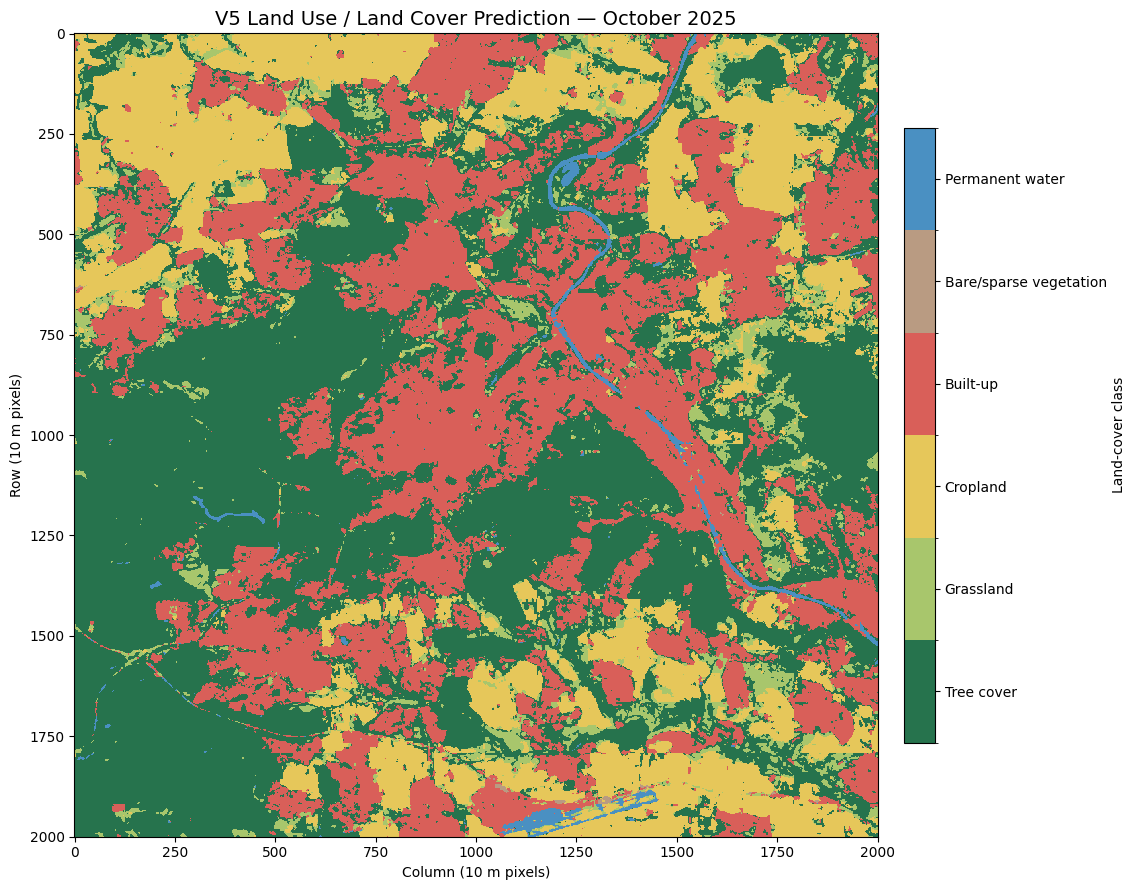


OCTOBER MAP VISUALIZATION COMPLETED.


In [16]:
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import rasterio
import numpy as np

map_path = OUTPUT_DIR / "lulc_2025_10_v5.tif"

class_names = [
    "Tree cover",
    "Grassland",
    "Cropland",
    "Built-up",
    "Bare/sparse vegetation",
    "Permanent water"
]

# Distinct categorical colors
class_colors = [
    "#26734D",
    "#A8C66C",
    "#E6C75A",
    "#D95F59",
    "#B99B82",
    "#4A90C2"
]

cmap = mcolors.ListedColormap(class_colors)
bounds = np.arange(0.5, 7.5, 1)
norm = mcolors.BoundaryNorm(bounds, cmap.N)

with rasterio.open(map_path) as src:

    lulc = src.read(1)

    print("Dimensions:", src.width, "x", src.height)
    print("CRS:", src.crs)
    print("Resolution:", src.res)
    print("Transform:", src.transform)
    print("NoData:", src.nodata)

    assert src.crs.to_string() == "EPSG:32632"
    assert src.width == 2001 and src.height == 2001
    assert src.res == (10.0, 10.0)

# Plot categorical map
fig, ax = plt.subplots(figsize=(11, 9))

im = ax.imshow(
    lulc,
    cmap=cmap,
    norm=norm,
    interpolation="nearest"
)

colorbar = fig.colorbar(
    im,
    ax=ax,
    ticks=np.arange(1, 7),
    fraction=0.035,
    pad=0.03
)

colorbar.ax.set_yticklabels(class_names)
colorbar.set_label("Land-cover class")

ax.set_title(
    "V5 Land Use / Land Cover Prediction — October 2025",
    fontsize=14
)
ax.set_xlabel("Column (10 m pixels)")
ax.set_ylabel("Row (10 m pixels)")

plt.tight_layout()
plt.show()

print("\nOCTOBER MAP VISUALIZATION COMPLETED.")

In [17]:
import numpy as np
import rasterio
import torch
import csv
from collections import Counter
from pathlib import Path

PATCH_SIZE = 128
BATCH_SIZE = 16

class_names = {
    1: "Tree cover",
    2: "Grassland",
    3: "Cropland",
    4: "Built-up",
    5: "Bare/sparse vegetation",
    6: "Permanent water"
}

medians = np.asarray(checkpoint["class_medians"], dtype=np.float32)
iqr = np.asarray(checkpoint["class_iqr"], dtype=np.float32)

def predict_month(month, input_path, output_path):

    with rasterio.open(input_path) as src:
        radar = src.read().astype(np.float32)
        profile = src.profile.copy()
        height, width = src.height, src.width
        nodata = src.nodata

    valid_mask = (
        np.isfinite(radar).all(axis=0) &
        (radar != nodata).all(axis=0)
    )

    assert valid_mask.all(), f"{month}: Invalid radar pixels"

    # V5 training normalization
    for band in range(2):
        radar[band] = (
            radar[band] - medians[band]
        ) / iqr[band]

    assert np.isfinite(radar).all()

    # Pad to 128-pixel multiples
    padded_height = (
        (height + PATCH_SIZE - 1) // PATCH_SIZE
    ) * PATCH_SIZE

    padded_width = (
        (width + PATCH_SIZE - 1) // PATCH_SIZE
    ) * PATCH_SIZE

    radar_padded = np.pad(
        radar,
        (
            (0, 0),
            (0, padded_height - height),
            (0, padded_width - width)
        ),
        mode="reflect"
    )

    prediction_padded = np.zeros(
        (padded_height, padded_width),
        dtype=np.uint8
    )

    locations = [
        (y, x)
        for y in range(0, padded_height, PATCH_SIZE)
        for x in range(0, padded_width, PATCH_SIZE)
    ]

    model.eval()

    with torch.no_grad():

        for start in range(0, len(locations), BATCH_SIZE):

            batch_locations = locations[start:start + BATCH_SIZE]

            batch = np.stack([
                radar_padded[
                    :,
                    y:y + PATCH_SIZE,
                    x:x + PATCH_SIZE
                ]
                for y, x in batch_locations
            ])

            batch_tensor = torch.from_numpy(batch).to(device)

            logits = model(batch_tensor)

            predictions = (
                torch.argmax(logits, dim=1)
                .cpu()
                .numpy()
                .astype(np.uint8)
            )

            for (y, x), pred_patch in zip(
                batch_locations, predictions
            ):
                prediction_padded[
                    y:y + PATCH_SIZE,
                    x:x + PATCH_SIZE
                ] = pred_patch + 1

    prediction = prediction_padded[:height, :width]

    assert prediction.shape == (height, width)
    assert set(np.unique(prediction)).issubset(
        {1, 2, 3, 4, 5, 6}
    )

    # Save georeferenced output
    profile.update(
        driver="GTiff",
        count=1,
        dtype="uint8",
        nodata=0,
        compress="LZW"
    )

    with rasterio.open(output_path, "w", **profile) as dst:
        dst.write(prediction, 1)

    # Calculate class percentages
    counts = Counter(prediction.ravel())
    total = prediction.size

    percentages = {
        class_id: counts.get(class_id, 0) / total * 100
        for class_id in class_names
    }

    return percentages


# --------------------------------------------------
# Process all 12 months
# --------------------------------------------------

results = []

for month in expected_months:

    output_path = OUTPUT_DIR / f"lulc_{month}_v5.tif"

    if output_path.exists():
        print(f"{month}: Existing output found; reusing it.")

        with rasterio.open(output_path) as src:
            prediction = src.read(1)

        assert prediction.shape == (2001, 2001)
        assert set(np.unique(prediction)).issubset(
            {1, 2, 3, 4, 5, 6}
        )

        counts = Counter(prediction.ravel())
        total = prediction.size

        percentages = {
            class_id: counts.get(class_id, 0) / total * 100
            for class_id in class_names
        }

    else:
        print(f"\nProcessing {month}...")

        percentages = predict_month(
            month,
            radar_paths[month],
            output_path
        )

    row = {"month": month}

    for class_id, name in class_names.items():
        row[name] = percentages[class_id]

    results.append(row)

    print(
        f"Completed {month} | "
        f"Tree: {percentages[1]:.2f}% | "
        f"Grass: {percentages[2]:.2f}% | "
        f"Crop: {percentages[3]:.2f}% | "
        f"Built: {percentages[4]:.2f}% | "
        f"Bare: {percentages[5]:.3f}% | "
        f"Water: {percentages[6]:.2f}%"
    )


# --------------------------------------------------
# Save monthly statistics
# --------------------------------------------------

csv_path = OUTPUT_DIR / "monthly_class_percentages_v5.csv"

with open(csv_path, "w", newline="") as f:

    writer = csv.DictWriter(
        f,
        fieldnames=["month"] + list(class_names.values())
    )

    writer.writeheader()
    writer.writerows(results)

print("\n" + "=" * 60)
print("ALL 12 MONTHLY PREDICTIONS COMPLETED")
print("=" * 60)
print("Maps:", OUTPUT_DIR)
print("Statistics:", csv_path)

2025_10: Existing output found; reusing it.
Completed 2025_10 | Tree: 44.19% | Grass: 5.94% | Crop: 18.99% | Built: 29.91% | Bare: 0.047% | Water: 0.92%

Processing 2025_11...
Completed 2025_11 | Tree: 41.53% | Grass: 9.03% | Crop: 18.66% | Built: 29.88% | Bare: 0.061% | Water: 0.85%

Processing 2025_12...
Completed 2025_12 | Tree: 42.20% | Grass: 8.97% | Crop: 17.59% | Built: 30.25% | Bare: 0.082% | Water: 0.91%

Processing 2026_01...
Completed 2026_01 | Tree: 41.29% | Grass: 8.46% | Crop: 19.72% | Built: 29.63% | Bare: 0.094% | Water: 0.81%

Processing 2026_02...
Completed 2026_02 | Tree: 43.35% | Grass: 7.85% | Crop: 17.34% | Built: 30.52% | Bare: 0.075% | Water: 0.86%

Processing 2026_03...
Completed 2026_03 | Tree: 43.20% | Grass: 7.58% | Crop: 17.45% | Built: 30.80% | Bare: 0.094% | Water: 0.88%

Processing 2026_04...
Completed 2026_04 | Tree: 42.35% | Grass: 9.16% | Crop: 18.83% | Built: 28.66% | Bare: 0.057% | Water: 0.93%

Processing 2026_05...
Completed 2026_05 | Tree: 43.09%

In [18]:
import pandas as pd
import numpy as np

# Load monthly class percentages
csv_path = OUTPUT_DIR / "monthly_class_percentages_v5.csv"

df = pd.read_csv(csv_path)

class_columns = [
    "Tree cover",
    "Grassland",
    "Cropland",
    "Built-up",
    "Bare/sparse vegetation",
    "Permanent water"
]

# Confirm all months are present
assert len(df) == 12
assert df["month"].is_unique

# --------------------------------------------------
# 1. Month-to-month percentage-point changes
# --------------------------------------------------

monthly_change = df.copy()

for col in class_columns:
    monthly_change[col] = df[col].diff()

monthly_change_path = (
    OUTPUT_DIR / "monthly_change_percentage_points_v5.csv"
)

monthly_change.to_csv(monthly_change_path, index=False)

# --------------------------------------------------
# 2. First month vs last month
# --------------------------------------------------

first = df.iloc[0]
last = df.iloc[-1]

total_change = pd.DataFrame({
    "Class": class_columns,
    "October_2025_percent": [
        first[col] for col in class_columns
    ],
    "September_2026_percent": [
        last[col] for col in class_columns
    ]
})

total_change["Change_percentage_points"] = (
    total_change["September_2026_percent"]
    - total_change["October_2025_percent"]
)

# Study area = 400 km²
STUDY_AREA_KM2 = 400.0

total_change["October_2025_km2"] = (
    total_change["October_2025_percent"] / 100
    * STUDY_AREA_KM2
)

total_change["September_2026_km2"] = (
    total_change["September_2026_percent"] / 100
    * STUDY_AREA_KM2
)

total_change["Net_area_change_km2"] = (
    total_change["September_2026_km2"]
    - total_change["October_2025_km2"]
)

total_change_path = (
    OUTPUT_DIR / "total_change_oct2025_sep2026_v5.csv"
)

total_change.to_csv(total_change_path, index=False)

# --------------------------------------------------
# 3. Display results
# --------------------------------------------------

print("=" * 75)
print("MONTH-TO-MONTH CHANGES (PERCENTAGE POINTS)")
print("=" * 75)

display(
    monthly_change[["month"] + class_columns].round(3)
)

print("\n" + "=" * 75)
print("TOTAL CHANGE: OCTOBER 2025 → SEPTEMBER 2026")
print("=" * 75)

display(
    total_change.round(3)
)

print("\nSaved:")
print(monthly_change_path)
print(total_change_path)

print("\nCHANGE ANALYSIS COMPLETED.")

MONTH-TO-MONTH CHANGES (PERCENTAGE POINTS)


,month,Tree cover,Grassland,Cropland,Built-up,Bare/sparse vegetation,Permanent water
0,2025_10,NaN,NaN,NaN,NaN,NaN,NaN
1,2025_11,-2.670,3.086,-0.331,-0.028,0.014,-0.072
2,2025_12,0.679,-0.057,-1.076,0.377,0.021,0.056
3,2026_01,-0.915,-0.508,2.136,-0.627,0.012,-0.097
4,2026_02,2.066,-0.613,-2.379,0.890,-0.019,0.055
5,2026_03,-0.153,-0.271,0.104,0.279,0.019,0.022
6,2026_04,-0.847,1.587,1.384,-2.136,-0.037,0.049
7,2026_05,0.736,-1.008,0.479,-0.193,-0.008,-0.005
8,2026_06,2.498,-0.462,-1.727,-0.302,0.023,-0.029
9,2026_07,-3.084,2.801,-2.558,2.739,0.010,0.093



TOTAL CHANGE: OCTOBER 2025 → SEPTEMBER 2026


,Class,October_2025_percent,September_2026_percent,Change_percentage_points,October_2025_km2,September_2026_km2,Net_area_change_km2
0,Tree cover,44.195,39.651,-4.544,176.780,158.605,-18.175
1,Grassland,5.940,10.515,4.575,23.759,42.061,18.302
2,Cropland,18.993,17.011,-1.981,75.971,68.045,-7.925
3,Built-up,29.905,31.763,1.857,119.621,127.050,7.429
4,Bare/sparse vegetation,0.047,0.062,0.016,0.187,0.250,0.063
5,Permanent water,0.921,0.997,0.077,3.683,3.989,0.306



Saved:
/home/jovyan/vault/Project/DeepLearning/sentinel1-lulc/prototype_outputs/monthly_change_percentage_points_v5.csv
/home/jovyan/vault/Project/DeepLearning/sentinel1-lulc/prototype_outputs/total_change_oct2025_sep2026_v5.csv

CHANGE ANALYSIS COMPLETED.


In [19]:
import pandas as pd
import rasterio

# Exact pixel-based study area
reference_map = OUTPUT_DIR / "lulc_2025_10_v5.tif"

with rasterio.open(reference_map) as src:
    pixel_area_m2 = abs(src.transform.a * src.transform.e)
    total_pixels = src.width * src.height

STUDY_AREA_KM2 = (
    pixel_area_m2 * total_pixels / 1_000_000
)

print(f"Pixel area: {pixel_area_m2:.2f} m²")
print(f"Total pixels: {total_pixels:,}")
print(f"Exact raster area: {STUDY_AREA_KM2:.4f} km²")

# Recalculate October-to-September area changes
df = pd.read_csv(
    OUTPUT_DIR / "monthly_class_percentages_v5.csv"
)

class_columns = [
    "Tree cover",
    "Grassland",
    "Cropland",
    "Built-up",
    "Bare/sparse vegetation",
    "Permanent water"
]

first = df.iloc[0]
last = df.iloc[-1]

total_change = pd.DataFrame({
    "Class": class_columns,
    "October_2025_percent": [first[c] for c in class_columns],
    "September_2026_percent": [last[c] for c in class_columns]
})

total_change["Change_percentage_points"] = (
    total_change["September_2026_percent"]
    - total_change["October_2025_percent"]
)

total_change["October_2025_km2"] = (
    total_change["October_2025_percent"]
    / 100 * STUDY_AREA_KM2
)

total_change["September_2026_km2"] = (
    total_change["September_2026_percent"]
    / 100 * STUDY_AREA_KM2
)

total_change["Net_area_change_km2"] = (
    total_change["September_2026_km2"]
    - total_change["October_2025_km2"]
)

total_change.to_csv(
    OUTPUT_DIR / "total_change_oct2025_sep2026_v5.csv",
    index=False
)

display(total_change.round(4))

print("\nAREA CALCULATIONS UPDATED.")

Pixel area: 100.00 m²
Total pixels: 4,004,001
Exact raster area: 400.4001 km²


,Class,October_2025_percent,September_2026_percent,Change_percentage_points,October_2025_km2,September_2026_km2,Net_area_change_km2
0,Tree cover,44.1949,39.6512,-4.5437,176.9565,158.7635,-18.1930
1,Grassland,5.9397,10.5152,4.5754,23.7827,42.1028,18.3201
2,Cropland,18.9926,17.0113,-1.9813,76.0465,68.1133,-7.9332
3,Built-up,29.9053,31.7626,1.8572,119.7409,127.1773,7.4364
4,Bare/sparse vegetation,0.0468,0.0625,0.0157,0.1872,0.2501,0.0629
5,Permanent water,0.9207,0.9973,0.0766,3.6863,3.9931,0.3068



AREA CALCULATIONS UPDATED.


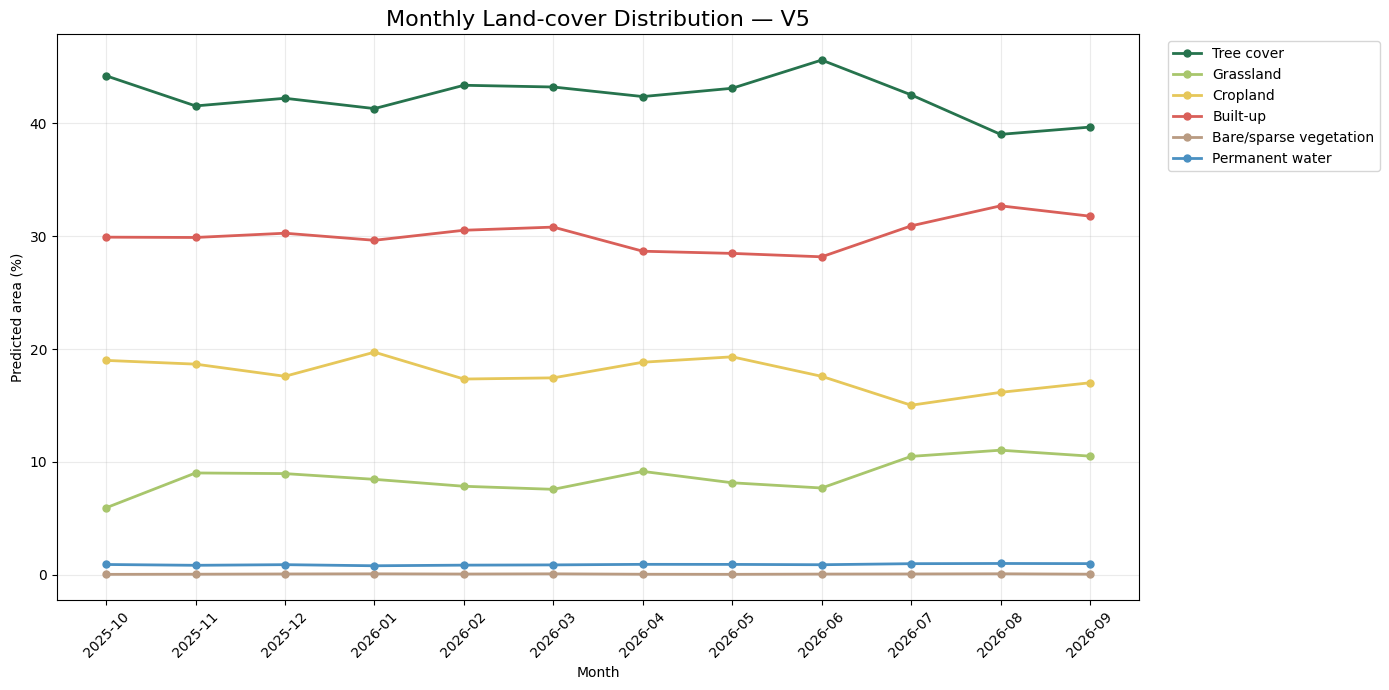

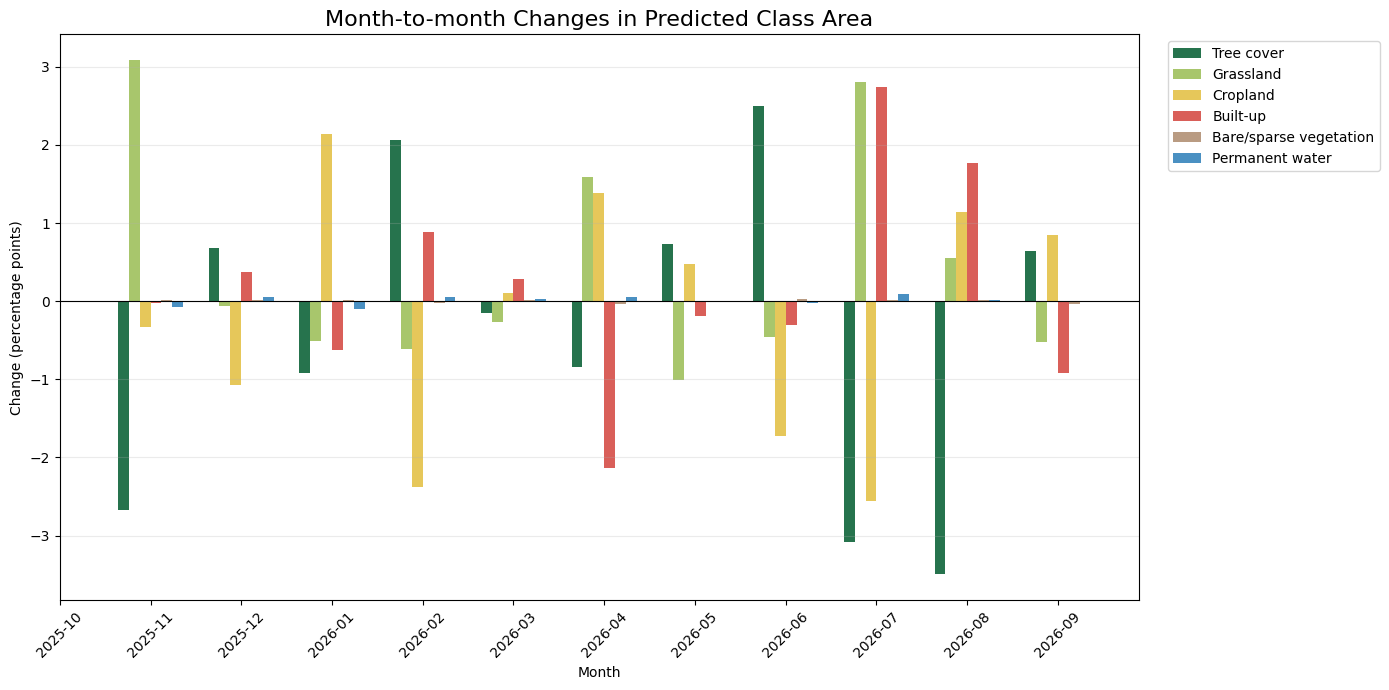

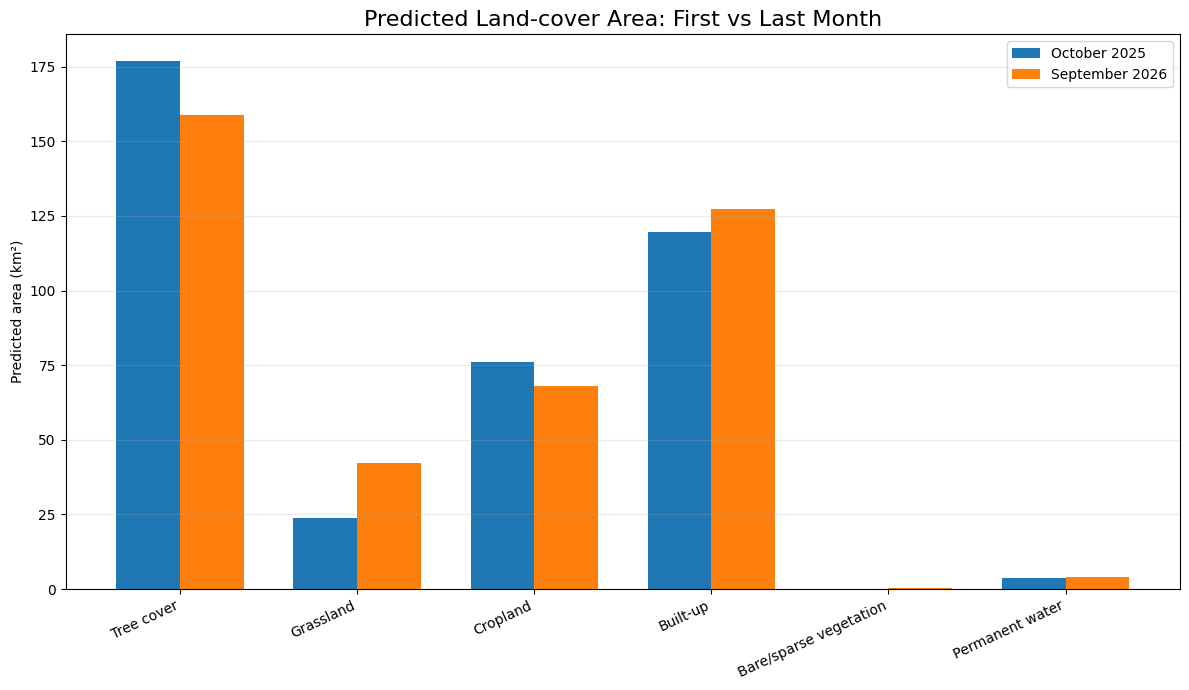


DASHBOARD CHARTS CREATED.
/home/jovyan/vault/Project/DeepLearning/sentinel1-lulc/prototype_outputs/monthly_class_trends_v5.png
/home/jovyan/vault/Project/DeepLearning/sentinel1-lulc/prototype_outputs/monthly_changes_v5.png
/home/jovyan/vault/Project/DeepLearning/sentinel1-lulc/prototype_outputs/first_vs_last_month_v5.png


In [20]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load results
df = pd.read_csv(
    OUTPUT_DIR / "monthly_class_percentages_v5.csv"
)

change_df = pd.read_csv(
    OUTPUT_DIR / "monthly_change_percentage_points_v5.csv"
)

total_df = pd.read_csv(
    OUTPUT_DIR / "total_change_oct2025_sep2026_v5.csv"
)

class_columns = [
    "Tree cover",
    "Grassland",
    "Cropland",
    "Built-up",
    "Bare/sparse vegetation",
    "Permanent water"
]

colors = {
    "Tree cover": "#26734D",
    "Grassland": "#A8C66C",
    "Cropland": "#E6C75A",
    "Built-up": "#D95F59",
    "Bare/sparse vegetation": "#B99B82",
    "Permanent water": "#4A90C2"
}

months = df["month"].str.replace("_", "-", regex=False)

# --------------------------------------------------
# Chart 1: Monthly class percentage trends
# --------------------------------------------------

fig, ax = plt.subplots(figsize=(14, 7))

for class_name in class_columns:
    ax.plot(
        months,
        df[class_name],
        marker="o",
        linewidth=2,
        markersize=5,
        label=class_name,
        color=colors[class_name]
    )

ax.set_title(
    "Monthly Land-cover Distribution — V5",
    fontsize=16
)
ax.set_xlabel("Month")
ax.set_ylabel("Predicted area (%)")
ax.grid(alpha=0.25)
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "monthly_class_trends_v5.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()


# --------------------------------------------------
# Chart 2: Month-to-month percentage-point changes
# --------------------------------------------------

fig, ax = plt.subplots(figsize=(14, 7))

x = np.arange(len(change_df))
width = 0.12

for i, class_name in enumerate(class_columns):
    offset = (i - len(class_columns) / 2) * width + width / 2

    ax.bar(
        x + offset,
        change_df[class_name],
        width,
        label=class_name,
        color=colors[class_name]
    )

ax.axhline(0, color="black", linewidth=0.8)

ax.set_title(
    "Month-to-month Changes in Predicted Class Area",
    fontsize=16
)
ax.set_xlabel("Month")
ax.set_ylabel("Change (percentage points)")
ax.set_xticks(x)
ax.set_xticklabels(months, rotation=45)
ax.grid(axis="y", alpha=0.25)
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left")

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "monthly_changes_v5.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()


# --------------------------------------------------
# Chart 3: October vs September comparison
# --------------------------------------------------

fig, ax = plt.subplots(figsize=(12, 7))

x = np.arange(len(class_columns))
width = 0.36

ax.bar(
    x - width / 2,
    total_df["October_2025_km2"],
    width,
    label="October 2025"
)

ax.bar(
    x + width / 2,
    total_df["September_2026_km2"],
    width,
    label="September 2026"
)

ax.set_title(
    "Predicted Land-cover Area: First vs Last Month",
    fontsize=16
)
ax.set_ylabel("Predicted area (km²)")
ax.set_xticks(x)
ax.set_xticklabels(class_columns, rotation=25, ha="right")
ax.legend()
ax.grid(axis="y", alpha=0.25)

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "first_vs_last_month_v5.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()


print("\nDASHBOARD CHARTS CREATED.")

for filename in [
    "monthly_class_trends_v5.png",
    "monthly_changes_v5.png",
    "first_vs_last_month_v5.png"
]:
    print(OUTPUT_DIR / filename)

PIXEL TRANSITION MATRIX


,To: Tree cover,To: Grassland,To: Cropland,To: Built-up,To: Bare/sparse vegetation,To: Permanent water
From: Tree cover,1485967,114321,40273,125218,48,3738
From: Grassland,17358,195264,17631,5815,374,1385
From: Cropland,36918,98165,616270,8246,578,288
From: Built-up,46340,12256,5494,1130250,593,2476
From: Bare/sparse vegetation,4,63,483,691,617,14
From: Permanent water,1048,959,982,1553,291,32030



SPATIAL CHANGE SUMMARY
Total pixels: 4,004,001
Changed pixels: 543,603
Unchanged pixels: 3,460,398
Changed percentage: 13.576%
Changed area: 54.3603 km²
Unchanged area: 346.0398 km²


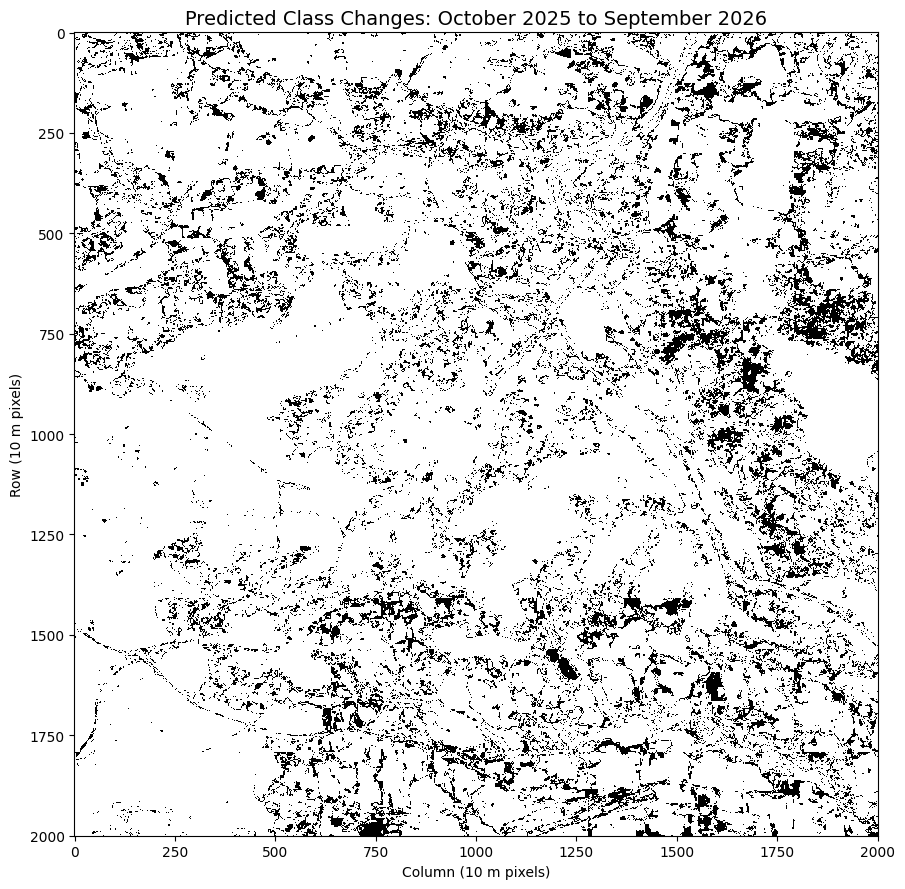


TRANSITION ANALYSIS COMPLETED.
Matrix: /home/jovyan/vault/Project/DeepLearning/sentinel1-lulc/prototype_outputs/transition_matrix_oct2025_sep2026_v5.csv
Transition details: /home/jovyan/vault/Project/DeepLearning/sentinel1-lulc/prototype_outputs/transition_details_oct2025_sep2026_v5.csv
Change raster: /home/jovyan/vault/Project/DeepLearning/sentinel1-lulc/prototype_outputs/change_map_oct2025_sep2026_v5.tif


In [21]:
import numpy as np
import pandas as pd
import rasterio
import matplotlib.pyplot as plt
from pathlib import Path

# --------------------------------------------------
# 1. Load first and last monthly maps
# --------------------------------------------------

oct_path = OUTPUT_DIR / "lulc_2025_10_v5.tif"
sep_path = OUTPUT_DIR / "lulc_2026_09_v5.tif"

with rasterio.open(oct_path) as src:
    oct_map = src.read(1)
    profile = src.profile.copy()
    transform = src.transform
    crs = src.crs

with rasterio.open(sep_path) as src:
    sep_map = src.read(1)

assert oct_map.shape == sep_map.shape
assert np.array_equal(oct_map == 0, sep_map == 0)

valid = (oct_map > 0) & (sep_map > 0)

assert valid.all(), "Unexpected NoData pixels found."

# --------------------------------------------------
# 2. Calculate transition matrix
# --------------------------------------------------

class_names = {
    1: "Tree cover",
    2: "Grassland",
    3: "Cropland",
    4: "Built-up",
    5: "Bare/sparse vegetation",
    6: "Permanent water"
}

from_ids = oct_map[valid].astype(np.int64)
to_ids = sep_map[valid].astype(np.int64)

transition_counts = np.zeros((6, 6), dtype=np.int64)

np.add.at(
    transition_counts,
    (from_ids - 1, to_ids - 1),
    1
)

transition_matrix = pd.DataFrame(
    transition_counts,
    index=[f"From: {class_names[i]}" for i in range(1, 7)],
    columns=[f"To: {class_names[i]}" for i in range(1, 7)]
)

print("PIXEL TRANSITION MATRIX")
display(transition_matrix)

# --------------------------------------------------
# 3. Changed and unchanged pixels
# --------------------------------------------------

changed = oct_map != sep_map
changed_count = int(changed.sum())
total_count = int(valid.sum())
unchanged_count = total_count - changed_count

pixel_area_km2 = (
    abs(transform.a * transform.e) / 1_000_000
)

changed_area_km2 = changed_count * pixel_area_km2
unchanged_area_km2 = unchanged_count * pixel_area_km2

print("\nSPATIAL CHANGE SUMMARY")
print("Total pixels:", f"{total_count:,}")
print("Changed pixels:", f"{changed_count:,}")
print("Unchanged pixels:", f"{unchanged_count:,}")
print("Changed percentage:", f"{changed_count / total_count * 100:.3f}%")
print("Changed area:", f"{changed_area_km2:.4f} km²")
print("Unchanged area:", f"{unchanged_area_km2:.4f} km²")

# --------------------------------------------------
# 4. Save transition matrix as CSV
# --------------------------------------------------

matrix_path = OUTPUT_DIR / "transition_matrix_oct2025_sep2026_v5.csv"

transition_matrix.to_csv(matrix_path)

# Save detailed transition areas
transition_rows = []

for i in range(6):
    for j in range(6):
        count = int(transition_counts[i, j])

        transition_rows.append({
            "From": class_names[i + 1],
            "To": class_names[j + 1],
            "Pixels": count,
            "Area_km2": count * pixel_area_km2,
            "Percentage_of_study_area": count / total_count * 100
        })

transition_details = pd.DataFrame(transition_rows)

transition_details = transition_details.sort_values(
    "Pixels",
    ascending=False
)

transition_details.to_csv(
    OUTPUT_DIR / "transition_details_oct2025_sep2026_v5.csv",
    index=False
)

# --------------------------------------------------
# 5. Save binary change raster
# 0 = unchanged, 1 = changed
# --------------------------------------------------

change_map = changed.astype(np.uint8)

change_profile = profile.copy()
change_profile.update(
    count=1,
    dtype="uint8",
    nodata=None,
    compress="LZW"
)

change_path = OUTPUT_DIR / "change_map_oct2025_sep2026_v5.tif"

with rasterio.open(change_path, "w", **change_profile) as dst:
    dst.write(change_map, 1)

# --------------------------------------------------
# 6. Visualize change map
# --------------------------------------------------

fig, ax = plt.subplots(figsize=(10, 9))

ax.imshow(
    change_map,
    cmap="gray_r",
    interpolation="nearest",
    vmin=0,
    vmax=1
)

ax.set_title(
    "Predicted Class Changes: October 2025 to September 2026",
    fontsize=14
)
ax.set_xlabel("Column (10 m pixels)")
ax.set_ylabel("Row (10 m pixels)")

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "spatial_change_map_v5.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("\nTRANSITION ANALYSIS COMPLETED.")
print("Matrix:", matrix_path)
print("Transition details:", OUTPUT_DIR / "transition_details_oct2025_sep2026_v5.csv")
print("Change raster:", change_path)

Created frame: 2025_10
Created frame: 2025_11
Created frame: 2025_12
Created frame: 2026_01
Created frame: 2026_02
Created frame: 2026_03
Created frame: 2026_04
Created frame: 2026_05
Created frame: 2026_06
Created frame: 2026_07
Created frame: 2026_08
Created frame: 2026_09

12-MONTH ANIMATION CREATED
Frames: 12
Output: /home/jovyan/vault/Project/DeepLearning/sentinel1-lulc/prototype_outputs/lulc_12_month_animation_v5.gif
File size: 0.69 MB


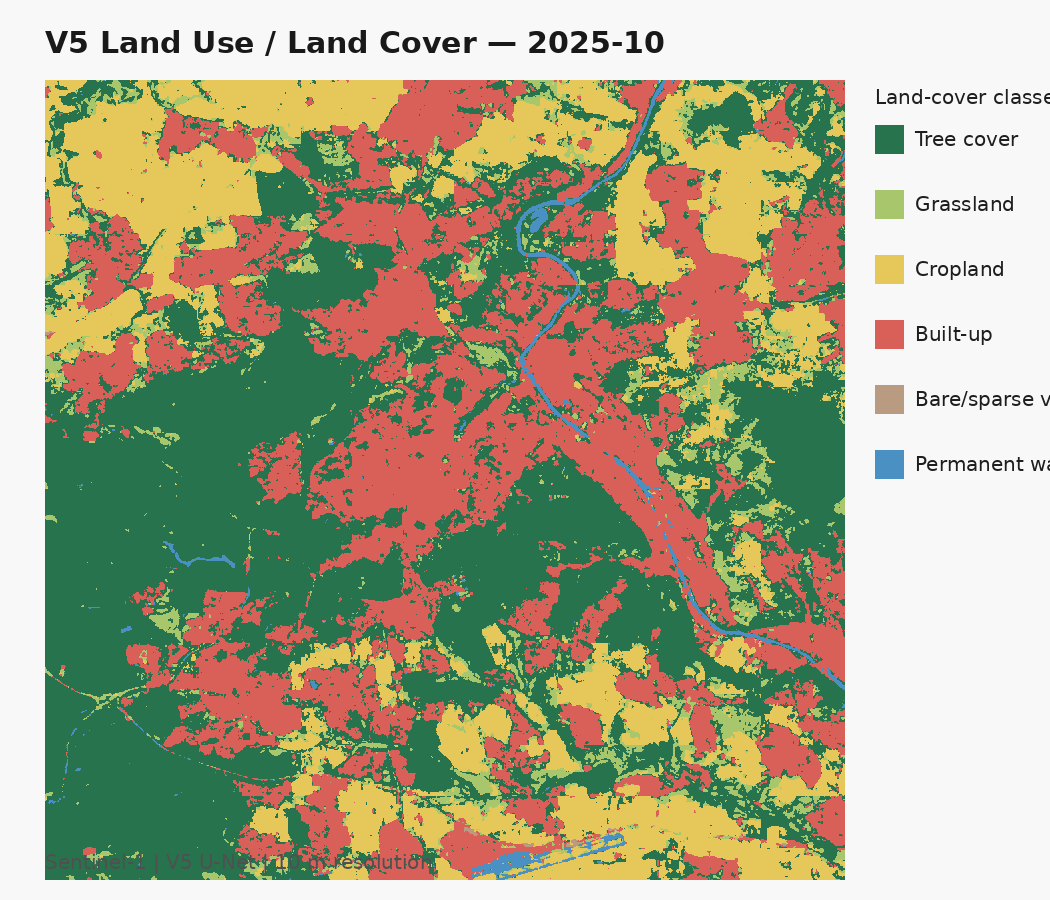


ANIMATION GENERATION COMPLETED.


In [22]:
import numpy as np
import rasterio
from PIL import Image, ImageDraw, ImageFont
from pathlib import Path

# --------------------------------------------------
# 1. Configuration
# --------------------------------------------------

gif_path = OUTPUT_DIR / "lulc_12_month_animation_v5.gif"

class_colors = {
    1: (38, 115, 77),       # Tree cover
    2: (168, 198, 108),     # Grassland
    3: (230, 199, 90),      # Cropland
    4: (217, 95, 89),       # Built-up
    5: (185, 155, 130),     # Bare/sparse vegetation
    6: (74, 144, 194)       # Permanent water
}

class_names = {
    1: "Tree cover",
    2: "Grassland",
    3: "Cropland",
    4: "Built-up",
    5: "Bare/sparse vegetation",
    6: "Permanent water"
}

MAP_SIZE = 800
CANVAS_WIDTH = 1050
CANVAS_HEIGHT = 900

frames = []

# Font
try:
    title_font = ImageFont.truetype(
        "/usr/share/fonts/truetype/dejavu/DejaVuSans-Bold.ttf",
        30
    )
    legend_font = ImageFont.truetype(
        "/usr/share/fonts/truetype/dejavu/DejaVuSans.ttf",
        20
    )
except OSError:
    title_font = ImageFont.load_default()
    legend_font = ImageFont.load_default()

# --------------------------------------------------
# 2. Create each monthly frame
# --------------------------------------------------

for month in expected_months:

    map_path = OUTPUT_DIR / f"lulc_{month}_v5.tif"

    assert map_path.exists(), f"Missing map: {map_path}"

    with rasterio.open(map_path) as src:

        lulc = src.read(1)

        assert src.crs.to_string() == "EPSG:32632"
        assert lulc.shape == (2001, 2001)

    # Convert class IDs to RGB
    rgb = np.zeros(
        (lulc.shape[0], lulc.shape[1], 3),
        dtype=np.uint8
    )

    for class_id, color in class_colors.items():
        rgb[lulc == class_id] = color

    # Resize using nearest-neighbour to preserve categories
    map_image = Image.fromarray(rgb).resize(
        (MAP_SIZE, MAP_SIZE),
        Image.Resampling.NEAREST
    )

    # Create frame
    frame = Image.new(
        "RGB",
        (CANVAS_WIDTH, CANVAS_HEIGHT),
        (248, 248, 248)
    )

    draw = ImageDraw.Draw(frame)

    # Title
    display_month = month.replace("_", "-")

    draw.text(
        (45, 25),
        f"V5 Land Use / Land Cover — {display_month}",
        fill=(25, 25, 25),
        font=title_font
    )

    # Map
    frame.paste(map_image, (45, 80))

    # Legend
    legend_x = 875
    legend_y = 125

    draw.text(
        (legend_x, 85),
        "Land-cover classes",
        fill=(30, 30, 30),
        font=legend_font
    )

    for class_id, name in class_names.items():

        y = legend_y + (class_id - 1) * 65

        draw.rectangle(
            (legend_x, y, legend_x + 28, y + 28),
            fill=class_colors[class_id]
        )

        draw.text(
            (legend_x + 40, y + 2),
            name,
            fill=(30, 30, 30),
            font=legend_font
        )

    # Footer
    draw.text(
        (45, 850),
        "Sentinel-1 | V5 U-Net | 10 m resolution",
        fill=(80, 80, 80),
        font=legend_font
    )

    frames.append(frame)

    print(f"Created frame: {month}")

# --------------------------------------------------
# 3. Save animated GIF
# --------------------------------------------------

frames[0].save(
    gif_path,
    save_all=True,
    append_images=frames[1:],
    duration=1200,
    loop=0,
    optimize=True
)

print("\n" + "=" * 55)
print("12-MONTH ANIMATION CREATED")
print("=" * 55)
print("Frames:", len(frames))
print("Output:", gif_path)
print("File size:", f"{gif_path.stat().st_size / 1024**2:.2f} MB")

# Display animation inside notebook
from IPython.display import display

display(Image.open(gif_path))

print("\nANIMATION GENERATION COMPLETED.")

Updated animation: /home/jovyan/vault/Project/DeepLearning/sentinel1-lulc/prototype_outputs/lulc_12_month_animation_v5.gif
Frames: 12
Dimensions: (1350, 960)
File size: 0.65 MB


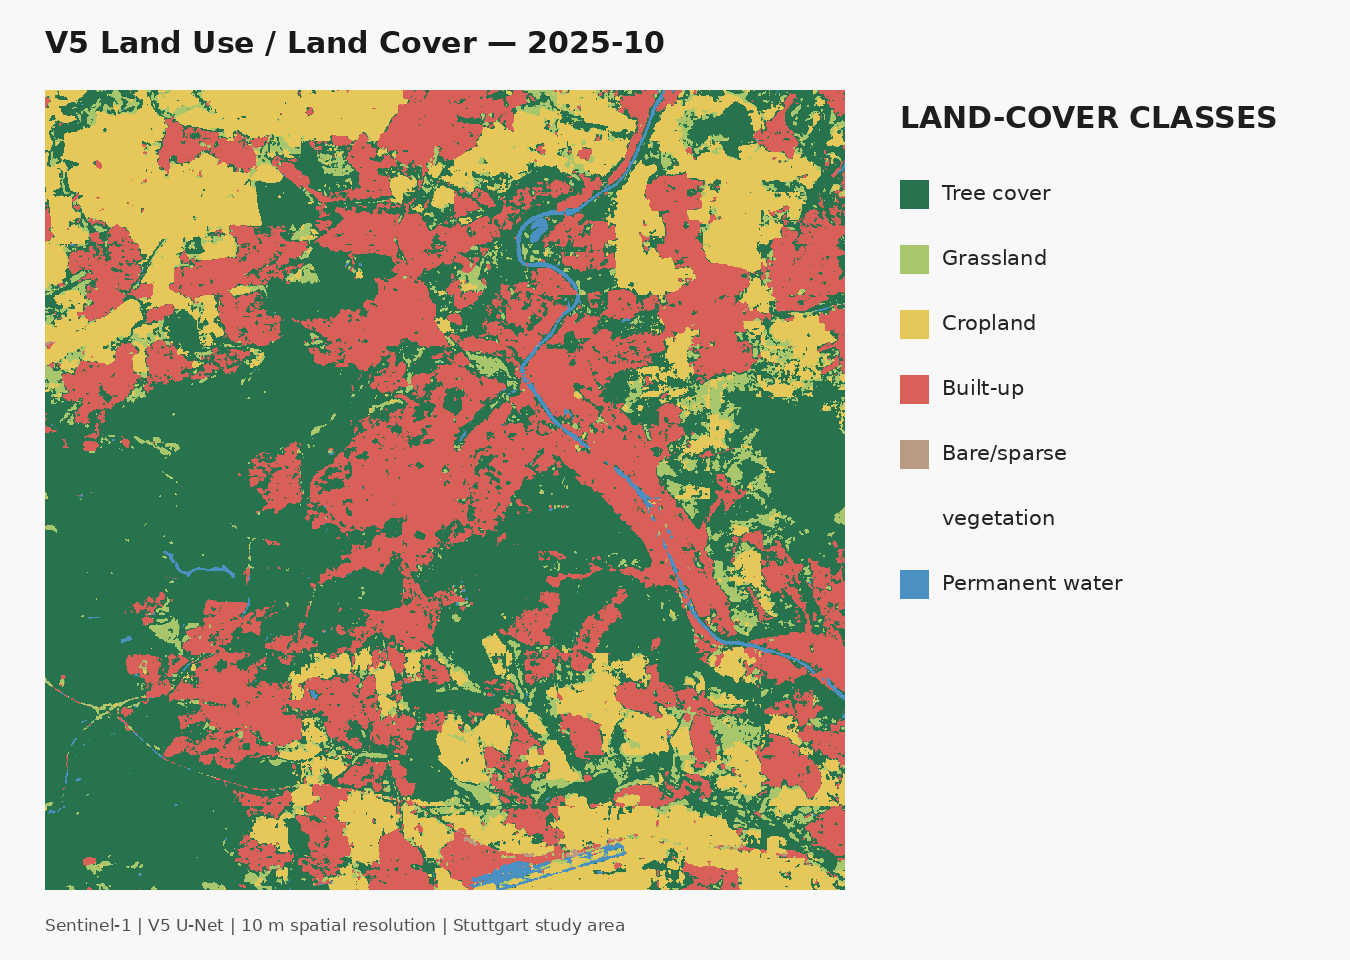

In [23]:
from PIL import Image, ImageDraw, ImageFont
import numpy as np
import rasterio

gif_path = OUTPUT_DIR / "lulc_12_month_animation_v5.gif"

MAP_SIZE = 800
CANVAS_WIDTH = 1350
CANVAS_HEIGHT = 960

try:
    title_font = ImageFont.truetype(
        "/usr/share/fonts/truetype/dejavu/DejaVuSans-Bold.ttf", 30
    )
    legend_font = ImageFont.truetype(
        "/usr/share/fonts/truetype/dejavu/DejaVuSans.ttf", 21
    )
    footer_font = ImageFont.truetype(
        "/usr/share/fonts/truetype/dejavu/DejaVuSans.ttf", 17
    )
except OSError:
    title_font = legend_font = footer_font = ImageFont.load_default()

frames = []

for month in expected_months:
    map_path = OUTPUT_DIR / f"lulc_{month}_v5.tif"

    with rasterio.open(map_path) as src:
        lulc = src.read(1)

    rgb = np.zeros((*lulc.shape, 3), dtype=np.uint8)

    for class_id, color in class_colors.items():
        rgb[lulc == class_id] = color

    map_image = Image.fromarray(rgb).resize(
        (MAP_SIZE, MAP_SIZE),
        Image.Resampling.NEAREST
    )

    frame = Image.new(
        "RGB",
        (CANVAS_WIDTH, CANVAS_HEIGHT),
        (248, 248, 248)
    )

    draw = ImageDraw.Draw(frame)

    # Title
    draw.text(
        (45, 25),
        f"V5 Land Use / Land Cover — {month.replace('_', '-')}",
        fill=(25, 25, 25),
        font=title_font
    )

    # Map
    frame.paste(map_image, (45, 90))

    # Legend
    legend_x = 900
    draw.text(
        (legend_x, 100),
        "LAND-COVER CLASSES",
        fill=(30, 30, 30),
        font=title_font
    )

    legend_items = [
        ("Tree cover", 1),
        ("Grassland", 2),
        ("Cropland", 3),
        ("Built-up", 4),
        ("Bare/sparse", 5),
        ("vegetation", 5),
        ("Permanent water", 6)
    ]

    for i, (label, class_id) in enumerate(legend_items):
        y = 180 + i * 65

        if label == "vegetation":
            draw.text(
                (legend_x + 42, y),
                label,
                fill=(35, 35, 35),
                font=legend_font
            )
        else:
            draw.rectangle(
                (legend_x, y, legend_x + 28, y + 28),
                fill=class_colors[class_id]
            )
            draw.text(
                (legend_x + 42, y),
                label,
                fill=(35, 35, 35),
                font=legend_font
            )

    # Footer, below the map
    draw.text(
        (45, 915),
        "Sentinel-1 | V5 U-Net | 10 m spatial resolution | Stuttgart study area",
        fill=(80, 80, 80),
        font=footer_font
    )

    frames.append(frame)

frames[0].save(
    gif_path,
    save_all=True,
    append_images=frames[1:],
    duration=1200,
    loop=0,
    optimize=True
)

check = Image.open(gif_path)

print("Updated animation:", gif_path)
print("Frames:", check.n_frames)
print("Dimensions:", check.size)
print("File size:", f"{gif_path.stat().st_size / 1024**2:.2f} MB")

display(check)

In [26]:
from pyproj import Transformer
from rasterio.transform import rowcol
from rasterio.windows import Window
import rasterio
import numpy as np

# --------------------------------------------------
# USER INPUT
# --------------------------------------------------

LATITUDE = 48.7758
LONGITUDE = 9.1829

AREA_SIZE_METRES = 1000
PIXEL_SIZE_METRES = 10

AREA_PIXELS = AREA_SIZE_METRES // PIXEL_SIZE_METRES

assert AREA_PIXELS == 100

# --------------------------------------------------
# REFERENCE RASTER
# --------------------------------------------------

reference_path = OUTPUT_DIR / "lulc_2025_10_v5.tif"

with rasterio.open(reference_path) as src:

    reference_transform = src.transform
    reference_crs = src.crs
    raster_height = src.height
    raster_width = src.width
    raster_bounds = src.bounds

# --------------------------------------------------
# CONVERT LAT/LON TO PROJECTED COORDINATES
# --------------------------------------------------

transformer = Transformer.from_crs(
    "EPSG:4326",
    reference_crs,
    always_xy=True
)

x, y = transformer.transform(LONGITUDE, LATITUDE)

center_row, center_col = rowcol(
    reference_transform,
    x,
    y
)

# --------------------------------------------------
# CREATE 100 x 100 PIXEL WINDOW
# --------------------------------------------------

half = AREA_PIXELS // 2

row_start = center_row - half
row_end = row_start + AREA_PIXELS

col_start = center_col - half
col_end = col_start + AREA_PIXELS

# --------------------------------------------------
# VALIDATE LOCATION AND WINDOW
# --------------------------------------------------

inside_study_area = (
    0 <= center_row < raster_height
    and 0 <= center_col < raster_width
)

window_inside = (
    row_start >= 0
    and col_start >= 0
    and row_end <= raster_height
    and col_end <= raster_width
)

print("=" * 55)
print("1 KM x 1 KM LOCATION VALIDATION")
print("=" * 55)

print(f"Latitude: {LATITUDE}")
print(f"Longitude: {LONGITUDE}")
print(f"Projected X: {x:.2f} m")
print(f"Projected Y: {y:.2f} m")

print(f"\nCentre pixel: row={center_row}, col={center_col}")
print(f"Selected window: {AREA_PIXELS} x {AREA_PIXELS}")
print(f"Row range: {row_start} to {row_end - 1}")
print(f"Column range: {col_start} to {col_end - 1}")

print("\nInside study area:", inside_study_area)
print("Entire selection inside raster:", window_inside)

if inside_study_area and window_inside:

    selection_window = Window(
        col_start,
        row_start,
        AREA_PIXELS,
        AREA_PIXELS
    )

    print("\nSELECTION VALIDATION PASSED.")

else:
    selection_window = None
    print("\nSELECTION INVALID: choose coordinates further inside the study area.")

1 KM x 1 KM LOCATION VALIDATION
Latitude: 48.7758
Longitude: 9.1829
Projected X: 513437.71 m
Projected Y: 5402549.15 m

Centre pixel: row=1000, col=1000
Selected window: 100 x 100
Row range: 950 to 1049
Column range: 950 to 1049

Inside study area: True
Entire selection inside raster: True

SELECTION VALIDATION PASSED.


In [27]:
import rasterio
import numpy as np
import pandas as pd
from rasterio.windows import Window

# Output directory for selected location
LOCATION_OUTPUT_DIR = OUTPUT_DIR / "selected_location_1km"
LOCATION_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

class_names = {
    1: "Tree cover",
    2: "Grassland",
    3: "Cropland",
    4: "Built-up",
    5: "Bare/sparse vegetation",
    6: "Permanent water"
}

monthly_results = []
selected_maps = {}

for month in expected_months:

    source_path = OUTPUT_DIR / f"lulc_{month}_v5.tif"

    with rasterio.open(source_path) as src:

        selected_map = src.read(
            1,
            window=selection_window
        )

        output_transform = src.window_transform(
            selection_window
        )

        profile = src.profile.copy()

    # Verify the extracted dimensions
    assert selected_map.shape == (100, 100)

    # Save selected-area GeoTIFF
    profile.update(
        height=100,
        width=100,
        transform=output_transform,
        compress="LZW"
    )

    output_path = (
        LOCATION_OUTPUT_DIR /
        f"lulc_{month}_selected_1km_v5.tif"
    )

    with rasterio.open(output_path, "w", **profile) as dst:
        dst.write(selected_map, 1)

    selected_maps[month] = selected_map

    # Calculate class percentages
    total_pixels = selected_map.size

    row = {"month": month}

    for class_id, class_name in class_names.items():

        count = int(np.sum(selected_map == class_id))

        row[class_name] = count / total_pixels * 100

    monthly_results.append(row)

    print(
        f"{month}: "
        f"Tree {row['Tree cover']:.2f}% | "
        f"Grass {row['Grassland']:.2f}% | "
        f"Crop {row['Cropland']:.2f}% | "
        f"Built {row['Built-up']:.2f}%"
    )

# Save selected-area statistics
selected_df = pd.DataFrame(monthly_results)

csv_path = (
    LOCATION_OUTPUT_DIR /
    "selected_location_monthly_percentages_v5.csv"
)

selected_df.to_csv(csv_path, index=False)

print("\n" + "=" * 55)
print("SELECTED AREA EXTRACTION COMPLETED")
print("=" * 55)
print("Monthly maps:", len(selected_maps))
print("Map dimensions: 100 x 100 pixels")
print("Area: 1 km x 1 km")
print("Output directory:", LOCATION_OUTPUT_DIR)
print("Statistics CSV:", csv_path)

display(selected_df.round(2))

2025_10: Tree 3.77% | Grass 1.28% | Crop 0.00% | Built 94.95%
2025_11: Tree 4.79% | Grass 2.54% | Crop 0.00% | Built 92.67%
2025_12: Tree 3.98% | Grass 1.57% | Crop 0.00% | Built 94.45%
2026_01: Tree 4.76% | Grass 1.82% | Crop 0.00% | Built 93.42%
2026_02: Tree 4.15% | Grass 1.50% | Crop 0.00% | Built 94.16%
2026_03: Tree 4.53% | Grass 1.48% | Crop 0.00% | Built 93.99%
2026_04: Tree 5.96% | Grass 2.60% | Crop 0.04% | Built 91.12%
2026_05: Tree 4.83% | Grass 1.89% | Crop 0.14% | Built 93.12%
2026_06: Tree 4.44% | Grass 2.69% | Crop 0.20% | Built 92.41%
2026_07: Tree 4.63% | Grass 1.26% | Crop 0.00% | Built 93.91%
2026_08: Tree 3.63% | Grass 1.66% | Crop 0.00% | Built 94.71%
2026_09: Tree 2.19% | Grass 2.18% | Crop 0.00% | Built 95.63%

SELECTED AREA EXTRACTION COMPLETED
Monthly maps: 12
Map dimensions: 100 x 100 pixels
Area: 1 km x 1 km
Output directory: /home/jovyan/vault/Project/DeepLearning/sentinel1-lulc/prototype_outputs/selected_location_1km
Statistics CSV: /home/jovyan/vault/Proj

,month,Tree cover,Grassland,Cropland,Built-up,Bare/sparse vegetation,Permanent water
0,2025_10,3.77,1.28,0.00,94.95,0.0,0.00
1,2025_11,4.79,2.54,0.00,92.67,0.0,0.00
2,2025_12,3.98,1.57,0.00,94.45,0.0,0.00
3,2026_01,4.76,1.82,0.00,93.42,0.0,0.00
4,2026_02,4.15,1.50,0.00,94.16,0.0,0.19
5,2026_03,4.53,1.48,0.00,93.99,0.0,0.00
6,2026_04,5.96,2.60,0.04,91.12,0.0,0.28
7,2026_05,4.83,1.89,0.14,93.12,0.0,0.02
8,2026_06,4.44,2.69,0.20,92.41,0.0,0.26
9,2026_07,4.63,1.26,0.00,93.91,0.0,0.20


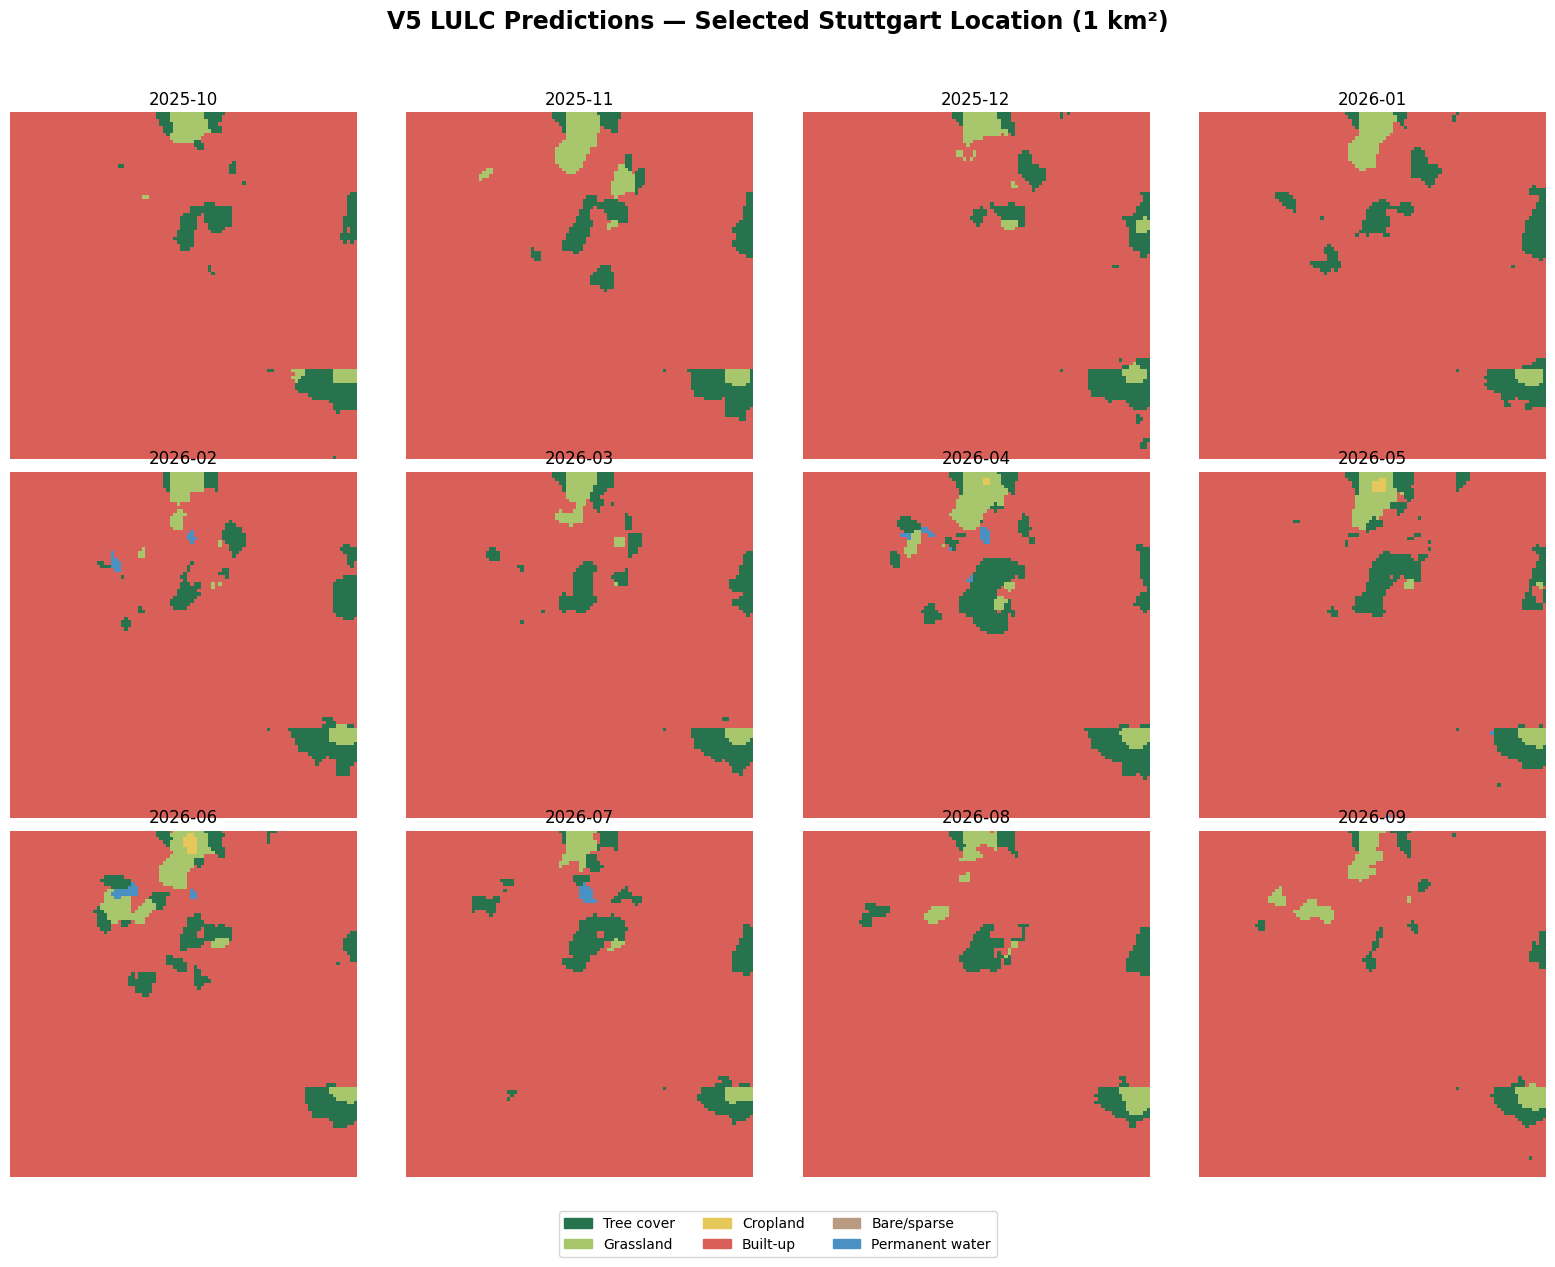

KeyError: 'Bare/sparse'

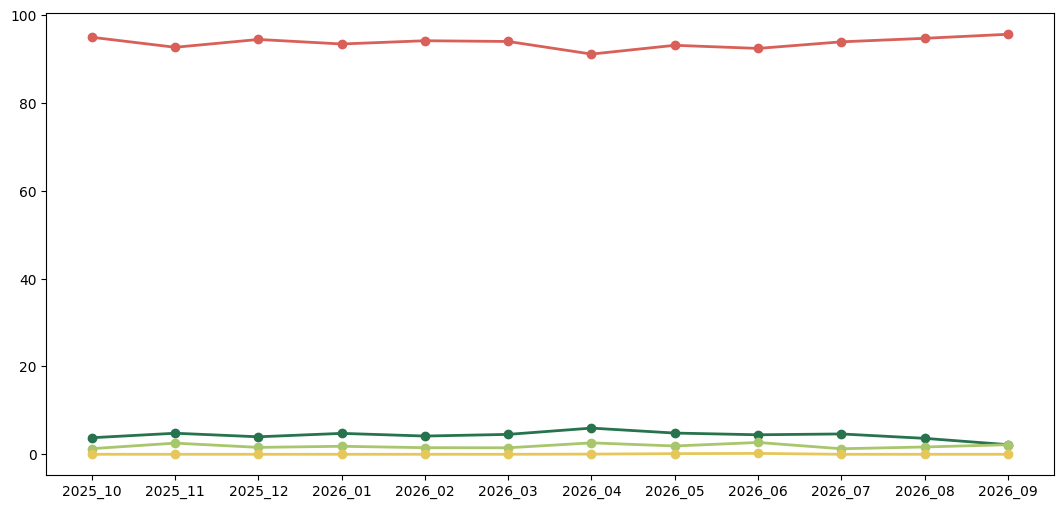

In [28]:
import matplotlib.pyplot as plt
import numpy as np

# Consistent class colours
class_colors = {
    1: "#26734D",
    2: "#A8C66C",
    3: "#E6C75A",
    4: "#D95F59",
    5: "#B99B82",
    6: "#4A90C2"
}

class_names = {
    1: "Tree cover",
    2: "Grassland",
    3: "Cropland",
    4: "Built-up",
    5: "Bare/sparse",
    6: "Permanent water"
}

# --------------------------------------------------
# 1. Create 12-map comparison
# --------------------------------------------------

fig, axes = plt.subplots(3, 4, figsize=(16, 13))

for ax, month in zip(axes.flat, expected_months):

    selected_map = selected_maps[month]

    rgb = np.zeros((100, 100, 3), dtype=np.float32)

    for class_id, hex_color in class_colors.items():
        color = tuple(
            int(hex_color[i:i+2], 16) / 255
            for i in (1, 3, 5)
        )
        rgb[selected_map == class_id] = color

    ax.imshow(rgb, interpolation="nearest")
    ax.set_title(month.replace("_", "-"))
    ax.axis("off")

fig.suptitle(
    "V5 LULC Predictions — Selected Stuttgart Location (1 km²)",
    fontsize=17,
    fontweight="bold"
)

legend_handles = [
    plt.Rectangle((0, 0), 1, 1, color=color, label=name)
    for class_id, color in class_colors.items()
    for name in [class_names[class_id]]
]

fig.legend(
    handles=legend_handles,
    loc="lower center",
    ncol=3,
    bbox_to_anchor=(0.5, 0.015)
)

plt.tight_layout(rect=[0, 0.07, 1, 0.95])

plt.savefig(
    LOCATION_OUTPUT_DIR / "selected_location_12_month_maps.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()


# --------------------------------------------------
# 2. Monthly percentage trends
# --------------------------------------------------

fig, ax = plt.subplots(figsize=(13, 6))

for class_id, class_name in class_names.items():

    ax.plot(
        selected_df["month"],
        selected_df[class_name],
        marker="o",
        linewidth=2,
        label=class_name,
        color=class_colors[class_id]
    )

ax.set_title(
    "Monthly LULC Distribution — Selected 1 km² Area",
    fontsize=15
)

ax.set_xlabel("Month")
ax.set_ylabel("Predicted area (%)")
ax.set_ylim(bottom=0)
ax.grid(alpha=0.25)
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left")

plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(
    LOCATION_OUTPUT_DIR / "selected_location_monthly_trends.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("SELECTED LOCATION VISUALIZATIONS COMPLETED.")
print("Output directory:", LOCATION_OUTPUT_DIR)


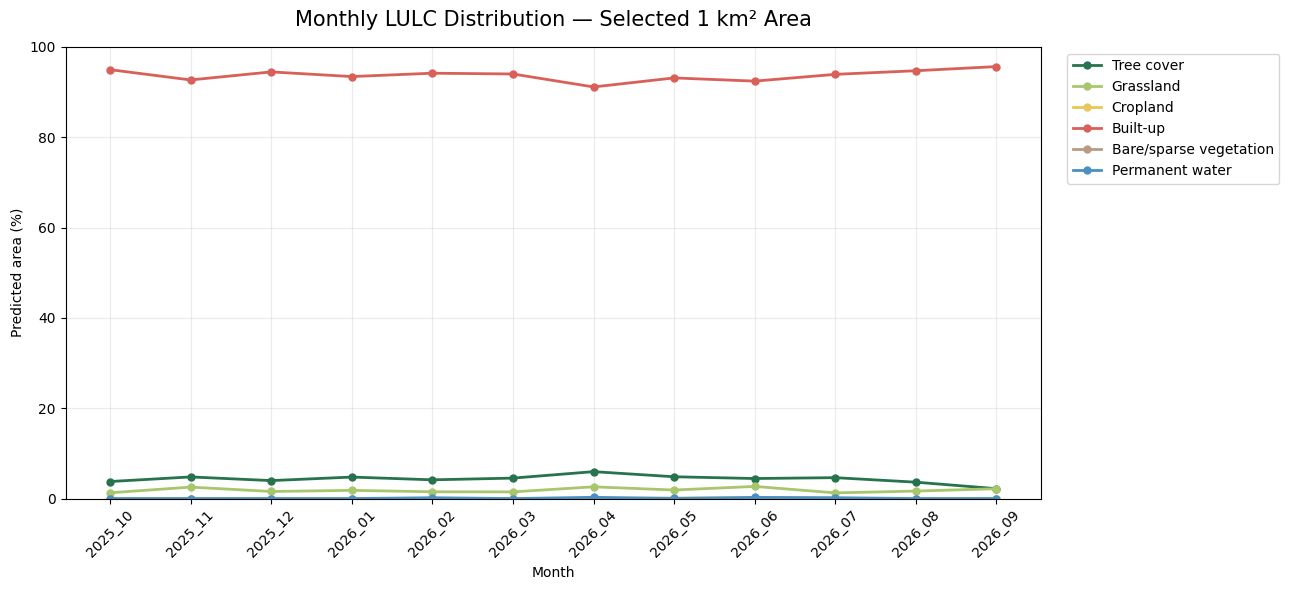

TREND CHART COMPLETED.


In [29]:
import matplotlib.pyplot as plt

# Match class IDs to the exact column names in selected_df
plot_classes = {
    1: ("Tree cover", "#26734D"),
    2: ("Grassland", "#A8C66C"),
    3: ("Cropland", "#E6C75A"),
    4: ("Built-up", "#D95F59"),
    5: ("Bare/sparse vegetation", "#B99B82"),
    6: ("Permanent water", "#4A90C2")
}

fig, ax = plt.subplots(figsize=(13, 6))

for class_id, (column_name, color) in plot_classes.items():

    if column_name not in selected_df.columns:
        print(f"Skipping missing column: {column_name}")
        continue

    ax.plot(
        selected_df["month"],
        selected_df[column_name],
        marker="o",
        linewidth=2,
        markersize=5,
        label=column_name,
        color=color
    )

ax.set_title(
    "Monthly LULC Distribution — Selected 1 km² Area",
    fontsize=15,
    pad=15
)

ax.set_xlabel("Month")
ax.set_ylabel("Predicted area (%)")
ax.set_ylim(0, 100)
ax.grid(alpha=0.25)
ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1))

plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(
    LOCATION_OUTPUT_DIR / "selected_location_monthly_trends.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("TREND CHART COMPLETED.")

Total pixels: 10,000
Unchanged: 9,611 (96.11%)
Changed:   389 (3.89%)
Changed area: 0.0389 km²


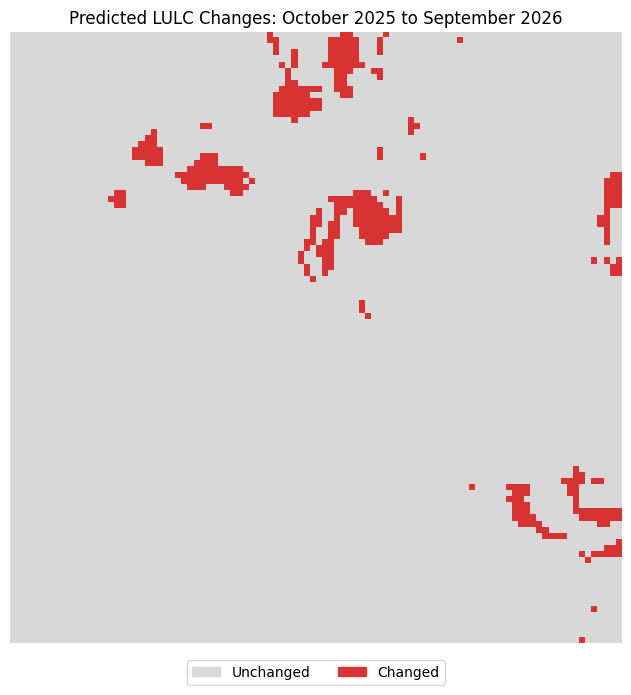

,Tree cover,Grassland,Cropland,Built-up,Bare/sparse,Permanent water
From / To,,,,,,
Tree cover,180,26,0,171,0,0
Grassland,1,83,0,44,0,0
Cropland,0,0,0,0,0,0
Built-up,38,109,0,9348,0,0
Bare/sparse,0,0,0,0,0,0
Permanent water,0,0,0,0,0,0


LOCAL CHANGE ANALYSIS COMPLETED.


In [30]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

# First and last monthly predictions
first_month = "2025_10"
last_month = "2026_09"

map_first = selected_maps[first_month]
map_last = selected_maps[last_month]

assert map_first.shape == (100, 100)
assert map_last.shape == (100, 100)

# Identify unchanged and changed pixels
changed = map_first != map_last

total_pixels = changed.size
changed_pixels = int(changed.sum())
unchanged_pixels = total_pixels - changed_pixels

print(f"Total pixels: {total_pixels:,}")
print(f"Unchanged: {unchanged_pixels:,} ({unchanged_pixels/total_pixels*100:.2f}%)")
print(f"Changed:   {changed_pixels:,} ({changed_pixels/total_pixels*100:.2f}%)")
print(f"Changed area: {changed_pixels * 100 / 1_000_000:.4f} km²")

# --------------------------------------------------
# 1. Binary change map
# --------------------------------------------------

change_rgb = np.zeros((100, 100, 3), dtype=np.float32)

# Unchanged = light grey
change_rgb[~changed] = [0.85, 0.85, 0.85]

# Changed = red
change_rgb[changed] = [0.85, 0.20, 0.20]

fig, ax = plt.subplots(figsize=(8, 7))
ax.imshow(change_rgb, interpolation="nearest")
ax.set_title("Predicted LULC Changes: October 2025 to September 2026")
ax.axis("off")

ax.legend(
    handles=[
        plt.Rectangle((0, 0), 1, 1, color=[0.85, 0.85, 0.85],
                      label="Unchanged"),
        plt.Rectangle((0, 0), 1, 1, color=[0.85, 0.20, 0.20],
                      label="Changed")
    ],
    loc="lower center",
    bbox_to_anchor=(0.5, -0.08),
    ncol=2
)

plt.tight_layout()

plt.savefig(
    LOCATION_OUTPUT_DIR / "selected_location_change_map.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

# --------------------------------------------------
# 2. Class-to-class transition matrix
# --------------------------------------------------

class_ids = list(range(1, 7))

transition_matrix = np.zeros((6, 6), dtype=np.int64)

for i, from_class in enumerate(class_ids):
    for j, to_class in enumerate(class_ids):
        transition_matrix[i, j] = np.sum(
            (map_first == from_class) &
            (map_last == to_class)
        )

transition_df = pd.DataFrame(
    transition_matrix,
    index=[class_names[i] for i in class_ids],
    columns=[class_names[i] for i in class_ids]
)

transition_df.index.name = "From / To"

display(transition_df)

transition_df.to_csv(
    LOCATION_OUTPUT_DIR / "selected_location_transition_matrix.csv"
)

print("LOCAL CHANGE ANALYSIS COMPLETED.")

TEMPORAL STABILITY SUMMARY
Stable all 12 months: 8,692 (86.92%)
Changed class twice or more: 183 (1.83%)
Changed class once: 1,125 (11.25%)


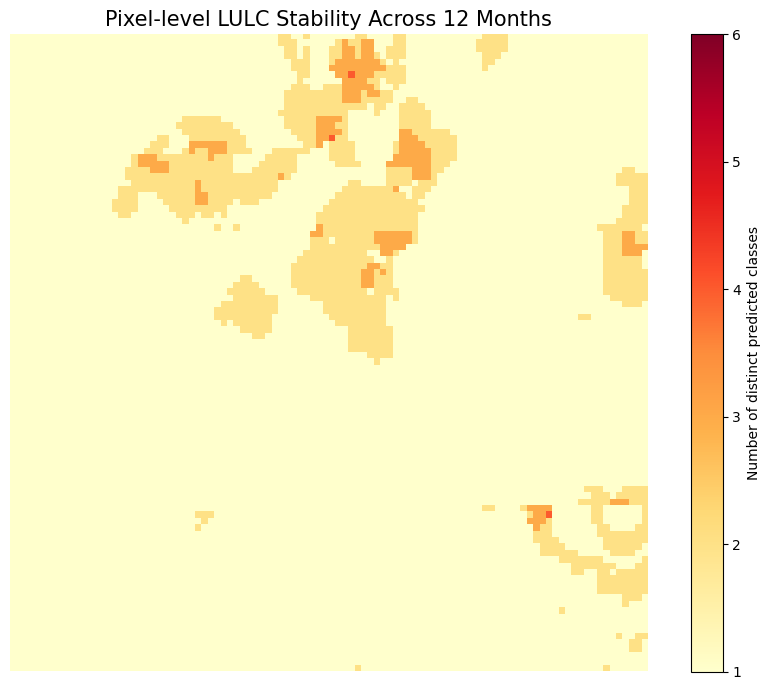

In [31]:
import numpy as np
import matplotlib.pyplot as plt

# Stack the 12 monthly maps
monthly_stack = np.stack(
    [selected_maps[m] for m in expected_months],
    axis=0
)

assert monthly_stack.shape == (12, 100, 100)

# Count how many distinct predicted classes each pixel has
unique_class_count = np.zeros((100, 100), dtype=np.uint8)

for r in range(100):
    for c in range(100):
        unique_class_count[r, c] = len(
            np.unique(monthly_stack[:, r, c])
        )

# Count pixels by temporal stability
stability_counts = {
    "Stable all 12 months": int(np.sum(unique_class_count == 1)),
    "Changed class twice or more": int(np.sum(unique_class_count >= 3)),
    "Changed class once": int(np.sum(unique_class_count == 2))
}

print("TEMPORAL STABILITY SUMMARY")

for label, count in stability_counts.items():
    print(f"{label}: {count:,} ({count/10000*100:.2f}%)")

# Visualize the number of distinct classes per pixel
fig, ax = plt.subplots(figsize=(9, 7))

im = ax.imshow(
    unique_class_count,
    cmap="YlOrRd",
    vmin=1,
    vmax=6,
    interpolation="nearest"
)

ax.set_title(
    "Pixel-level LULC Stability Across 12 Months",
    fontsize=15
)

ax.axis("off")

cbar = plt.colorbar(im, ax=ax, ticks=range(1, 7))
cbar.set_label("Number of distinct predicted classes")

plt.tight_layout()

plt.savefig(
    LOCATION_OUTPUT_DIR / "selected_location_temporal_stability.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

MONTH-TO-MONTH CLASSIFICATION SWITCHES
--------------------------------------
 0 switches: 8,692 pixels (86.92%)
 1 switches:    59 pixels (0.59%)
 2 switches:   472 pixels (4.72%)
 3 switches:   149 pixels (1.49%)
 4 switches:   311 pixels (3.11%)
 5 switches:   129 pixels (1.29%)
 6 switches:   111 pixels (1.11%)
 7 switches:    48 pixels (0.48%)
 8 switches:    16 pixels (0.16%)
 9 switches:    13 pixels (0.13%)
10 switches:     0 pixels (0.00%)
11 switches:     0 pixels (0.00%)
--------------------------------------
Pixels with at least one switch: 1,308
Mean switches per pixel: 0.459


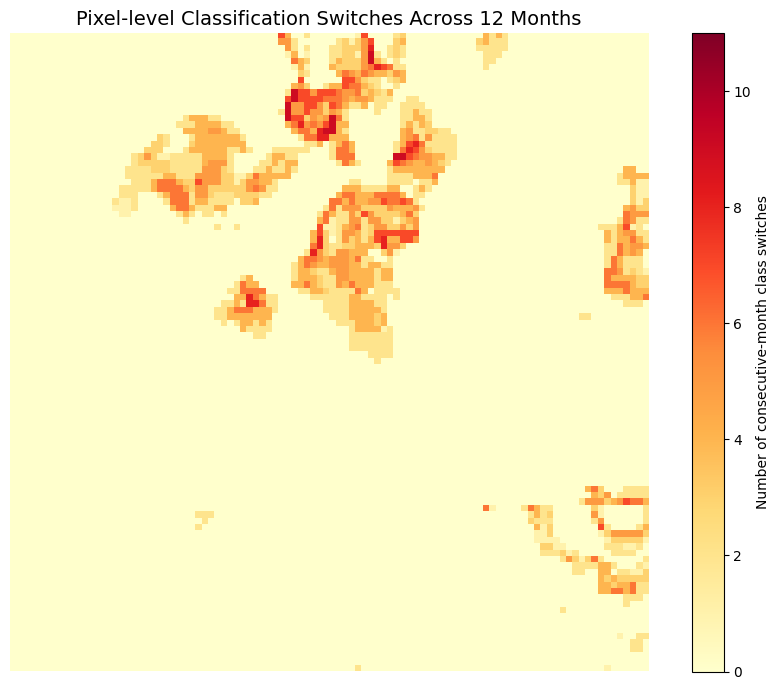

MONTHLY SWITCH ANALYSIS COMPLETED.


In [32]:
import numpy as np
import matplotlib.pyplot as plt

# Count class switches between consecutive months
monthly_switches = np.sum(
    monthly_stack[1:] != monthly_stack[:-1],
    axis=0
)

# Summary statistics
total_pixels = monthly_switches.size

print("MONTH-TO-MONTH CLASSIFICATION SWITCHES")
print("--------------------------------------")

for n in range(12):
    count = int(np.sum(monthly_switches == n))
    percentage = count / total_pixels * 100

    print(
        f"{n:2d} switches: "
        f"{count:5,} pixels ({percentage:.2f}%)"
    )

print("--------------------------------------")
print(
    "Pixels with at least one switch:",
    f"{np.sum(monthly_switches > 0):,}"
)

print(
    "Mean switches per pixel:",
    round(float(monthly_switches.mean()), 3)
)

# Visualize switch frequency
fig, ax = plt.subplots(figsize=(9, 7))

im = ax.imshow(
    monthly_switches,
    cmap="YlOrRd",
    vmin=0,
    vmax=11,
    interpolation="nearest"
)

ax.set_title(
    "Pixel-level Classification Switches Across 12 Months",
    fontsize=14
)

ax.axis("off")

cbar = plt.colorbar(im, ax=ax)
cbar.set_label("Number of consecutive-month class switches")

plt.tight_layout()

plt.savefig(
    LOCATION_OUTPUT_DIR / "selected_location_monthly_switches.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("MONTHLY SWITCH ANALYSIS COMPLETED.")

,period,changed_pixels,changed_area_hectares,changed_percentage
8,2026_06 → 2026_07,595,5.95,5.95
5,2026_03 → 2026_04,514,5.14,5.14
7,2026_05 → 2026_06,498,4.98,4.98
6,2026_04 → 2026_05,450,4.50,4.50
1,2025_11 → 2025_12,405,4.05,4.05
0,2025_10 → 2025_11,383,3.83,3.83
9,2026_07 → 2026_08,371,3.71,3.71
10,2026_08 → 2026_09,363,3.63,3.63
3,2026_01 → 2026_02,363,3.63,3.63
2,2025_12 → 2026_01,341,3.41,3.41


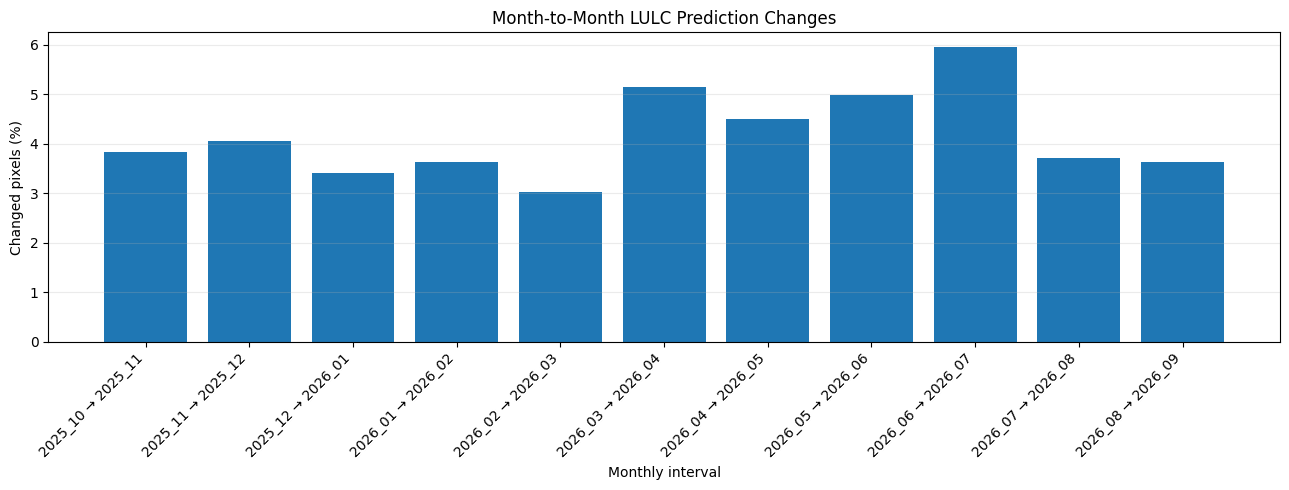

MONTH-TO-MONTH CHANGE ANALYSIS COMPLETED.


In [33]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

monthly_change_results = []

for i in range(1, len(expected_months)):

    previous_map = monthly_stack[i - 1]
    current_map = monthly_stack[i]

    changed_mask = previous_map != current_map

    changed_pixels = int(changed_mask.sum())
    changed_percentage = changed_pixels / changed_mask.size * 100

    monthly_change_results.append({
        "period": f"{expected_months[i-1]} → {expected_months[i]}",
        "changed_pixels": changed_pixels,
        "changed_area_hectares": changed_pixels * 0.01,
        "changed_percentage": changed_percentage
    })

monthly_change_df = pd.DataFrame(monthly_change_results)

display(
    monthly_change_df.round(3).sort_values(
        "changed_percentage",
        ascending=False
    )
)

monthly_change_df.to_csv(
    LOCATION_OUTPUT_DIR / "month_to_month_pixel_changes.csv",
    index=False
)

# Plot consecutive-month changes
fig, ax = plt.subplots(figsize=(13, 5))

ax.bar(
    monthly_change_df["period"],
    monthly_change_df["changed_percentage"]
)

ax.set_title("Month-to-Month LULC Prediction Changes")
ax.set_ylabel("Changed pixels (%)")
ax.set_xlabel("Monthly interval")
ax.grid(axis="y", alpha=0.25)

plt.xticks(rotation=45, ha="right")
plt.tight_layout()

plt.savefig(
    LOCATION_OUTPUT_DIR / "month_to_month_change_trend.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("MONTH-TO-MONTH CHANGE ANALYSIS COMPLETED.")

In [34]:
import numpy as np
import pandas as pd

class_ids = list(range(1, 7))

def calculate_interval_transitions(previous_map, current_map):

    matrix = np.zeros((6, 6), dtype=np.int64)

    for i, from_class in enumerate(class_ids):
        for j, to_class in enumerate(class_ids):

            matrix[i, j] = np.sum(
                (previous_map == from_class) &
                (current_map == to_class)
            )

    return matrix


# Compare the two highest-change intervals
intervals = [
    ("2026_03", "2026_04"),
    ("2026_06", "2026_07")
]

for start_month, end_month in intervals:

    start_idx = expected_months.index(start_month)
    end_idx = expected_months.index(end_month)

    matrix = calculate_interval_transitions(
        monthly_stack[start_idx],
        monthly_stack[end_idx]
    )

    transition_df = pd.DataFrame(
        matrix,
        index=[class_names[i] for i in class_ids],
        columns=[class_names[i] for i in class_ids]
    )

    transition_df.index.name = "From / To"

    print(f"\nTRANSITIONS: {start_month} → {end_month}")
    display(transition_df)

    # Extract only changed-class transitions
    transitions = []

    for i, from_class in enumerate(class_ids):
        for j, to_class in enumerate(class_ids):

            if i != j and matrix[i, j] > 0:
                transitions.append({
                    "from_class": class_names[from_class],
                    "to_class": class_names[to_class],
                    "pixels": int(matrix[i, j]),
                    "area_hectares": matrix[i, j] * 0.01
                })

    transitions_df = pd.DataFrame(transitions)

    transitions_df = transitions_df.sort_values(
        "pixels",
        ascending=False
    )

    print("Largest classification transitions:")
    display(transitions_df)

    filename = (
        f"transitions_{start_month}_to_{end_month}.csv"
    )

    transitions_df.to_csv(
        LOCATION_OUTPUT_DIR / filename,
        index=False
    )

print("INTERVAL TRANSITION ANALYSIS COMPLETED.")


TRANSITIONS: 2026_03 → 2026_04


,Tree cover,Grassland,Cropland,Built-up,Bare/sparse,Permanent water
From / To,,,,,,
Tree cover,331,37,0,83,0,2
Grassland,0,135,4,9,0,0
Cropland,0,0,0,0,0,0
Built-up,265,88,0,9020,0,26
Bare/sparse,0,0,0,0,0,0
Permanent water,0,0,0,0,0,0


Largest classification transitions:


,from_class,to_class,pixels,area_hectares
5,Built-up,Tree cover,265,2.65
6,Built-up,Grassland,88,0.88
1,Tree cover,Built-up,83,0.83
0,Tree cover,Grassland,37,0.37
7,Built-up,Permanent water,26,0.26
4,Grassland,Built-up,9,0.09
3,Grassland,Cropland,4,0.04
2,Tree cover,Permanent water,2,0.02



TRANSITIONS: 2026_06 → 2026_07


,Tree cover,Grassland,Cropland,Built-up,Bare/sparse,Permanent water
From / To,,,,,,
Tree cover,259,6,0,179,0,0
Grassland,27,96,0,145,0,1
Cropland,0,19,0,1,0,0
Built-up,177,5,0,9045,0,14
Bare/sparse,0,0,0,0,0,0
Permanent water,0,0,0,21,0,5


Largest classification transitions:


,from_class,to_class,pixels,area_hectares
1,Tree cover,Built-up,179,1.79
7,Built-up,Tree cover,177,1.77
3,Grassland,Built-up,145,1.45
2,Grassland,Tree cover,27,0.27
10,Permanent water,Built-up,21,0.21
5,Cropland,Grassland,19,0.19
9,Built-up,Permanent water,14,0.14
0,Tree cover,Grassland,6,0.06
8,Built-up,Grassland,5,0.05
6,Cropland,Built-up,1,0.01


INTERVAL TRANSITION ANALYSIS COMPLETED.


In [35]:
from pathlib import Path
import shutil
import pandas as pd

PROJECT_DIR = Path.cwd()

SOURCE_DIR = PROJECT_DIR / "prototype_outputs" / "selected_location_1km"

BACKUP_DIR = (
    PROJECT_DIR
    / "deliverables_v5"
    / "local_location_analysis"
)

assert SOURCE_DIR.exists(), f"Missing source: {SOURCE_DIR}"

BACKUP_DIR.mkdir(parents=True, exist_ok=True)

# Copy the complete selected-location analysis
for source_file in SOURCE_DIR.iterdir():

    if source_file.is_file():
        shutil.copy2(
            source_file,
            BACKUP_DIR / source_file.name
        )

# Create a file inventory
inventory = []

for file_path in sorted(BACKUP_DIR.iterdir()):

    if file_path.is_file():
        inventory.append({
            "filename": file_path.name,
            "size_kb": round(file_path.stat().st_size / 1024, 2)
        })

inventory_df = pd.DataFrame(inventory)

display(inventory_df)

inventory_df.to_csv(
    BACKUP_DIR / "file_inventory.csv",
    index=False
)

print("\nSNAPSHOT CREATED SUCCESSFULLY")
print("Backup directory:", BACKUP_DIR)
print("Files copied:", len(inventory))


,filename,size_kb
0,lulc_2025_10_selected_1km_v5.tif,1.30
1,lulc_2025_11_selected_1km_v5.tif,1.39
2,lulc_2025_12_selected_1km_v5.tif,1.34
3,lulc_2026_01_selected_1km_v5.tif,1.37
4,lulc_2026_02_selected_1km_v5.tif,1.38
5,lulc_2026_03_selected_1km_v5.tif,1.36
6,lulc_2026_04_selected_1km_v5.tif,1.45
7,lulc_2026_05_selected_1km_v5.tif,1.39
8,lulc_2026_06_selected_1km_v5.tif,1.44
9,lulc_2026_07_selected_1km_v5.tif,1.37



SNAPSHOT CREATED SUCCESSFULLY
Backup directory: /home/jovyan/vault/Project/DeepLearning/sentinel1-lulc/deliverables_v5/local_location_analysis
Files copied: 23


In [36]:
from pathlib import Path

PROJECT_DIR = Path.cwd()
DELIVERABLE_DIR = PROJECT_DIR / "deliverables_v5"
DELIVERABLE_DIR.mkdir(parents=True, exist_ok=True)

readme = r"""
# Sentinel-1-Based Land Use and Land Cover (LULC) Prototype

## 1. Project Overview

This project implements a deep-learning-based semantic segmentation
prototype for Land Use and Land Cover (LULC) mapping using Sentinel-1
VV and VH radar imagery.

The trained model generates monthly LULC predictions and calculates
class distribution, temporal differences, and spatial transitions.

The current prototype uses pre-generated monthly Stuttgart prediction
maps and supports selection of a 1 km x 1 km area within the study area.

## 2. Study Area and Observation Period

- Study area: Stuttgart, Germany
- Original study extent: approximately 20 km x 20 km
- Coordinate reference system: EPSG:32632
- Spatial resolution: 10 metres
- Observation period: October 2025 – September 2026
- Monthly observations: 12

## 3. Data Sources

### Sentinel-1

- Dataset: COPERNICUS/S1_GRD
- Instrument mode: IW
- Orbit direction: Descending
- Polarizations: VV and VH
- Monthly compositing: Median
- Spatial resolution: 10 metres

### Reference Labels

- Dataset: ESA WorldCover v200
- Reference year: 2021
- Original classification labels remapped to six classes.

## 4. LULC Classes

| Model ID | Class |
|---|---|
| 1 | Tree cover |
| 2 | Grassland |
| 3 | Cropland |
| 4 | Built-up |
| 5 | Bare/sparse vegetation |
| 6 | Permanent water |

Wetland class 90 was excluded from model training.

## 5. Deep Learning Model

- Architecture: U-Net
- Input channels: 2 (VV and VH)
- Output classes: 6
- Base channels: 16
- Framework: PyTorch
- Optimizer: AdamW
- Learning rate: 0.001
- Weight decay: 0.0001
- Batch size: 4
- Maximum epochs: 30

### V5 Training

The V5 training dataset combines the original training locations
with additional training patches from an expanded geographic area.

- Original training locations: 90
- Additional outer-ring locations: 600
- Unique training locations: 690
- Monthly observations per location: 12

Validation and test locations were retained from the original
spatial split.

### V5 Evaluation

| Metric | Result |
|---|---:|
| Test loss | 0.7013 |
| Overall accuracy | 0.7190 |
| Mean IoU | 0.4734 |

Bare/sparse vegetation was not reliably detected.

## 6. Prototype Workflow

1. Load the trained V5 checkpoint.
2. Load the 12 monthly Sentinel-1 prediction inputs.
3. Apply the training normalization parameters.
4. Generate monthly LULC predictions.
5. Save monthly prediction maps as GeoTIFF files.
6. Calculate class percentages and area statistics.
7. Calculate month-to-month changes.
8. Compare the first and last monthly predictions.
9. Generate transition matrices and temporal stability maps.
10. Select a 1 km x 1 km location from the existing prediction maps.

## 7. Location-Based Analysis

The current prototype supports selection of a 1 km x 1 km window
from the existing Stuttgart prediction maps using latitude and
longitude.

It generates:

- 12 monthly local LULC maps
- Monthly class percentages
- Monthly change statistics
- First-to-last change map
- Class transition matrix
- Temporal stability map
- Consecutive-month classification switch analysis

Important: this implementation extracts from existing prediction
rasters. It does not yet support arbitrary geographic locations or
automatic live Sentinel-1 acquisition.

## 8. Current Local Analysis Results

Selected area: 1 km x 1 km

Observation period: October 2025 – September 2026

| Metric | Result |
|---|---:|
| Pixels | 10,000 |
| Stable across all 12 months | 86.92% |
| Pixels changing at least once | 13.08% |
| Mean consecutive-month switches | 0.459 |
| October-to-September changed pixels | 3.89% |
| Highest monthly variability | 5.95% |

These figures describe model predictions, not independently
verified physical land-cover changes.

## 9. Outputs

The prototype generates:

- Monthly LULC GeoTIFF maps
- Monthly class percentage CSV
- Monthly change CSV
- First-to-last comparison CSV
- Class transition matrices
- Spatial change maps
- Temporal stability visualizations
- Monthly trend charts
- 12-month LULC animation

Selected-location outputs are preserved in:

`deliverables_v5/local_location_analysis/`

## 10. Scientific Limitations

1. WorldCover 2021 is used as static reference data for radar
   observations from 2025–2026.
2. The reference labels are not monthly ground truth.
3. WorldCover incorporates Sentinel-1 and Sentinel-2 information,
   so it is not fully independent of the model input modality.
4. Bare/sparse vegetation has weak model performance.
5. Seasonal radar responses can influence monthly predictions.
6. Predicted class transitions do not establish verified
   real-world land-cover conversions.
7. The current location selector is restricted to the existing
   Stuttgart prediction coverage.

## 11. Future Improvements

- Support arbitrary geographic locations.
- Integrate automatic Sentinel-1 data acquisition.
- Improve rare-class representation and performance.
- Evaluate against independent and temporally appropriate
  reference data.
- Add confidence and uncertainty visualization.
- Develop a user-friendly interactive interface.

## 12. Reproducibility

The trained V5 checkpoint, monthly input rasters, notebooks,
normalization parameters, and generated outputs should be retained
together with the project.

Refer to the project notebooks for the detailed data preparation,
training, evaluation, and inference procedures.
"""

readme_path = DELIVERABLE_DIR / "README.md"
readme_path.write_text(readme.strip() + "\n", encoding="utf-8")

print("README CREATED:", readme_path)
print("File size:", round(readme_path.stat().st_size / 1024, 2), "KB")
print("Exists:", readme_path.exists())

README CREATED: /home/jovyan/vault/Project/DeepLearning/sentinel1-lulc/deliverables_v5/README.md
File size: 5.27 KB
Exists: True


In [37]:
import sys
import importlib.metadata as metadata
from pathlib import Path
import pandas as pd

# Packages directly relevant to the prototype
packages = {
    "numpy": "numpy",
    "pandas": "pandas",
    "matplotlib": "matplotlib",
    "rasterio": "rasterio",
    "torch": "torch",
    "Pillow": "Pillow",
}

package_results = []

for import_name, package_name in packages.items():
    try:
        version = metadata.version(package_name)
        package_results.append({
            "package": package_name,
            "version": version,
            "status": "Installed"
        })
    except metadata.PackageNotFoundError:
        package_results.append({
            "package": package_name,
            "version": "Not found",
            "status": "Check environment"
        })

versions_df = pd.DataFrame(package_results)

print("PYTHON VERSION:", sys.version)
print("\nPACKAGE VERSIONS:")
display(versions_df)

# Save environment information
DELIVERABLE_DIR = Path.cwd() / "deliverables_v5"

versions_df.to_csv(
    DELIVERABLE_DIR / "environment_versions.csv",
    index=False
)

print("\nEnvironment inventory saved.")

PYTHON VERSION: 3.12.3 (main, Aug 14 2025, 17:47:21) [GCC 13.3.0]

PACKAGE VERSIONS:


,package,version,status
0,numpy,2.1.0,Installed
1,pandas,2.3.3,Installed
2,matplotlib,3.10.7,Installed
3,rasterio,1.5.2,Installed
4,torch,2.9.0,Installed
5,Pillow,12.0.0,Installed



Environment inventory saved.


In [38]:
from pathlib import Path
import torch

PROJECT_DIR = Path.cwd()
DELIVERABLE_DIR = PROJECT_DIR / "deliverables_v5"
DELIVERABLE_DIR.mkdir(parents=True, exist_ok=True)

requirements = """numpy==2.1.0
pandas==2.3.3
matplotlib==3.10.7
rasterio==1.5.2
torch==2.9.0
Pillow==12.0.0
"""

requirements_path = DELIVERABLE_DIR / "requirements.txt"
requirements_path.write_text(requirements, encoding="utf-8")

print("REQUIREMENTS FILE CREATED")
print("--------------------------------")
print(requirements)
print("PyTorch installed build:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("CUDA version:", torch.version.cuda)
    print("GPU:", torch.cuda.get_device_name(0))

print("--------------------------------")
print("Saved to:", requirements_path)

REQUIREMENTS FILE CREATED
--------------------------------
numpy==2.1.0
pandas==2.3.3
matplotlib==3.10.7
rasterio==1.5.2
torch==2.9.0
Pillow==12.0.0

PyTorch installed build: 2.9.0+cu128
CUDA available: True
CUDA version: 12.8
GPU: NVIDIA RTX A6000
--------------------------------
Saved to: /home/jovyan/vault/Project/DeepLearning/sentinel1-lulc/deliverables_v5/requirements.txt


In [39]:
from pathlib import Path
import pandas as pd
import rasterio

PROJECT_DIR = Path.cwd()
DELIVERABLE_DIR = PROJECT_DIR / "deliverables_v5"

months = [
    "2025_10", "2025_11", "2025_12",
    "2026_01", "2026_02", "2026_03",
    "2026_04", "2026_05", "2026_06",
    "2026_07", "2026_08", "2026_09"
]

checks = []

def check_file(label, path):
    path = Path(path)
    exists = path.is_file()
    checks.append({
        "category": label,
        "file": str(path.relative_to(PROJECT_DIR)) if path.is_relative_to(PROJECT_DIR) else str(path),
        "exists": exists,
        "size_MB": round(path.stat().st_size / (1024**2), 3) if exists else None
    })

# 1. Model checkpoint
check_file("Model checkpoint", PROJECT_DIR / "outputs" / "best_unet_v5.pt")

# 2. Documentation
check_file("Documentation", DELIVERABLE_DIR / "README.md")
check_file("Dependencies", DELIVERABLE_DIR / "requirements.txt")
check_file("Environment inventory", DELIVERABLE_DIR / "environment_versions.csv")

# 3. Monthly radar inputs and prediction maps
for month in months:
    check_file(
        "Monthly radar input",
        PROJECT_DIR / "monthly_inputs" / f"stuttgart_s1_vv_vh_{month}.tif"
    )
    check_file(
        "Monthly prediction",
        PROJECT_DIR / "prototype_outputs" / f"lulc_{month}_v5.tif"
    )

# 4. Local-location analysis backup
local_dir = DELIVERABLE_DIR / "local_location_analysis"
local_files = sorted(p for p in local_dir.iterdir() if p.is_file()) if local_dir.exists() else []

for path in local_files:
    check_file("Local analysis", path)

# 5. Key visualizations and analysis tables
key_outputs = [
    "monthly_class_percentages_v5.csv",
    "monthly_change_percentage_points_v5.csv",
    "total_change_oct2025_sep2026_v5.csv",
    "transition_matrix_oct2025_sep2026_v5.csv",
    "transition_details_oct2025_sep2026_v5.csv",
    "change_map_oct2025_sep2026_v5.tif",
    "monthly_class_trends_v5.png",
    "monthly_changes_v5.png",
    "first_vs_last_month_v5.png",
    "spatial_change_map_v5.png",
    "lulc_12_month_animation_v5.gif"
]

for filename in key_outputs:
    check_file("Prototype analysis", PROJECT_DIR / "prototype_outputs" / filename)

audit_df = pd.DataFrame(checks)

print("DELIVERABLE AUDIT")
display(audit_df)

print("\nSUMMARY")
print("Files checked:", len(audit_df))
print("Files present:", int(audit_df["exists"].sum()))
print("Files missing:", int((~audit_df["exists"]).sum()))

# 6. Inspect prediction raster metadata
print("\nMONTHLY PREDICTION RASTER VALIDATION")

raster_results = []

for month in months:
    path = PROJECT_DIR / "prototype_outputs" / f"lulc_{month}_v5.tif"

    if not path.exists():
        raster_results.append({
            "month": month,
            "status": "MISSING"
        })
        continue

    with rasterio.open(path) as src:
        raster_results.append({
            "month": month,
            "status": "OK",
            "width": src.width,
            "height": src.height,
            "bands": src.count,
            "crs": str(src.crs),
            "dtype": src.dtypes[0],
            "nodata": src.nodata,
            "resolution": src.res
        })

raster_df = pd.DataFrame(raster_results)
display(raster_df)

print("\nAudit complete. No files were modified.")

DELIVERABLE AUDIT


,category,file,exists,size_MB
0,Model checkpoint,outputs/best_unet_v5.pt,True,7.460
1,Documentation,deliverables_v5/README.md,True,0.005
2,Dependencies,deliverables_v5/requirements.txt,True,0.000
3,Environment inventory,deliverables_v5/environment_versions.csv,True,0.000
4,Monthly radar input,monthly_inputs/stuttgart_s1_vv_vh_2025_10.tif,True,34.023
...,...,...,...,...
58,Prototype analysis,prototype_outputs/monthly_class_trends_v5.png,True,0.168
59,Prototype analysis,prototype_outputs/monthly_changes_v5.png,True,0.098
60,Prototype analysis,prototype_outputs/first_vs_last_month_v5.png,True,0.110
61,Prototype analysis,prototype_outputs/spatial_change_map_v5.png,True,0.319



SUMMARY
Files checked: 63
Files present: 63
Files missing: 0

MONTHLY PREDICTION RASTER VALIDATION


,month,status,width,height,bands,crs,dtype,nodata,resolution
0,2025_10,OK,2001,2001,1,EPSG:32632,uint8,0.0,"(10.0, 10.0)"
1,2025_11,OK,2001,2001,1,EPSG:32632,uint8,0.0,"(10.0, 10.0)"
2,2025_12,OK,2001,2001,1,EPSG:32632,uint8,0.0,"(10.0, 10.0)"
3,2026_01,OK,2001,2001,1,EPSG:32632,uint8,0.0,"(10.0, 10.0)"
4,2026_02,OK,2001,2001,1,EPSG:32632,uint8,0.0,"(10.0, 10.0)"
5,2026_03,OK,2001,2001,1,EPSG:32632,uint8,0.0,"(10.0, 10.0)"
6,2026_04,OK,2001,2001,1,EPSG:32632,uint8,0.0,"(10.0, 10.0)"
7,2026_05,OK,2001,2001,1,EPSG:32632,uint8,0.0,"(10.0, 10.0)"
8,2026_06,OK,2001,2001,1,EPSG:32632,uint8,0.0,"(10.0, 10.0)"
9,2026_07,OK,2001,2001,1,EPSG:32632,uint8,0.0,"(10.0, 10.0)"



Audit complete. No files were modified.


In [40]:
from pathlib import Path
import torch

PROJECT_DIR = Path.cwd()
CHECKPOINT_PATH = PROJECT_DIR / "outputs" / "best_unet_v5.pt"

checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location="cpu",
    weights_only=False
)

print("CHECKPOINT TYPE:", type(checkpoint))

if isinstance(checkpoint, dict):
    print("\nTOP-LEVEL CHECKPOINT KEYS:")
    for key, value in checkpoint.items():
        if isinstance(value, dict):
            print(f"{key}: dictionary ({len(value)} entries)")
        elif hasattr(value, "shape"):
            print(f"{key}: tensor, shape={tuple(value.shape)}")
        else:
            print(f"{key}: {value}")

    state_dict = checkpoint.get("model_state_dict", checkpoint.get("state_dict", checkpoint))

    print("\nMODEL STATE DICTIONARY:")
    for key, value in state_dict.items():
        if hasattr(value, "shape"):
            print(f"{key}: {tuple(value.shape)}")

CHECKPOINT TYPE: <class 'dict'>

TOP-LEVEL CHECKPOINT KEYS:
epoch: 6
model_state_dict: dictionary (118 entries)
best_val_miou: 0.5445035696029663
architecture: UNet
in_channels: 2
num_classes: 6
base_channels: 16
class_medians: [-9.042964, -15.390633]
class_iqr: [3.967108, 4.4696884]
seed: 42

MODEL STATE DICTIONARY:
enc1.block.0.weight: (16, 2, 3, 3)
enc1.block.1.weight: (16,)
enc1.block.1.bias: (16,)
enc1.block.1.running_mean: (16,)
enc1.block.1.running_var: (16,)
enc1.block.1.num_batches_tracked: ()
enc1.block.3.weight: (16, 16, 3, 3)
enc1.block.4.weight: (16,)
enc1.block.4.bias: (16,)
enc1.block.4.running_mean: (16,)
enc1.block.4.running_var: (16,)
enc1.block.4.num_batches_tracked: ()
enc2.block.0.weight: (32, 16, 3, 3)
enc2.block.1.weight: (32,)
enc2.block.1.bias: (32,)
enc2.block.1.running_mean: (32,)
enc2.block.1.running_var: (32,)
enc2.block.1.num_batches_tracked: ()
enc2.block.3.weight: (32, 32, 3, 3)
enc2.block.4.weight: (32,)
enc2.block.4.bias: (32,)
enc2.block.4.running_mea

In [42]:
from pathlib import Path

PROJECT_DIR = Path.cwd()
SRC_DIR = PROJECT_DIR / "src"
SRC_DIR.mkdir(parents=True, exist_ok=True)

model_code = r'''
import torch
import torch.nn as nn


class DoubleConv(nn.Module):
    """Two convolution, batch-normalization and ReLU blocks."""

    def __init__(self, in_channels, out_channels):
        super().__init__()

        self.block = nn.Sequential(
            nn.Conv2d(
                in_channels, out_channels,
                kernel_size=3, padding=1, bias=False
            ),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),

            nn.Conv2d(
                out_channels, out_channels,
                kernel_size=3, padding=1, bias=False
            ),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.block(x)


class UNet(nn.Module):
    """V5 U-Net architecture for Sentinel-1 LULC segmentation."""

    def __init__(self, in_channels=2, num_classes=6, base_channels=16):
        super().__init__()

        b = base_channels

        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)

        self.enc1 = DoubleConv(in_channels, b)
        self.enc2 = DoubleConv(b, b * 2)
        self.enc3 = DoubleConv(b * 2, b * 4)
        self.enc4 = DoubleConv(b * 4, b * 8)

        self.bottleneck = DoubleConv(b * 8, b * 16)

        self.up4 = nn.ConvTranspose2d(b * 16, b * 8, 2, stride=2)
        self.dec4 = DoubleConv(b * 16, b * 8)

        self.up3 = nn.ConvTranspose2d(b * 8, b * 4, 2, stride=2)
        self.dec3 = DoubleConv(b * 8, b * 4)

        self.up2 = nn.ConvTranspose2d(b * 4, b * 2, 2, stride=2)
        self.dec2 = DoubleConv(b * 4, b * 2)

        self.up1 = nn.ConvTranspose2d(b * 2, b, 2, stride=2)
        self.dec1 = DoubleConv(b * 2, b)

        self.out = nn.Conv2d(b, num_classes, kernel_size=1)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        e4 = self.enc4(self.pool(e3))

        bottleneck = self.bottleneck(self.pool(e4))

        d4 = self.up4(bottleneck)
        d4 = self.dec4(torch.cat([d4, e4], dim=1))

        d3 = self.up3(d4)
        d3 = self.dec3(torch.cat([d3, e3], dim=1))

        d2 = self.up2(d3)
        d2 = self.dec2(torch.cat([d2, e2], dim=1))

        d1 = self.up1(d2)
        d1 = self.dec1(torch.cat([d1, e1], dim=1))

        return self.out(d1)


def load_v5_model(checkpoint_path, device=None):
    """Load the trained V5 model and its checkpoint metadata."""

    if device is None:
        device = torch.device(
            "cuda" if torch.cuda.is_available() else "cpu"
        )

    checkpoint = torch.load(
        checkpoint_path,
        map_location=device,
        weights_only=True
    )

    model = UNet(
        in_channels=checkpoint["in_channels"],
        num_classes=checkpoint["num_classes"],
        base_channels=checkpoint["base_channels"]
    )

    model.load_state_dict(
        checkpoint["model_state_dict"],
        strict=True
    )

    model.to(device)
    model.eval()

    return model, checkpoint
'''

model_file = SRC_DIR / "model.py"
model_file.write_text(model_code.strip() + "\n", encoding="utf-8")

print("MODEL MODULE CREATED")
print("Path:", model_file)
print("Size:", round(model_file.stat().st_size / 1024, 2), "KB")

MODEL MODULE CREATED
Path: /home/jovyan/vault/Project/DeepLearning/sentinel1-lulc/src/model.py
Size: 2.93 KB


In [43]:
import sys
import torch

if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

from model import load_v5_model

checkpoint_path = PROJECT_DIR / "outputs" / "best_unet_v5.pt"

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model, metadata = load_v5_model(checkpoint_path, device)

# Test with a representative 128x128 Sentinel-1 input
dummy_input = torch.randn(1, 2, 128, 128, device=device)

with torch.no_grad():
    output = model(dummy_input)

print("STANDALONE MODEL VERIFICATION")
print("--------------------------------")
print("Device:", device)
print("Architecture:", metadata["architecture"])
print("Input shape:", tuple(dummy_input.shape))
print("Output shape:", tuple(output.shape))
print("Best epoch:", metadata["epoch"])
print("Validation mIoU:", metadata["best_val_miou"])
print("Output finite:", torch.isfinite(output).all().item())
print("Trainable parameters:", sum(
    p.numel() for p in model.parameters() if p.requires_grad
))

assert output.shape == (1, 6, 128, 128)
assert torch.isfinite(output).all()

print("\nSTANDALONE MODEL TEST PASSED")

STANDALONE MODEL VERIFICATION
--------------------------------
Device: cuda
Architecture: UNet
Input shape: (1, 2, 128, 128)
Output shape: (1, 6, 128, 128)
Best epoch: 6
Validation mIoU: 0.5445035696029663
Output finite: True
Trainable parameters: 1942518

STANDALONE MODEL TEST PASSED


In [44]:
import json
from pathlib import Path

PROJECT_DIR = Path.cwd()
NOTEBOOK_PATH = PROJECT_DIR / "10_v5_lulc_prototype.ipynb"

if not NOTEBOOK_PATH.exists():
    candidates = list(PROJECT_DIR.parent.glob("10_v5_lulc_prototype.ipynb"))
    if candidates:
        NOTEBOOK_PATH = candidates[0]

if not NOTEBOOK_PATH.exists():
    raise FileNotFoundError(
        "Could not locate 10_v5_lulc_prototype.ipynb. "
        "Please check its location."
    )

with open(NOTEBOOK_PATH, "r", encoding="utf-8") as f:
    notebook = json.load(f)

keywords = [
    "predict", "normalize", "median", "iqr",
    "window", "padding", "argmax", "rasterio",
    "monthly_inputs", "prototype_outputs"
]

print("Notebook:", NOTEBOOK_PATH)
print("\nRELEVANT INFERENCE CELLS\n")

for index, cell in enumerate(notebook["cells"]):
    if cell.get("cell_type") != "code":
        continue

    source = "".join(cell.get("source", []))
    source_lower = source.lower()

    if any(keyword in source_lower for keyword in keywords):
        print(f"\n{'='*70}")
        print(f"CELL INDEX: {index}")
        print("="*70)
        print(source[:12000])

Notebook: /home/jovyan/vault/Project/DeepLearning/sentinel1-lulc/10_v5_lulc_prototype.ipynb

RELEVANT INFERENCE CELLS


CELL INDEX: 0
from pathlib import Path
import numpy as np
import rasterio
import torch
import json

# Project paths
PROJECT_DIR = Path.cwd()

MODEL_PATH = PROJECT_DIR / "outputs" / "best_unet_v5.pt"
RADAR_DIR = PROJECT_DIR / "monthly_inputs"
OUTPUT_DIR = PROJECT_DIR / "prototype_outputs"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Check model
assert MODEL_PATH.exists(), f"Model not found: {MODEL_PATH}"

checkpoint = torch.load(
    MODEL_PATH,
    map_location="cpu",
    weights_only=False
)

print("=" * 60)
print("V5 PROTOTYPE ENVIRONMENT")
print("=" * 60)

print("\nModel checkpoint")
print("File:", MODEL_PATH)
print("Best epoch:", checkpoint["epoch"])
print("Validation mIoU:", checkpoint["best_val_miou"])

print("\nNormalization parameters")
print("Medians:", checkpoint["class_medians"])
print("IQR:", checkpoint["class_iqr"])

# Inspect radar directory
print("

In [45]:
from pathlib import Path

PROJECT_DIR = Path.cwd()
SRC_DIR = PROJECT_DIR / "src"
SRC_DIR.mkdir(parents=True, exist_ok=True)

inference_code = r'''
from pathlib import Path
from collections import Counter

import numpy as np
import rasterio
import torch

from model import load_v5_model


CLASS_NAMES = {
    1: "Tree cover",
    2: "Grassland",
    3: "Cropland",
    4: "Built-up",
    5: "Bare/sparse vegetation",
    6: "Permanent water",
}


def predict_raster(
    input_path,
    output_path,
    checkpoint_path,
    batch_size=16,
    patch_size=128,
    device=None,
):
    """
    Generate a Sentinel-1 LULC prediction GeoTIFF.

    Preprocessing and tiling follow the original V5 prototype:
    - VV/VH checkpoint-based median-IQR normalization
    - 128x128 non-overlapping tiles
    - Reflect padding at bottom and right edges
    - Batched U-Net inference
    - Argmax predictions converted to class IDs 1-6
    """

    input_path = Path(input_path)
    output_path = Path(output_path)
    checkpoint_path = Path(checkpoint_path)

    if not input_path.is_file():
        raise FileNotFoundError(input_path)

    if not checkpoint_path.is_file():
        raise FileNotFoundError(checkpoint_path)

    if batch_size < 1 or patch_size < 1:
        raise ValueError("batch_size and patch_size must be positive.")

    output_path.parent.mkdir(parents=True, exist_ok=True)

    # Load the trained model and checkpoint metadata.
    model, checkpoint = load_v5_model(
        checkpoint_path,
        device=device,
    )

    device = next(model.parameters()).device

    if checkpoint["architecture"] != "UNet":
        raise ValueError("Unexpected checkpoint architecture.")

    if checkpoint["in_channels"] != 2:
        raise ValueError("Expected two Sentinel-1 input bands.")

    if checkpoint["num_classes"] != 6:
        raise ValueError("Expected six output classes.")

    medians = np.asarray(
        checkpoint["class_medians"], dtype=np.float32
    )
    iqr = np.asarray(
        checkpoint["class_iqr"], dtype=np.float32
    )

    if np.any(iqr == 0):
        raise ValueError("Invalid zero IQR normalization value.")

    # Read radar raster.
    with rasterio.open(input_path) as src:
        if src.count != 2:
            raise ValueError("Input must contain VV and VH bands.")

        radar = src.read().astype(np.float32)
        profile = src.profile.copy()
        height, width = src.height, src.width
        nodata = src.nodata

    if radar.shape != (2, height, width):
        raise ValueError("Unexpected radar array dimensions.")

    valid_mask = np.isfinite(radar).all(axis=0)

    if nodata is not None:
        valid_mask &= (radar != nodata).all(axis=0)

    if not valid_mask.all():
        raise ValueError(
            "Input contains invalid or NoData pixels. "
            "The original V5 inference requires complete coverage."
        )

    # Normalize VV and VH independently using training statistics.
    for band in range(2):
        radar[band] = (
            radar[band] - medians[band]
        ) / iqr[band]

    if not np.isfinite(radar).all():
        raise ValueError("Non-finite values after normalization.")

    # Pad dimensions to multiples of patch_size.
    padded_height = (
        (height + patch_size - 1) // patch_size
    ) * patch_size

    padded_width = (
        (width + patch_size - 1) // patch_size
    ) * patch_size

    pad_bottom = padded_height - height
    pad_right = padded_width - width

    radar_padded = np.pad(
        radar,
        ((0, 0), (0, pad_bottom), (0, pad_right)),
        mode="reflect",
    )

    # Generate tile locations in the original row-major order.
    locations = [
        (y, x)
        for y in range(0, padded_height, patch_size)
        for x in range(0, padded_width, patch_size)
    ]

    prediction_padded = np.zeros(
        (padded_height, padded_width),
        dtype=np.uint8,
    )

    model.eval()

    # Batched inference.
    with torch.no_grad():
        for start in range(0, len(locations), batch_size):

            batch_locations = locations[start:start + batch_size]

            batch_patches = np.stack([
                radar_padded[
                    :,
                    y:y + patch_size,
                    x:x + patch_size,
                ]
                for y, x in batch_locations
            ])

            batch_tensor = torch.from_numpy(
                batch_patches
            ).to(device)

            logits = model(batch_tensor)

            predicted_classes = (
                torch.argmax(logits, dim=1)
                .cpu()
                .numpy()
                .astype(np.uint8)
            )

            for (y, x), predicted_patch in zip(
                batch_locations, predicted_classes
            ):
                prediction_padded[
                    y:y + patch_size,
                    x:x + patch_size,
                ] = predicted_patch + 1

    # Remove padding and validate output IDs.
    prediction = prediction_padded[:height, :width]

    if prediction.shape != (height, width):
        raise RuntimeError("Unexpected prediction dimensions.")

    if not set(np.unique(prediction)).issubset(
        {1, 2, 3, 4, 5, 6}
    ):
        raise RuntimeError("Unexpected predicted class IDs.")

    # Save georeferenced prediction.
    profile.update(
        driver="GTiff",
        count=1,
        dtype="uint8",
        nodata=0,
        compress="LZW",
    )

    with rasterio.open(output_path, "w", **profile) as dst:
        dst.write(prediction, 1)

    # Summarize class distribution.
    counts = Counter(prediction.ravel())
    total_pixels = prediction.size

    class_summary = {
        class_id: {
            "name": class_name,
            "pixels": counts.get(class_id, 0),
            "percentage": (
                counts.get(class_id, 0) / total_pixels * 100
            ),
        }
        for class_id, class_name in CLASS_NAMES.items()
    }

    return {
        "input": str(input_path),
        "output": str(output_path),
        "shape": prediction.shape,
        "total_pixels": total_pixels,
        "class_distribution": class_summary,
        "padding": {
            "bottom": pad_bottom,
            "right": pad_right,
        },
        "device": str(device),
    }
'''

inference_file = SRC_DIR / "inference.py"
inference_file.write_text(inference_code.strip() + "\n", encoding="utf-8")

print("INFERENCE MODULE CREATED")
print("Path:", inference_file)
print("Size:", round(inference_file.stat().st_size / 1024, 2), "KB")

INFERENCE MODULE CREATED
Path: /home/jovyan/vault/Project/DeepLearning/sentinel1-lulc/src/inference.py
Size: 6.02 KB


In [46]:
import sys
import numpy as np
import rasterio
from pathlib import Path

PROJECT_DIR = Path.cwd()
SRC_DIR = PROJECT_DIR / "src"

if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

from inference import predict_raster

input_path = (
    PROJECT_DIR / "monthly_inputs" /
    "stuttgart_s1_vv_vh_2025_10.tif"
)

checkpoint_path = (
    PROJECT_DIR / "outputs" / "best_unet_v5.pt"
)

original_path = (
    PROJECT_DIR / "prototype_outputs" /
    "lulc_2025_10_v5.tif"
)

comparison_path = (
    PROJECT_DIR / "prototype_outputs" /
    "lulc_2025_10_standalone_test.tif"
)

# Generate a new map using the standalone inference module.
result = predict_raster(
    input_path=input_path,
    output_path=comparison_path,
    checkpoint_path=checkpoint_path,
    batch_size=16,
    patch_size=128,
)

print("STANDALONE INFERENCE RESULT")
print("Shape:", result["shape"])
print("Total pixels:", result["total_pixels"])
print("Device:", result["device"])
print("Padding:", result["padding"])
print("\nClass distribution:")

for class_id, values in result["class_distribution"].items():
    print(
        class_id,
        values["name"],
        values["pixels"],
        f'{values["percentage"]:.4f}%'
    )

# Compare original and standalone predictions.
with rasterio.open(original_path) as src:
    original = src.read(1)
    original_profile = src.profile

with rasterio.open(comparison_path) as src:
    standalone = src.read(1)
    standalone_profile = src.profile

assert original.shape == standalone.shape

difference = original != standalone
different_pixels = int(difference.sum())
total_pixels = original.size
matching_pixels = total_pixels - different_pixels

print("\nPIXEL-BY-PIXEL COMPARISON")
print("--------------------------------")
print("Original pixels:", total_pixels)
print("Matching pixels:", matching_pixels)
print("Different pixels:", different_pixels)
print("Agreement:", f"{matching_pixels / total_pixels * 100:.6f}%")

print("\nORIGINAL CRS:", original_profile["crs"])
print("STANDALONE CRS:", standalone_profile["crs"])
print("ORIGINAL TRANSFORM:", original_profile["transform"])
print("STANDALONE TRANSFORM:", standalone_profile["transform"])

print("--------------------------------")

if different_pixels == 0:
    print("PASS: STANDALONE OUTPUT MATCHES ORIGINAL EXACTLY.")
else:
    print("REVIEW REQUIRED: OUTPUTS DIFFER.")
    print("Do not replace the original V5 map.")

STANDALONE INFERENCE RESULT
Shape: (2001, 2001)
Total pixels: 4004001
Device: cuda:0
Padding: {'bottom': 47, 'right': 47}

Class distribution:
1 Tree cover 1769565 44.1949%
2 Grassland 237827 5.9397%
3 Cropland 760465 18.9926%
4 Built-up 1197409 29.9053%
5 Bare/sparse vegetation 1872 0.0468%
6 Permanent water 36863 0.9207%

PIXEL-BY-PIXEL COMPARISON
--------------------------------
Original pixels: 4004001
Matching pixels: 4004001
Different pixels: 0
Agreement: 100.000000%

ORIGINAL CRS: EPSG:32632
STANDALONE CRS: EPSG:32632
ORIGINAL TRANSFORM: | 10.00, 0.00, 503430.00|
| 0.00,-10.00, 5412550.00|
| 0.00, 0.00, 1.00|
STANDALONE TRANSFORM: | 10.00, 0.00, 503430.00|
| 0.00,-10.00, 5412550.00|
| 0.00, 0.00, 1.00|
--------------------------------
PASS: STANDALONE OUTPUT MATCHES ORIGINAL EXACTLY.


In [47]:
import numpy as np
import rasterio
from pathlib import Path

PROJECT_DIR = Path.cwd()

months = [
    "2025_10", "2025_11", "2025_12",
    "2026_01", "2026_02", "2026_03",
    "2026_04", "2026_05", "2026_06",
    "2026_07", "2026_08", "2026_09"
]

verification_dir = (
    PROJECT_DIR / "prototype_outputs" / "verification"
)
verification_dir.mkdir(parents=True, exist_ok=True)

results = []

for month in months:
    print(f"\nChecking {month}...")

    input_path = (
        PROJECT_DIR / "monthly_inputs" /
        f"stuttgart_s1_vv_vh_{month}.tif"
    )

    original_path = (
        PROJECT_DIR / "prototype_outputs" /
        f"lulc_{month}_v5.tif"
    )

    standalone_path = (
        verification_dir /
        f"lulc_{month}_standalone.tif"
    )

    predict_raster(
        input_path=input_path,
        output_path=standalone_path,
        checkpoint_path=PROJECT_DIR / "outputs" / "best_unet_v5.pt",
        batch_size=16,
        patch_size=128,
    )

    with rasterio.open(original_path) as src:
        original = src.read(1)

    with rasterio.open(standalone_path) as src:
        standalone = src.read(1)

    assert original.shape == standalone.shape

    different = int(np.count_nonzero(original != standalone))
    total = original.size
    agreement = (total - different) / total * 100

    results.append({
        "month": month,
        "total_pixels": total,
        "different_pixels": different,
        "agreement_percent": agreement,
        "passed": different == 0
    })

    print(
        f"Agreement: {agreement:.6f}% | "
        f"Different pixels: {different}"
    )

import pandas as pd

verification_df = pd.DataFrame(results)

display(verification_df)

print("\nFINAL VERIFICATION")
print("Months tested:", len(results))
print("Months with exact match:", verification_df["passed"].sum())
print("Total mismatched pixels:", verification_df["different_pixels"].sum())

if verification_df["passed"].all():
    print("PASS: ALL 12 MONTHS MATCH THE ORIGINAL V5 MAPS EXACTLY.")
else:
    print("REVIEW REQUIRED: SOME MONTHS HAVE DIFFERENCES.")

verification_df.to_csv(
    verification_dir / "standalone_inference_verification.csv",
    index=False
)


Checking 2025_10...
Agreement: 100.000000% | Different pixels: 0

Checking 2025_11...
Agreement: 100.000000% | Different pixels: 0

Checking 2025_12...
Agreement: 100.000000% | Different pixels: 0

Checking 2026_01...
Agreement: 100.000000% | Different pixels: 0

Checking 2026_02...
Agreement: 100.000000% | Different pixels: 0

Checking 2026_03...
Agreement: 100.000000% | Different pixels: 0

Checking 2026_04...
Agreement: 100.000000% | Different pixels: 0

Checking 2026_05...
Agreement: 100.000000% | Different pixels: 0

Checking 2026_06...
Agreement: 100.000000% | Different pixels: 0

Checking 2026_07...
Agreement: 100.000000% | Different pixels: 0

Checking 2026_08...
Agreement: 100.000000% | Different pixels: 0

Checking 2026_09...
Agreement: 100.000000% | Different pixels: 0


,month,total_pixels,different_pixels,agreement_percent,passed
0,2025_10,4004001,0,100.0,True
1,2025_11,4004001,0,100.0,True
2,2025_12,4004001,0,100.0,True
3,2026_01,4004001,0,100.0,True
4,2026_02,4004001,0,100.0,True
5,2026_03,4004001,0,100.0,True
6,2026_04,4004001,0,100.0,True
7,2026_05,4004001,0,100.0,True
8,2026_06,4004001,0,100.0,True
9,2026_07,4004001,0,100.0,True



FINAL VERIFICATION
Months tested: 12
Months with exact match: 12
Total mismatched pixels: 0
PASS: ALL 12 MONTHS MATCH THE ORIGINAL V5 MAPS EXACTLY.


In [48]:
from pathlib import Path

PROJECT_DIR = Path.cwd()
SRC_DIR = PROJECT_DIR / "src"
SRC_DIR.mkdir(parents=True, exist_ok=True)

location_code = r'''
from pathlib import Path

import numpy as np
import pandas as pd
import rasterio

from pyproj import Transformer
from rasterio.transform import rowcol
from rasterio.windows import Window


CLASS_NAMES = {
    1: "Tree cover",
    2: "Grassland",
    3: "Cropland",
    4: "Built-up",
    5: "Bare/sparse vegetation",
    6: "Permanent water",
}


def create_location_window(
    reference_path,
    latitude,
    longitude,
    area_size_metres=1000,
    pixel_size_metres=10,
):
    """
    Convert latitude/longitude into a centred raster window.

    Returns the selection window and spatial metadata.
    """

    if not -90 <= latitude <= 90:
        raise ValueError("Latitude must be between -90 and 90.")

    if not -180 <= longitude <= 180:
        raise ValueError("Longitude must be between -180 and 180.")

    if area_size_metres <= 0 or pixel_size_metres <= 0:
        raise ValueError("Area and pixel sizes must be positive.")

    if area_size_metres % pixel_size_metres != 0:
        raise ValueError("Area size must be divisible by pixel size.")

    area_pixels = area_size_metres // pixel_size_metres

    with rasterio.open(reference_path) as src:
        transform = src.transform
        crs = src.crs
        height = src.height
        width = src.width
        bounds = src.bounds

        if not np.isclose(abs(transform.a), pixel_size_metres):
            raise ValueError("Unexpected raster pixel width.")

        if not np.isclose(abs(transform.e), pixel_size_metres):
            raise ValueError("Unexpected raster pixel height.")

    transformer = Transformer.from_crs(
        "EPSG:4326",
        crs,
        always_xy=True,
    )

    x, y = transformer.transform(longitude, latitude)

    center_row, center_col = rowcol(transform, x, y)

    half = area_pixels // 2

    row_start = center_row - half
    row_end = row_start + area_pixels

    col_start = center_col - half
    col_end = col_start + area_pixels

    inside_study_area = (
        0 <= center_row < height
        and 0 <= center_col < width
    )

    window_inside = (
        row_start >= 0
        and col_start >= 0
        and row_end <= height
        and col_end <= width
    )

    if not inside_study_area or not window_inside:
        raise ValueError(
            "Invalid location: the centre or complete selection "
            "is outside the study-area raster."
        )

    selection_window = Window(
        col_start,
        row_start,
        area_pixels,
        area_pixels,
    )

    return {
        "window": selection_window,
        "area_pixels": area_pixels,
        "area_size_metres": area_size_metres,
        "latitude": latitude,
        "longitude": longitude,
        "projected_x": x,
        "projected_y": y,
        "center_row": center_row,
        "center_col": center_col,
        "row_start": row_start,
        "row_end": row_end,
        "col_start": col_start,
        "col_end": col_end,
        "crs": crs,
        "transform": transform,
        "height": height,
        "width": width,
        "bounds": bounds,
    }


def extract_monthly_maps(
    prediction_dir,
    output_dir,
    months,
    selection,
    class_names=None,
):
    """
    Extract and save selected-location maps for each month.

    Also calculates monthly class percentages and saves a CSV.
    """

    prediction_dir = Path(prediction_dir)
    output_dir = Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)

    if class_names is None:
        class_names = CLASS_NAMES

    window = selection["window"]
    area_pixels = selection["area_pixels"]

    monthly_results = []
    selected_maps = {}
    output_paths = {}

    for month in months:

        source_path = prediction_dir / f"lulc_{month}_v5.tif"

        if not source_path.exists():
            raise FileNotFoundError(
                f"Missing monthly prediction: {source_path}"
            )

        with rasterio.open(source_path) as src:

            if (
                src.crs != selection["crs"]
                or src.transform != selection["transform"]
                or src.height != selection["height"]
                or src.width != selection["width"]
            ):
                raise ValueError(
                    f"{month}: Prediction raster does not match "
                    "the reference raster grid."
                )

            selected_map = src.read(1, window=window)

            output_transform = src.window_transform(window)

            profile = src.profile.copy()

        assert selected_map.shape == (area_pixels, area_pixels)

        profile.update(
            height=area_pixels,
            width=area_pixels,
            transform=output_transform,
            compress="LZW",
        )

        output_path = (
            output_dir /
            f"lulc_{month}_selected_1km_v5.tif"
        )

        with rasterio.open(output_path, "w", **profile) as dst:
            dst.write(selected_map, 1)

        selected_maps[month] = selected_map
        output_paths[month] = output_path

        total_pixels = selected_map.size
        row = {"month": month}

        for class_id, class_name in class_names.items():

            count = int(np.sum(selected_map == class_id))

            row[class_name] = count / total_pixels * 100

        monthly_results.append(row)

    selected_df = pd.DataFrame(monthly_results)

    csv_path = (
        output_dir /
        "selected_location_monthly_percentages_v5.csv"
    )

    selected_df.to_csv(csv_path, index=False)

    return {
        "maps": selected_maps,
        "statistics": selected_df,
        "output_paths": output_paths,
        "csv_path": csv_path,
        "output_dir": output_dir,
    }
'''

location_path = SRC_DIR / "location.py"
location_path.write_text(location_code.strip() + "\n", encoding="utf-8")

print("LOCATION MODULE CREATED")
print("Path:", location_path)
print("Size:", round(location_path.stat().st_size / 1024, 2), "KB")
print("Exists:", location_path.exists())

LOCATION MODULE CREATED
Path: /home/jovyan/vault/Project/DeepLearning/sentinel1-lulc/src/location.py
Size: 5.59 KB
Exists: True


In [50]:
import sys
import numpy as np
import rasterio
from pathlib import Path

PROJECT_DIR = Path.cwd()

if str(PROJECT_DIR / "src") not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR / "src"))

from location import create_location_window, extract_monthly_maps

# Original study coordinates
LATITUDE = 48.7758
LONGITUDE = 9.1829

months = [
    "2025_10", "2025_11", "2025_12",
    "2026_01", "2026_02", "2026_03",
    "2026_04", "2026_05", "2026_06",
    "2026_07", "2026_08", "2026_09"
]

# Paths
prediction_dir = PROJECT_DIR / "prototype_outputs"
original_dir = prediction_dir / "selected_location_1km"

verification_dir = (
    prediction_dir / "verification" / "location_module_test"
)

verification_dir.mkdir(parents=True, exist_ok=True)

reference_path = prediction_dir / "lulc_2025_10_v5.tif"

# 1. Calculate the location window
selection = create_location_window(
    reference_path=reference_path,
    latitude=LATITUDE,
    longitude=LONGITUDE,
    area_size_metres=1000,
    pixel_size_metres=10,
)

print("LOCATION VALIDATION")
print("Projected X:", round(selection["projected_x"], 2))
print("Projected Y:", round(selection["projected_y"], 2))
print("Centre pixel:", selection["center_row"], selection["center_col"])
print("Window:", selection["area_pixels"], "x", selection["area_pixels"])
print("Row range:", selection["row_start"], "to", selection["row_end"] - 1)
print("Column range:", selection["col_start"], "to", selection["col_end"] - 1)

# 2. Extract all 12 monthly maps
result = extract_monthly_maps(
    prediction_dir=prediction_dir,
    output_dir=verification_dir,
    months=months,
    selection=selection,
)

# 3. Compare against the original extracted maps
comparison_results = []

for month in months:

    original_path = (
        original_dir / f"lulc_{month}_selected_1km_v5.tif"
    )

    new_path = result["output_paths"][month]

    assert original_path.exists(), f"Missing original: {original_path}"

    with rasterio.open(original_path) as src:
        original = src.read(1)
        original_transform = src.transform
        original_crs = src.crs

    with rasterio.open(new_path) as src:
        new = src.read(1)
        new_transform = src.transform
        new_crs = src.crs

    assert original.shape == new.shape

    different_pixels = int(np.count_nonzero(original != new))

    comparison_results.append({
        "month": month,
        "different_pixels": different_pixels,
        "agreement_percent": (
            100 * (original.size - different_pixels) / original.size
        ),
        "shape_match": original.shape == new.shape,
        "transform_match": original_transform == new_transform,
        "crs_match": original_crs == new_crs,
        "passed": (
            different_pixels == 0
            and original_transform == new_transform
            and original_crs == new_crs
        )
    })

import pandas as pd

comparison_df = pd.DataFrame(comparison_results)
display(comparison_df)

print("\nFINAL LOCATION MODULE VERIFICATION")
print("Months tested:", len(comparison_df))
print("Exact matches:", int(comparison_df["passed"].sum()))
print("Total different pixels:", comparison_df["different_pixels"].sum())

if comparison_df["passed"].all():
    print("PASS: ALL 12 EXTRACTED MAPS MATCH THE ORIGINALS.")
else:
    print("REVIEW REQUIRED: SOME EXTRACTIONS DIFFER.")

comparison_df.to_csv(
    verification_dir / "location_module_verification.csv",
    index=False
)

LOCATION VALIDATION
Projected X: 513437.71
Projected Y: 5402549.15
Centre pixel: 1000 1000
Window: 100 x 100
Row range: 950 to 1049
Column range: 950 to 1049


,month,different_pixels,agreement_percent,shape_match,transform_match,crs_match,passed
0,2025_10,0,100.0,True,True,True,True
1,2025_11,0,100.0,True,True,True,True
2,2025_12,0,100.0,True,True,True,True
3,2026_01,0,100.0,True,True,True,True
4,2026_02,0,100.0,True,True,True,True
5,2026_03,0,100.0,True,True,True,True
6,2026_04,0,100.0,True,True,True,True
7,2026_05,0,100.0,True,True,True,True
8,2026_06,0,100.0,True,True,True,True
9,2026_07,0,100.0,True,True,True,True



FINAL LOCATION MODULE VERIFICATION
Months tested: 12
Exact matches: 12
Total different pixels: 0
PASS: ALL 12 EXTRACTED MAPS MATCH THE ORIGINALS.


In [51]:
from pathlib import Path

PROJECT_DIR = Path.cwd()
SRC_DIR = PROJECT_DIR / "src"
SRC_DIR.mkdir(parents=True, exist_ok=True)

analysis_code = r'''
from pathlib import Path

import numpy as np
import pandas as pd


CLASS_NAMES = {
    1: "Tree cover",
    2: "Grassland",
    3: "Cropland",
    4: "Built-up",
    5: "Bare/sparse vegetation",
    6: "Permanent water",
}

CLASS_IDS = list(CLASS_NAMES.keys())


def calculate_transition_matrix(previous_map, current_map):
    """Calculate a 6x6 class-to-class transition matrix."""

    if previous_map.shape != current_map.shape:
        raise ValueError("Input maps must have identical shapes.")

    matrix = np.zeros((6, 6), dtype=np.int64)

    for i, from_class in enumerate(CLASS_IDS):
        for j, to_class in enumerate(CLASS_IDS):
            matrix[i, j] = np.sum(
                (previous_map == from_class)
                & (current_map == to_class)
            )

    return matrix


def analyze_monthly_maps(
    monthly_maps,
    months,
    output_dir=None,
):
    """
    Calculate monthly percentages, temporal stability,
    switches, month-to-month changes and transition matrices.

    monthly_maps: dictionary mapping month strings to 2D arrays.
    months: ordered list of month strings.
    """

    if len(months) < 2:
        raise ValueError("At least two months are required.")

    if len(set(months)) != len(months):
        raise ValueError("Month names must be unique.")

    missing = [m for m in months if m not in monthly_maps]

    if missing:
        raise ValueError(f"Missing monthly maps: {missing}")

    reference_shape = monthly_maps[months[0]].shape

    if len(reference_shape) != 2:
        raise ValueError("Monthly maps must be 2D arrays.")

    for month in months:
        if monthly_maps[month].shape != reference_shape:
            raise ValueError(f"{month}: inconsistent map dimensions.")

        values = np.unique(monthly_maps[month])
        if not np.isin(values, CLASS_IDS).all():
            raise ValueError(
                f"{month}: unexpected class IDs {values.tolist()}"
            )

    stack = np.stack(
        [monthly_maps[m] for m in months],
        axis=0,
    )

    total_pixels = stack.shape[1] * stack.shape[2]

    # --------------------------------------------------
    # 1. Monthly class percentages
    # --------------------------------------------------

    monthly_rows = []

    for month in months:
        current_map = monthly_maps[month]

        row = {"month": month}

        for class_id, class_name in CLASS_NAMES.items():
            count = int(np.sum(current_map == class_id))
            row[class_name] = count / total_pixels * 100

        monthly_rows.append(row)

    monthly_df = pd.DataFrame(monthly_rows)

    # --------------------------------------------------
    # 2. First-to-last transition analysis
    # --------------------------------------------------

    first_map = monthly_maps[months[0]]
    last_map = monthly_maps[months[-1]]

    changed_mask = first_map != last_map
    changed_pixels = int(changed_mask.sum())
    unchanged_pixels = total_pixels - changed_pixels

    first_last_matrix = calculate_transition_matrix(
        first_map,
        last_map,
    )

    first_last_df = pd.DataFrame(
        first_last_matrix,
        index=list(CLASS_NAMES.values()),
        columns=list(CLASS_NAMES.values()),
    )

    first_last_df.index.name = "From / To"

    # --------------------------------------------------
    # 3. Temporal stability
    # --------------------------------------------------

    unique_class_count = np.zeros(
        reference_shape,
        dtype=np.uint8,
    )

    for r in range(reference_shape[0]):
        for c in range(reference_shape[1]):
            unique_class_count[r, c] = len(
                np.unique(stack[:, r, c])
            )

    stability = {
        "stable_all_months": int(
            np.sum(unique_class_count == 1)
        ),
        "two_distinct_classes": int(
            np.sum(unique_class_count == 2)
        ),
        "three_or_more_distinct_classes": int(
            np.sum(unique_class_count >= 3)
        ),
    }

    # --------------------------------------------------
    # 4. Consecutive-month switches
    # --------------------------------------------------

    monthly_switches = np.sum(
        stack[1:] != stack[:-1],
        axis=0,
    )

    switch_distribution = []

    for n in range(len(months)):
        count = int(np.sum(monthly_switches == n))

        switch_distribution.append({
            "switches": n,
            "pixels": count,
            "percentage": count / total_pixels * 100,
        })

    switch_df = pd.DataFrame(switch_distribution)

    # --------------------------------------------------
    # 5. Month-to-month changed pixels
    # --------------------------------------------------

    change_rows = []

    for i in range(1, len(months)):
        previous_map = stack[i - 1]
        current_map = stack[i]

        changed = previous_map != current_map
        count = int(changed.sum())

        change_rows.append({
            "period": f"{months[i-1]} → {months[i]}",
            "changed_pixels": count,
            "changed_area_hectares": count * 0.01,
            "changed_percentage": count / total_pixels * 100,
        })

    monthly_change_df = pd.DataFrame(change_rows)

    # --------------------------------------------------
    # 6. First-to-last class transitions
    # --------------------------------------------------

    transition_rows = []

    for i, from_class in enumerate(CLASS_IDS):
        for j, to_class in enumerate(CLASS_IDS):

            count = int(first_last_matrix[i, j])

            if count > 0:
                transition_rows.append({
                    "from_class": CLASS_NAMES[from_class],
                    "to_class": CLASS_NAMES[to_class],
                    "pixels": count,
                    "area_hectares": count * 0.01,
                })

    transition_details_df = pd.DataFrame(transition_rows)

    # --------------------------------------------------
    # 7. Save outputs
    # --------------------------------------------------

    if output_dir is not None:
        output_dir = Path(output_dir)
        output_dir.mkdir(parents=True, exist_ok=True)

        monthly_df.to_csv(
            output_dir / "monthly_percentages.csv",
            index=False,
        )

        first_last_df.to_csv(
            output_dir / "first_last_transition_matrix.csv",
        )

        switch_df.to_csv(
            output_dir / "switch_distribution.csv",
            index=False,
        )

        monthly_change_df.to_csv(
            output_dir / "month_to_month_changes.csv",
            index=False,
        )

        transition_details_df.to_csv(
            output_dir / "first_last_transition_details.csv",
            index=False,
        )

    return {
        "monthly_percentages": monthly_df,
        "first_last_transition_matrix": first_last_df,
        "changed_pixels": changed_pixels,
        "unchanged_pixels": unchanged_pixels,
        "changed_percentage": changed_pixels / total_pixels * 100,
        "unique_class_count": unique_class_count,
        "stability": stability,
        "monthly_switches": monthly_switches,
        "switch_distribution": switch_df,
        "monthly_changes": monthly_change_df,
        "transition_details": transition_details_df,
        "total_pixels": total_pixels,
    }


def calculate_interval_transitions(
    monthly_maps,
    start_month,
    end_month,
):
    """Calculate class transitions between two selected months."""

    if start_month not in monthly_maps:
        raise KeyError(f"Missing month: {start_month}")

    if end_month not in monthly_maps:
        raise KeyError(f"Missing month: {end_month}")

    matrix = calculate_transition_matrix(
        monthly_maps[start_month],
        monthly_maps[end_month],
    )

    result = pd.DataFrame(
        matrix,
        index=list(CLASS_NAMES.values()),
        columns=list(CLASS_NAMES.values()),
    )

    result.index.name = "From / To"

    return result
'''

analysis_path = SRC_DIR / "analysis.py"
analysis_path.write_text(
    analysis_code.strip() + "\n",
    encoding="utf-8",
)

print("ANALYSIS MODULE CREATED")
print("Path:", analysis_path)
print("Size:", round(analysis_path.stat().st_size / 1024, 2), "KB")
print("Exists:", analysis_path.exists())

ANALYSIS MODULE CREATED
Path: /home/jovyan/vault/Project/DeepLearning/sentinel1-lulc/src/analysis.py
Size: 7.82 KB
Exists: True


In [52]:
import sys
import numpy as np
import pandas as pd
import rasterio
from pathlib import Path

PROJECT_DIR = Path.cwd()

if str(PROJECT_DIR / "src") not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR / "src"))

from analysis import analyze_monthly_maps, calculate_interval_transitions

months = [
    "2025_10", "2025_11", "2025_12",
    "2026_01", "2026_02", "2026_03",
    "2026_04", "2026_05", "2026_06",
    "2026_07", "2026_08", "2026_09"
]

original_dir = (
    PROJECT_DIR / "prototype_outputs" / "selected_location_1km"
)

verification_dir = (
    PROJECT_DIR / "prototype_outputs" /
    "verification" / "analysis_module_test"
)

verification_dir.mkdir(parents=True, exist_ok=True)

# Load the original 12 selected-location maps.
monthly_maps = {}

for month in months:
    path = original_dir / f"lulc_{month}_selected_1km_v5.tif"

    with rasterio.open(path) as src:
        monthly_maps[month] = src.read(1)

# Run the reusable analysis module.
analysis = analyze_monthly_maps(
    monthly_maps=monthly_maps,
    months=months,
    output_dir=verification_dir,
)

# 1. Compare monthly percentages with original results.
original_percentages = pd.read_csv(
    original_dir / "selected_location_monthly_percentages_v5.csv"
)

new_percentages = analysis["monthly_percentages"]

class_columns = [
    "Tree cover",
    "Grassland",
    "Cropland",
    "Built-up",
    "Bare/sparse vegetation",
    "Permanent water",
]

assert original_percentages["month"].tolist() == months
assert new_percentages["month"].tolist() == months

percentage_match = np.allclose(
    original_percentages[class_columns].to_numpy(),
    new_percentages[class_columns].to_numpy(),
    atol=1e-8,
)

# 2. First-to-last transition matrix.
original_transition = pd.read_csv(
    original_dir / "selected_location_transition_matrix.csv",
    index_col=0,
)

transition_match = np.array_equal(
    original_transition.to_numpy(),
    analysis["first_last_transition_matrix"].to_numpy(),
)

# 3. Verify known first-to-last change statistics.
print("MONTHLY PERCENTAGES MATCH:", percentage_match)
print("TRANSITION MATRIX MATCH:", transition_match)

print("\nFIRST-TO-LAST ANALYSIS")
print("Total pixels:", analysis["total_pixels"])
print("Changed pixels:", analysis["changed_pixels"])
print("Unchanged pixels:", analysis["unchanged_pixels"])
print("Changed percentage:", round(analysis["changed_percentage"], 2))

print("\nTEMPORAL STABILITY")
for key, value in analysis["stability"].items():
    print(key, ":", value)

print("\nSWITCH DISTRIBUTION")
display(analysis["switch_distribution"])

print("\nMONTH-TO-MONTH CHANGES")
display(analysis["monthly_changes"])

# 4. Check two previously examined monthly intervals.
march_april = calculate_interval_transitions(
    monthly_maps,
    "2026_03",
    "2026_04",
)

june_july = calculate_interval_transitions(
    monthly_maps,
    "2026_06",
    "2026_07",
)

print("\nMARCH → APRIL TRANSITION MATRIX")
display(march_april)

print("\nJUNE → JULY TRANSITION MATRIX")
display(june_july)

# Expected results from the previously verified local analysis.
assert analysis["total_pixels"] == 10000
assert analysis["changed_pixels"] == 389
assert analysis["unchanged_pixels"] == 9611
assert analysis["stability"]["stable_all_months"] == 8692

assert percentage_match, "Monthly percentages differ from original."
assert transition_match, "First-to-last transition matrix differs."

print("\nALL CORE ANALYSIS CHECKS PASSED.")

MONTHLY PERCENTAGES MATCH: True
TRANSITION MATRIX MATCH: True

FIRST-TO-LAST ANALYSIS
Total pixels: 10000
Changed pixels: 389
Unchanged pixels: 9611
Changed percentage: 3.89

TEMPORAL STABILITY
stable_all_months : 8692
two_distinct_classes : 1125
three_or_more_distinct_classes : 183

SWITCH DISTRIBUTION


,switches,pixels,percentage
0,0,8692,86.92
1,1,59,0.59
2,2,472,4.72
3,3,149,1.49
4,4,311,3.11
5,5,129,1.29
6,6,111,1.11
7,7,48,0.48
8,8,16,0.16
9,9,13,0.13



MONTH-TO-MONTH CHANGES


,period,changed_pixels,changed_area_hectares,changed_percentage
0,2025_10 → 2025_11,383,3.83,3.83
1,2025_11 → 2025_12,405,4.05,4.05
2,2025_12 → 2026_01,341,3.41,3.41
3,2026_01 → 2026_02,363,3.63,3.63
4,2026_02 → 2026_03,303,3.03,3.03
5,2026_03 → 2026_04,514,5.14,5.14
6,2026_04 → 2026_05,450,4.50,4.50
7,2026_05 → 2026_06,498,4.98,4.98
8,2026_06 → 2026_07,595,5.95,5.95
9,2026_07 → 2026_08,371,3.71,3.71



MARCH → APRIL TRANSITION MATRIX


,Tree cover,Grassland,Cropland,Built-up,Bare/sparse vegetation,Permanent water
From / To,,,,,,
Tree cover,331,37,0,83,0,2
Grassland,0,135,4,9,0,0
Cropland,0,0,0,0,0,0
Built-up,265,88,0,9020,0,26
Bare/sparse vegetation,0,0,0,0,0,0
Permanent water,0,0,0,0,0,0



JUNE → JULY TRANSITION MATRIX


,Tree cover,Grassland,Cropland,Built-up,Bare/sparse vegetation,Permanent water
From / To,,,,,,
Tree cover,259,6,0,179,0,0
Grassland,27,96,0,145,0,1
Cropland,0,19,0,1,0,0
Built-up,177,5,0,9045,0,14
Bare/sparse vegetation,0,0,0,0,0,0
Permanent water,0,0,0,21,0,5



ALL CORE ANALYSIS CHECKS PASSED.


In [53]:
import torch
import numpy
import pandas
import rasterio
import pyproj
import matplotlib

import PIL

packages = {
    "numpy": numpy.__version__,
    "pandas": pandas.__version__,
    "rasterio": rasterio.__version__,
    "pyproj": pyproj.__version__,
    "torch": torch.__version__,
    "matplotlib": matplotlib.__version__,
    "Pillow": PIL.__version__,
}

for package, version in packages.items():
    print(f"{package:15s}: {version}")

numpy          : 2.1.0
pandas         : 2.3.3
rasterio       : 1.5.2
pyproj         : 3.8.0
torch          : 2.9.0+cu128
matplotlib     : 3.10.7
Pillow         : 12.0.0


In [54]:
from pathlib import Path

PROJECT_DIR = Path.cwd()

requirements = """\
numpy==2.1.0
pandas==2.3.3
rasterio==1.5.2
pyproj==3.8.0
torch==2.9.0
matplotlib==3.10.7
Pillow==12.0.0
"""

requirements_path = PROJECT_DIR / "deliverables_v5" / "requirements.txt"
requirements_path.parent.mkdir(parents=True, exist_ok=True)

requirements_path.write_text(requirements, encoding="utf-8")

print("REQUIREMENTS UPDATED")
print(requirements_path.read_text())

REQUIREMENTS UPDATED
numpy==2.1.0
pandas==2.3.3
rasterio==1.5.2
pyproj==3.8.0
torch==2.9.0
matplotlib==3.10.7
Pillow==12.0.0



In [55]:
import sys
from pathlib import Path
import torch

PROJECT_DIR = Path.cwd()
SRC_DIR = PROJECT_DIR / "src"

if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))

from src.model import UNet, load_v5_model
from src.inference import predict_raster
from src.location import create_location_window, extract_monthly_maps
from src.analysis import analyze_monthly_maps, calculate_interval_transitions

print("ALL MODULE IMPORTS PASSED")

checkpoint_path = PROJECT_DIR / "outputs" / "best_unet_v5.pt"

model, checkpoint = load_v5_model(checkpoint_path)

print("\nMODEL CHECK")
print("Device:", next(model.parameters()).device)
print("Architecture:", type(model).__name__)
print("Parameters:", sum(p.numel() for p in model.parameters() if p.requires_grad))
print("Best epoch:", checkpoint["epoch"])
print("Validation mIoU:", checkpoint["best_val_miou"])

# Test a real forward pass
device = next(model.parameters()).device
dummy_input = torch.zeros(1, 2, 128, 128, device=device)

with torch.no_grad():
    output = model(dummy_input)

print("Input shape:", tuple(dummy_input.shape))
print("Output shape:", tuple(output.shape))
print("Output finite:", torch.isfinite(output).all().item())

assert output.shape == (1, 6, 128, 128)
assert torch.isfinite(output).all()

print("\nSOURCE PACKAGE AUDIT PASSED")


ALL MODULE IMPORTS PASSED

MODEL CHECK
Device: cuda:0
Architecture: UNet
Parameters: 1942518
Best epoch: 6
Validation mIoU: 0.5445035696029663
Input shape: (1, 2, 128, 128)
Output shape: (1, 6, 128, 128)
Output finite: True

SOURCE PACKAGE AUDIT PASSED


In [56]:
import importlib.util

packages = ["streamlit", "folium", "streamlit_folium", "plotly"]

for package in packages:
    installed = importlib.util.find_spec(package) is not None
    print(f"{package:20s}: {'Installed' if installed else 'Not installed'}")

streamlit           : Not installed
folium              : Not installed
streamlit_folium    : Not installed
plotly              : Not installed


In [57]:
%pip install streamlit folium streamlit-folium plotly

Defaulting to user installation because normal site-packages is not writeable
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.4/10.4 MB 36.3 MB/s  0:00:00eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 797.2/797.2 kB 79.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 45.3 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 536.9/536.9 kB 60.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.7/9.7 MB 33.8 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11/11 [streamlit-folium][streamlit]
Note: you may need to restart the kernel to use updated packages.


In [59]:
from importlib.metadata import version, PackageNotFoundError

packages = [
    "streamlit",
    "folium",
    "streamlit-folium",
    "plotly",
]

for package in packages:
    try:
        print(f"{package:20s}: {version(package)}")
    except PackageNotFoundError:
        print(f"{package:20s}: NOT FOUND")

print("\nALL FRONT-END PACKAGES CHECKED")

streamlit           : 1.66.1
folium              : 0.20.0
streamlit-folium    : 0.27.4
plotly              : 7.1.0

ALL FRONT-END PACKAGES CHECKED


In [60]:
from pathlib import Path

PROJECT_DIR = Path.cwd()
APP_PATH = PROJECT_DIR / "app.py"

app_code = r'''
import streamlit as st
from datetime import date

# --------------------------------------------------
# PAGE CONFIGURATION
# --------------------------------------------------
st.set_page_config(
    page_title="Sentinel-1 LULC Explorer",
    page_icon="🌍",
    layout="wide",
    initial_sidebar_state="expanded"
)

# --------------------------------------------------
# CUSTOM STYLING
# --------------------------------------------------
st.markdown("""
<style>
    .block-container {
        padding-top: 1.8rem;
        padding-bottom: 2rem;
    }

    .main-title {
        font-size: 2.1rem;
        font-weight: 750;
        letter-spacing: -1px;
        margin-bottom: 0.2rem;
    }

    .subtitle {
        color: #8492A6;
        font-size: 1rem;
        margin-bottom: 1.5rem;
    }

    .section-title {
        font-size: 1.2rem;
        font-weight: 650;
        margin-top: 1rem;
    }

    div[data-testid="stMetric"] {
        background: rgba(128,128,128,0.07);
        padding: 14px;
        border-radius: 10px;
    }

    .status-note {
        color: #8492A6;
        font-size: 0.85rem;
    }
</style>
""", unsafe_allow_html=True)

# --------------------------------------------------
# HEADER
# --------------------------------------------------
st.markdown(
    '<div class="main-title">🌍 Sentinel-1 LULC Explorer</div>',
    unsafe_allow_html=True
)

st.markdown(
    '<div class="subtitle">'
    'Satellite-based Land Use and Land Cover monitoring '
    'using deep learning'
    '</div>',
    unsafe_allow_html=True
)

st.divider()

# --------------------------------------------------
# SIDEBAR: LOCATION INPUT
# --------------------------------------------------
st.sidebar.title("📍 Study Area")

st.sidebar.markdown(
    "Select a location within the current Stuttgart study area."
)

latitude = st.sidebar.number_input(
    "Latitude",
    min_value=-90.0,
    max_value=90.0,
    value=48.7758,
    format="%.6f"
)

longitude = st.sidebar.number_input(
    "Longitude",
    min_value=-180.0,
    max_value=180.0,
    value=9.1829,
    format="%.6f"
)

area_size = st.sidebar.selectbox(
    "Selection area",
    options=[1000],
    format_func=lambda x: "1 km × 1 km"
)

months = [
    "2025_10", "2025_11", "2025_12", "2026_01",
    "2026_02", "2026_03", "2026_04", "2026_05",
    "2026_06", "2026_07", "2026_08", "2026_09"
]

month_labels = {
    "2025_10": "October 2025",
    "2025_11": "November 2025",
    "2025_12": "December 2025",
    "2026_01": "January 2026",
    "2026_02": "February 2026",
    "2026_03": "March 2026",
    "2026_04": "April 2026",
    "2026_05": "May 2026",
    "2026_06": "June 2026",
    "2026_07": "July 2026",
    "2026_08": "August 2026",
    "2026_09": "September 2026"
}

start_month = st.sidebar.selectbox(
    "Starting month",
    options=months,
    index=0,
    format_func=lambda x: month_labels[x]
)

st.sidebar.caption("Analysis duration: 12 consecutive months")

generate = st.sidebar.button(
    "🚀 Generate LULC Analysis",
    type="primary",
    use_container_width=True
)

# --------------------------------------------------
# MAIN DASHBOARD
# --------------------------------------------------
st.subheader("Study Area Overview")

metric1, metric2, metric3, metric4 = st.columns(4)

metric1.metric("Study area", "1 km²")
metric2.metric("Time series", "12 months")
metric3.metric("Input data", "Sentinel-1")
metric4.metric("Model", "U-Net V5")

st.divider()

# --------------------------------------------------
# GENERATION ACTION
# --------------------------------------------------
if generate:
    st.session_state["selected_location"] = {
        "latitude": latitude,
        "longitude": longitude,
        "area_size": area_size,
        "start_month": start_month
    }

    st.info(
        f"Selection received: {latitude:.6f}, {longitude:.6f} "
        f"| {month_labels[start_month]}."
    )

    st.success(
        "Input captured. The next development step will connect "
        "this action to the geospatial processing modules."
    )

# --------------------------------------------------
# MAP PANEL
# --------------------------------------------------
st.markdown(
    '<div class="section-title">🗺️ Geographic Selection</div>',
    unsafe_allow_html=True
)

st.info(
    "Interactive map will be connected in the next development step."
)

# --------------------------------------------------
# RESULTS PANEL
# --------------------------------------------------
st.markdown(
    '<div class="section-title">📊 LULC Analysis Results</div>',
    unsafe_allow_html=True
)

tab1, tab2, tab3, tab4 = st.tabs([
    "Monthly Maps",
    "Class Statistics",
    "Change Analysis",
    "Downloads"
])

with tab1:
    st.caption("12 monthly land-cover classification maps will appear here.")

with tab2:
    st.caption("Monthly class percentages and interactive charts will appear here.")

with tab3:
    st.caption("Temporal stability and class-transition analysis will appear here.")

with tab4:
    st.caption("GeoTIFF maps, CSV reports and animation downloads will appear here.")

st.divider()

st.markdown(
    '<div class="status-note">'
    'Prototype: V5 model | Sentinel-1 VV/VH | '
    'Current coverage: Stuttgart 40 km × 40 km'
    '</div>',
    unsafe_allow_html=True
)
'''

APP_PATH.write_text(app_code, encoding="utf-8")

print("STREAMLIT APPLICATION CREATED")
print("Path:", APP_PATH)
print("File size:", APP_PATH.stat().st_size, "bytes")
print("Exists:", APP_PATH.exists())

STREAMLIT APPLICATION CREATED
Path: /home/jovyan/vault/Project/DeepLearning/sentinel1-lulc/app.py
File size: 5302 bytes
Exists: True


In [61]:
import subprocess
import time
from pathlib import Path

PROJECT_DIR = Path.cwd()
APP_PATH = PROJECT_DIR / "app.py"
LOG_PATH = PROJECT_DIR / "streamlit.log"

# Launch Streamlit
log_file = open(LOG_PATH, "w")

process = subprocess.Popen(
    [
        "streamlit", "run", str(APP_PATH),
        "--server.port", "8501",
        "--server.address", "0.0.0.0",
        "--server.headless", "true"
    ],
    cwd=str(PROJECT_DIR),
    stdout=log_file,
    stderr=subprocess.STDOUT
)

time.sleep(5)

print("STREAMLIT PROCESS ID:", process.pid)
print("PROCESS RUNNING:", process.poll() is None)
print("\nSERVER LOG:")
print(LOG_PATH.read_text(errors="replace")[-3000:])

STREAMLIT PROCESS ID: 759
PROCESS RUNNING: True

SERVER LOG:


2026-11-03 14:47:31.529 Uvicorn server started on 0.0.0.0:8501

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.18.0.3:8501
  External URL: http://2.56.78.171:8501




In [62]:
import os
import importlib.util

print("JUPYTER ENVIRONMENT")
for key in [
    "JUPYTERHUB_SERVICE_PREFIX",
    "JUPYTER_SERVER_ROOT",
    "JUPYTERHUB_USER"
]:
    print(f"{key}: {os.environ.get(key, 'Not available')}")

print("\nPROXY SUPPORT")
print(
    "jupyter-server-proxy:",
    importlib.util.find_spec("jupyter_server_proxy") is not None
)

print("\nSTREAMLIT PROCESS")
print("Running:", process.poll() is None)

JUPYTER ENVIRONMENT
JUPYTERHUB_SERVICE_PREFIX: /user/mehatab/
JUPYTER_SERVER_ROOT: Not available
JUPYTERHUB_USER: mehatab

PROXY SUPPORT
jupyter-server-proxy: False

STREAMLIT PROCESS
Running: True


In [63]:
import sys
import shutil
import subprocess

print("NOTEBOOK PYTHON:")
print(sys.executable)

print("\nJUPYTER EXECUTABLE:")
print(shutil.which("jupyter"))

print("\nJUPYTER SERVER VERSION:")
result = subprocess.run(
    ["jupyter", "server", "--version"],
    capture_output=True,
    text=True
)

print(result.stdout or result.stderr)

NOTEBOOK PYTHON:
/usr/bin/python

JUPYTER EXECUTABLE:
/usr/local/bin/jupyter

JUPYTER SERVER VERSION:
2.17.0



In [64]:
import subprocess

result = subprocess.run(
    ["/usr/local/bin/jupyter", "server", "extension", "list"],
    capture_output=True,
    text=True
)

print("ENABLED JUPYTER SERVER EXTENSIONS")
print(result.stdout)

if result.stderr:
    print("ERRORS / WARNINGS:")
    print(result.stderr)

ENABLED JUPYTER SERVER EXTENSIONS
Config dir: /home/jovyan/.jupyter
Config dir: /usr/etc/jupyter
Config dir: /usr/local/etc/jupyter
    jupyter_lsp enabled
    - Validating jupyter_lsp...
      jupyter_lsp 2.3.0 OK
    jupyter_resource_usage enabled
    - Validating jupyter_resource_usage...
      jupyter_resource_usage 1.2.0 OK
    jupyter_server_terminals enabled
    - Validating jupyter_server_terminals...
      jupyter_server_terminals 0.5.3 OK
    jupyterlab enabled
    - Validating jupyterlab...
      jupyterlab 4.4.10 OK
    jupyterlab_code_formatter enabled
    - Validating jupyterlab_code_formatter...
      jupyterlab_code_formatter 3.0.2 OK
    jupyterlab_nvdashboard enabled
    - Validating jupyterlab_nvdashboard...
      jupyterlab_nvdashboard 0.13.0 OK
    jupyterlab_tensorboard_pro enabled
    - Validating jupyterlab_tensorboard_pro...
      jupyterlab_tensorboard_pro 4.0.0+nv24.08 OK
    jupyterlab_jupytext enabled
    - Validating jupyterlab_jupytext...
      jupyterlab

In [65]:
import importlib.util

packages = [
    "ipywidgets",
    "ipyleaflet",
    "folium",
    "plotly",
]

for package in packages:
    installed = importlib.util.find_spec(package) is not None
    print(f"{package:15s}: {'Installed' if installed else 'Not installed'}")

ipywidgets     : Installed
ipyleaflet     : Not installed
folium         : Installed
plotly         : Installed


In [73]:
import ipywidgets as widgets
import folium
import plotly.graph_objects as go

from IPython.display import display, HTML, clear_output
from pathlib import Path

# --------------------------------------------------
# HEADER
# --------------------------------------------------
header = widgets.HTML("""
<div style="
    padding:20px;
    background:linear-gradient(120deg,#14283f,#245477);
    border-radius:12px;
    color:white;
    margin-bottom:15px;
">
    <h1 style="margin:0;">🌍 Sentinel-1 LULC Explorer</h1>
    <p style="margin:8px 0 0 0;">
        Deep Learning Based Land Use and Land Cover Monitoring
    </p>
    <small>V5 U-Net | Sentinel-1 VV/VH | Stuttgart Study Area</small>
</div>
""")

# --------------------------------------------------
# LOCATION INPUTS
# --------------------------------------------------
latitude_input = widgets.FloatText(
    value=48.7758,
    description="Latitude:",
    style={"description_width": "90px"},
    layout=widgets.Layout(width="300px")
)

longitude_input = widgets.FloatText(
    value=9.1829,
    description="Longitude:",
    style={"description_width": "90px"},
    layout=widgets.Layout(width="300px")
)

area_dropdown = widgets.Dropdown(
    options=[("1 km × 1 km", 1000)],
    value=1000,
    description="Area:",
    style={"description_width": "90px"},
    layout=widgets.Layout(width="300px")
)

months = [
    ("October 2025", "2025_10"),
    ("November 2025", "2025_11"),
    ("December 2025", "2025_12"),
    ("January 2026", "2026_01"),
    ("February 2026", "2026_02"),
    ("March 2026", "2026_03"),
    ("April 2026", "2026_04"),
    ("May 2026", "2026_05"),
    ("June 2026", "2026_06"),
    ("July 2026", "2026_07"),
    ("August 2026", "2026_08"),
    ("September 2026", "2026_09")
]

start_month_dropdown = widgets.Dropdown(
    options=months,
    value="2025_10",
    description="Start month:",
    style={"description_width": "90px"},
    layout=widgets.Layout(width="300px")
)

generate_button = widgets.Button(
    description="Generate LULC Analysis",
    button_style="primary",
    icon="play",
    layout=widgets.Layout(width="300px", height="42px")
)

status_output = widgets.Output()

# --------------------------------------------------
# MAP
# --------------------------------------------------
study_map = folium.Map(
    location=[latitude_input.value, longitude_input.value],
    zoom_start=13,
    tiles="OpenStreetMap"
)

folium.Marker(
    [latitude_input.value, longitude_input.value],
    tooltip="Selected location",
    popup="Stuttgart study area",
    icon=folium.Icon(color="blue", icon="map-marker")
).add_to(study_map)

# --------------------------------------------------
# GENERATE BUTTON
# --------------------------------------------------
def generate_analysis(button):
    with status_output:
        clear_output(wait=True)

        lat = latitude_input.value
        lon = longitude_input.value
        area = area_dropdown.value
        month = start_month_dropdown.value

        if not (-90 <= lat <= 90 and -180 <= lon <= 180):
            print("Invalid latitude or longitude.")
            return

        print("LOCATION SELECTION RECEIVED")
        print("---------------------------")
        print(f"Latitude:       {lat}")
        print(f"Longitude:      {lon}")
        print(f"Area:           {area} m × {area} m")
        print(f"Starting month: {month}")
        print("\nNext step: connect the V5 geospatial processing pipeline.")

generate_button.on_click(generate_analysis)

# --------------------------------------------------
# LAYOUT
# --------------------------------------------------
location_panel = widgets.VBox([
    widgets.HTML("<h3>📍 Select Study Location</h3>"),
    latitude_input,
    longitude_input,
    area_dropdown,
    start_month_dropdown,
    generate_button
], layout=widgets.Layout(
    width="340px",
    padding="15px",
    border="1px solid #cccccc"
))

map_panel = widgets.VBox([
    widgets.HTML("<h3>🗺️ Geographic Selection</h3>"),
    widgets.HTML(
        study_map._repr_html_(),
        layout=widgets.Layout(width="100%", height="480px")
    )
], layout=widgets.Layout(flex="1"))

top_panel = widgets.HBox(
    [location_panel, map_panel],
    layout=widgets.Layout(width="100%", gap="15px")
)

results_tabs = widgets.Tab(children=[
    widgets.HTML("<p>12 monthly LULC maps will appear here.</p>"),
    widgets.HTML("<p>Monthly class percentages and trends will appear here.</p>"),
    widgets.HTML("<p>Temporal stability and transition analysis will appear here.</p>"),
    widgets.HTML("<p>GeoTIFF, CSV and animation downloads will appear here.</p>")
])

for i, title in enumerate([
    "Monthly Maps",
    "Class Statistics",
    "Change Analysis",
    "Downloads"
]):
    results_tabs.set_title(i, title)

dashboard = widgets.VBox([
    header,
    top_panel,
    status_output,
    widgets.HTML("<h3>📊 Analysis Dashboard</h3>"),
    results_tabs
], layout=widgets.Layout(width="100%", gap="15px"))

display(dashboard)

In [67]:
import inspect
from pathlib import Path

from src.location import create_location_window, extract_monthly_maps
from src.analysis import analyze_monthly_maps, calculate_interval_transitions

PROJECT_DIR = Path.cwd()

print("LOCATION FUNCTIONS")
print(inspect.signature(create_location_window))
print(inspect.signature(extract_monthly_maps))

print("\nANALYSIS FUNCTIONS")
print(inspect.signature(analyze_monthly_maps))
print(inspect.signature(calculate_interval_transitions))

print("\nAVAILABLE MONTHLY PREDICTIONS")
prediction_dir = PROJECT_DIR / "prototype_outputs"

for path in sorted(prediction_dir.glob("lulc_*_v5.tif")):
    print(path.name)

LOCATION FUNCTIONS
(reference_path, latitude, longitude, area_size_metres=1000, pixel_size_metres=10)
(prediction_dir, output_dir, months, selection, class_names=None)

ANALYSIS FUNCTIONS
(monthly_maps, months, output_dir=None)
(monthly_maps, start_month, end_month)

AVAILABLE MONTHLY PREDICTIONS
lulc_2025_10_v5.tif
lulc_2025_11_v5.tif
lulc_2025_12_v5.tif
lulc_2026_01_v5.tif
lulc_2026_02_v5.tif
lulc_2026_03_v5.tif
lulc_2026_04_v5.tif
lulc_2026_05_v5.tif
lulc_2026_06_v5.tif
lulc_2026_07_v5.tif
lulc_2026_08_v5.tif
lulc_2026_09_v5.tif


In [68]:
from src.location import create_location_window
from pathlib import Path

PROJECT_DIR = Path.cwd()

reference_path = (
    PROJECT_DIR
    / "prototype_outputs"
    / "lulc_2025_10_v5.tif"
)

selection = create_location_window(
    reference_path=reference_path,
    latitude=48.7758,
    longitude=9.1829,
    area_size_metres=1000,
    pixel_size_metres=10
)

print("SELECTION TYPE:", type(selection))
print("\nSELECTION CONTENT:")

if isinstance(selection, dict):
    for key, value in selection.items():
        print(f"{key}: {value}")
else:
    print(selection)

SELECTION TYPE: <class 'dict'>

SELECTION CONTENT:
window: Window(col_off=np.int32(950), row_off=np.int32(950), width=100, height=100)
area_pixels: 100
area_size_metres: 1000
latitude: 48.7758
longitude: 9.1829
projected_x: 513437.70616791205
projected_y: 5402549.149969402
center_row: 1000
center_col: 1000
row_start: 950
row_end: 1050
col_start: 950
col_end: 1050
crs: EPSG:32632
transform: | 10.00, 0.00, 503430.00|
| 0.00,-10.00, 5412550.00|
| 0.00, 0.00, 1.00|
height: 2001
width: 2001
bounds: BoundingBox(left=503430.0, bottom=5392540.0, right=523440.0, top=5412550.0)


In [69]:
from pathlib import Path

from src.location import extract_monthly_maps
from src.analysis import analyze_monthly_maps

PROJECT_DIR = Path.cwd()

prediction_dir = PROJECT_DIR / "prototype_outputs"
reference_path = prediction_dir / "lulc_2025_10_v5.tif"

test_output = PROJECT_DIR / "prototype_outputs" / "dashboard_test"

months = [
    "2025_10", "2025_11", "2025_12", "2026_01",
    "2026_02", "2026_03", "2026_04", "2026_05",
    "2026_06", "2026_07", "2026_08", "2026_09"
]

# Create location selection
selection = create_location_window(
    reference_path=reference_path,
    latitude=48.7758,
    longitude=9.1829,
    area_size_metres=1000
)

# Extract all 12 monthly maps
extraction = extract_monthly_maps(
    prediction_dir=prediction_dir,
    output_dir=test_output / "maps",
    months=months,
    selection=selection
)

print("EXTRACTION RETURN TYPE:", type(extraction))

if isinstance(extraction, dict):
    print("EXTRACTION KEYS:", list(extraction.keys()))
    for key, value in extraction.items():
        if hasattr(value, "shape"):
            print(key, "shape:", value.shape)
        elif isinstance(value, dict):
            print(key, "keys:", list(value.keys()))
        else:
            print(key, ":", value)

# Analyze extracted maps
analysis = analyze_monthly_maps(
    monthly_maps=extraction["maps"],
    months=months,
    output_dir=test_output / "analysis"
)

print("\nANALYSIS RETURN TYPE:", type(analysis))
print("ANALYSIS KEYS:", list(analysis.keys()))

print("\nTEST OUTPUT:", test_output)
print("PIPELINE TEST COMPLETED")

EXTRACTION RETURN TYPE: <class 'dict'>
EXTRACTION KEYS: ['maps', 'statistics', 'output_paths', 'csv_path', 'output_dir']
maps keys: ['2025_10', '2025_11', '2025_12', '2026_01', '2026_02', '2026_03', '2026_04', '2026_05', '2026_06', '2026_07', '2026_08', '2026_09']
statistics shape: (12, 7)
output_paths keys: ['2025_10', '2025_11', '2025_12', '2026_01', '2026_02', '2026_03', '2026_04', '2026_05', '2026_06', '2026_07', '2026_08', '2026_09']
csv_path : /home/jovyan/vault/Project/DeepLearning/sentinel1-lulc/prototype_outputs/dashboard_test/maps/selected_location_monthly_percentages_v5.csv
output_dir : /home/jovyan/vault/Project/DeepLearning/sentinel1-lulc/prototype_outputs/dashboard_test/maps

ANALYSIS RETURN TYPE: <class 'dict'>
ANALYSIS KEYS: ['monthly_percentages', 'first_last_transition_matrix', 'changed_pixels', 'unchanged_pixels', 'changed_percentage', 'unique_class_count', 'stability', 'monthly_switches', 'switch_distribution', 'monthly_changes', 'transition_details', 'total_pixels'

In [70]:
import numpy as np
import pandas as pd

print("MONTHLY PERCENTAGES")
print(type(analysis["monthly_percentages"]))
print(analysis["monthly_percentages"])

print("\nMONTHLY CHANGES")
print(type(analysis["monthly_changes"]))
print(analysis["monthly_changes"])

print("\nTRANSITION MATRIX")
print(type(analysis["first_last_transition_matrix"]))
print(analysis["first_last_transition_matrix"])

print("\nTEMPORAL STABILITY")
print(analysis["stability"])

print("\nSWITCH DISTRIBUTION")
print(analysis["switch_distribution"])

print("\nTRANSITION DETAILS")
print(analysis["transition_details"])

MONTHLY PERCENTAGES
<class 'pandas.core.frame.DataFrame'>
      month  Tree cover  Grassland  Cropland  Built-up  \
0   2025_10        3.77       1.28      0.00     94.95   
1   2025_11        4.79       2.54      0.00     92.67   
2   2025_12        3.98       1.57      0.00     94.45   
3   2026_01        4.76       1.82      0.00     93.42   
4   2026_02        4.15       1.50      0.00     94.16   
5   2026_03        4.53       1.48      0.00     93.99   
6   2026_04        5.96       2.60      0.04     91.12   
7   2026_05        4.83       1.89      0.14     93.12   
8   2026_06        4.44       2.69      0.20     92.41   
9   2026_07        4.63       1.26      0.00     93.91   
10  2026_08        3.63       1.66      0.00     94.71   
11  2026_09        2.19       2.18      0.00     95.63   

    Bare/sparse vegetation  Permanent water  
0                      0.0             0.00  
1                      0.0             0.00  
2                      0.0             0.00  
3  

In [77]:
import ipywidgets as widgets
from IPython.display import display

# Dashboard output areas
map_output = widgets.Output()
statistics_output = widgets.Output()
change_output = widgets.Output()
download_output = widgets.Output()

# Status and summary
dashboard_status = widgets.HTML(
    value="<i>Waiting for location selection...</i>"
)

summary_output = widgets.Output()

# Organize the dashboard tabs
dashboard_tabs = widgets.Tab(
    children=[
        map_output,
        statistics_output,
        change_output,
        download_output
    ],
    layout=widgets.Layout(width="100%", height="650px")
)

dashboard_tabs.set_title(0, "Monthly Maps")
dashboard_tabs.set_title(1, "Class Statistics")
dashboard_tabs.set_title(2, "Change Analysis")
dashboard_tabs.set_title(3, "Downloads")

display(dashboard_status)
display(summary_output)
display(dashboard_tabs)

print("Dashboard output containers created successfully.")

HTML(value='<i>Waiting for location selection...</i>')

Output()

Dashboard output containers created successfully.


In [72]:
from pathlib import Path
import traceback
import ipywidgets as widgets
from IPython.display import display, clear_output

PROJECT_DIR = Path.cwd()
PREDICTION_DIR = PROJECT_DIR / "prototype_outputs"
DASHBOARD_OUTPUT = PREDICTION_DIR / "dashboard_results"

AVAILABLE_MONTHS = [
    "2025_10", "2025_11", "2025_12", "2026_01",
    "2026_02", "2026_03", "2026_04", "2026_05",
    "2026_06", "2026_07", "2026_08", "2026_09"
]

CLASS_NAMES = [
    "Tree cover",
    "Grassland",
    "Cropland",
    "Built-up",
    "Bare/sparse vegetation",
    "Permanent water"
]

# Results will be stored here after generation
dashboard_results = {}

def generate_dashboard_results(_):
    with dashboard_status:
        clear_output(wait=True)
        print("Processing location...")

    with summary_output:
        clear_output(wait=True)

    for output in [
        map_output,
        statistics_output,
        change_output,
        download_output
    ]:
        with output:
            clear_output(wait=True)

    try:
        latitude = float(latitude_input.value)
        longitude = float(longitude_input.value)

        # The current dataset supports only this 12-month period.
        months = AVAILABLE_MONTHS

        selection = create_location_window(
            reference_path=PREDICTION_DIR / "lulc_2025_10_v5.tif",
            latitude=latitude,
            longitude=longitude,
            area_size_metres=1000
        )

        extraction = extract_monthly_maps(
            prediction_dir=PREDICTION_DIR,
            output_dir=DASHBOARD_OUTPUT / "maps",
            months=months,
            selection=selection,
            class_names=CLASS_NAMES
        )

        analysis = analyze_monthly_maps(
            monthly_maps=extraction["maps"],
            months=months,
            output_dir=DASHBOARD_OUTPUT / "analysis"
        )

        dashboard_results.clear()
        dashboard_results.update({
            "latitude": latitude,
            "longitude": longitude,
            "selection": selection,
            "months": months,
            "extraction": extraction,
            "analysis": analysis
        })

        with dashboard_status:
            clear_output(wait=True)
            print("Analysis completed successfully.")

        with summary_output:
            print(f"Location: {latitude:.5f}, {longitude:.5f}")
            print("Selected area: 1 km × 1 km")
            print("Period: October 2025 – September 2026")
            print(f"Pixels analysed: {analysis['total_pixels']:,}")
            print(
                f"Changed pixels: {analysis['changed_pixels']:,} "
                f"({analysis['changed_percentage']:.2f}%)"
            )

    except Exception as error:
        with dashboard_status:
            clear_output(wait=True)
            print(f"Processing failed: {error}")
            traceback.print_exc()


# Connect the existing Generate button
generate_button.on_click(generate_dashboard_results)

print("Generate button connected to the V5 processing pipeline.")

Generate button connected to the V5 processing pipeline.


In [74]:
def generate_dashboard_results(_):
    dashboard_status.value = (
        "<b style='color:#d69e36'>Processing location...</b>"
    )

    with summary_output:
        clear_output(wait=True)

    for output in [
        map_output,
        statistics_output,
        change_output,
        download_output
    ]:
        with output:
            clear_output(wait=True)

    try:
        latitude = float(latitude_input.value)
        longitude = float(longitude_input.value)

        months = AVAILABLE_MONTHS

        selection = create_location_window(
            reference_path=PREDICTION_DIR / "lulc_2025_10_v5.tif",
            latitude=latitude,
            longitude=longitude,
            area_size_metres=1000
        )

        extraction = extract_monthly_maps(
            prediction_dir=PREDICTION_DIR,
            output_dir=DASHBOARD_OUTPUT / "maps",
            months=months,
            selection=selection,
            class_names=CLASS_NAMES
        )

        analysis = analyze_monthly_maps(
            monthly_maps=extraction["maps"],
            months=months,
            output_dir=DASHBOARD_OUTPUT / "analysis"
        )

        dashboard_results.clear()
        dashboard_results.update({
            "latitude": latitude,
            "longitude": longitude,
            "selection": selection,
            "months": months,
            "extraction": extraction,
            "analysis": analysis
        })

        dashboard_status.value = (
            "<b style='color:green'>Analysis completed successfully.</b>"
        )

        with summary_output:
            clear_output(wait=True)
            print(f"Location: {latitude:.5f}, {longitude:.5f}")
            print("Selected area: 1 km × 1 km")
            print("Period: October 2025 – September 2026")
            print(f"Pixels analysed: {analysis['total_pixels']:,}")
            print(
                f"Changed pixels: {analysis['changed_pixels']:,} "
                f"({analysis['changed_percentage']:.2f}%)"
            )

    except Exception as error:
        dashboard_status.value = (
            f"<b style='color:red'>Processing failed: {error}</b>"
        )
        with summary_output:
            clear_output(wait=True)
            traceback.print_exc()


# Reconnect the button to the corrected callback
generate_button.on_click(generate_dashboard_results)

print("Corrected callback connected.")

Corrected callback connected.


In [76]:
# Remove all previously registered click callbacks
generate_button._click_handlers.callbacks.clear()

# Register only the corrected V5 processing callback
generate_button.on_click(generate_dashboard_results)

dashboard_status.value = (
    "<b style='color:green'>V5 processing pipeline connected.</b>"
)

print("Old callbacks cleared.")
print("Only the V5 processing callback is now registered.")
print("Number of registered callbacks:",
      len(generate_button._click_handlers.callbacks))

Old callbacks cleared.
Only the V5 processing callback is now registered.
Number of registered callbacks: 1


In [78]:
from pathlib import Path

app_path = Path.cwd() / "app.py"

print("App file:", app_path)
print("File exists:", app_path.exists())

lines = app_path.read_text().splitlines()

for i, line in enumerate(lines):
    if (
        "LOCATION SELECTION RECEIVED" in line
        or "Generate LULC Analysis" in line
        or "Next step:" in line
    ):
        start = max(0, i - 8)
        end = min(len(lines), i + 15)

        print(f"\n--- Lines {start + 1} to {end} ---")
        for j in range(start, end):
            print(f"{j + 1}: {lines[j]}")

App file: /home/jovyan/vault/Project/DeepLearning/sentinel1-lulc/app.py
File exists: True

--- Lines 129 to 151 ---
129:     options=months,
130:     index=0,
131:     format_func=lambda x: month_labels[x]
132: )
133: 
134: st.sidebar.caption("Analysis duration: 12 consecutive months")
135: 
136: generate = st.sidebar.button(
137:     "🚀 Generate LULC Analysis",
138:     type="primary",
139:     use_container_width=True
140: )
141: 
142: # --------------------------------------------------
143: # MAIN DASHBOARD
144: # --------------------------------------------------
145: st.subheader("Study Area Overview")
146: 
147: metric1, metric2, metric3, metric4 = st.columns(4)
148: 
149: metric1.metric("Study area", "1 km²")
150: metric2.metric("Time series", "12 months")
151: metric3.metric("Input data", "Sentinel-1")


In [79]:
from pathlib import Path

app_path = Path.cwd() / "app.py"
lines = app_path.read_text().splitlines()

print("Total lines:", len(lines))

# Display the button handler and dashboard rendering sections
for start, end in [(120, 230), (230, 330)]:
    if start < len(lines):
        print(f"\n{'='*20} Lines {start+1}–{min(end, len(lines))} {'='*20}")
        for i in range(start, min(end, len(lines))):
            print(f"{i+1:03}: {lines[i]}")

Total lines: 224

==================== Lines 121–224 ====================
121:     "2026_06": "June 2026",
122:     "2026_07": "July 2026",
123:     "2026_08": "August 2026",
124:     "2026_09": "September 2026"
125: }
126: 
127: start_month = st.sidebar.selectbox(
128:     "Starting month",
129:     options=months,
130:     index=0,
131:     format_func=lambda x: month_labels[x]
132: )
133: 
134: st.sidebar.caption("Analysis duration: 12 consecutive months")
135: 
136: generate = st.sidebar.button(
137:     "🚀 Generate LULC Analysis",
138:     type="primary",
139:     use_container_width=True
140: )
141: 
142: # --------------------------------------------------
143: # MAIN DASHBOARD
144: # --------------------------------------------------
145: st.subheader("Study Area Overview")
146: 
147: metric1, metric2, metric3, metric4 = st.columns(4)
148: 
149: metric1.metric("Study area", "1 km²")
150: metric2.metric("Time series", "12 months")
151: metric3.metric("Input data", "Sentinel-1")


In [80]:
from pathlib import Path

app_path = Path.cwd() / "app.py"
lines = app_path.read_text().splitlines()

print("========== APP.PY: LINES 1–120 ==========")

for i, line in enumerate(lines[:120]):
    print(f"{i+1:03}: {line}")

========== APP.PY: LINES 1–120 ==========
001: 
002: import streamlit as st
003: from datetime import date
004: 
005: # --------------------------------------------------
006: # PAGE CONFIGURATION
007: # --------------------------------------------------
008: st.set_page_config(
009:     page_title="Sentinel-1 LULC Explorer",
010:     page_icon="🌍",
011:     layout="wide",
012:     initial_sidebar_state="expanded"
013: )
014: 
015: # --------------------------------------------------
016: # CUSTOM STYLING
017: # --------------------------------------------------
018: st.markdown("""
019: <style>
020:     .block-container {
021:         padding-top: 1.8rem;
022:         padding-bottom: 2rem;
023:     }
024: 
025:     .main-title {
026:         font-size: 2.1rem;
027:         font-weight: 750;
028:         letter-spacing: -1px;
029:         margin-bottom: 0.2rem;
030:     }
031: 
032:     .subtitle {
033:         color: #8492A6;
034:         font-size: 1rem;
035:         margin-bottom: 1

In [81]:
from pathlib import Path

app_code = r'''
import sys
from pathlib import Path

import streamlit as st
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
import plotly.express as px

# --------------------------------------------------
# PROJECT PATHS AND IMPORTS
# --------------------------------------------------

PROJECT_DIR = Path(__file__).resolve().parent
sys.path.insert(0, str(PROJECT_DIR))

from src.location import (
    create_location_window,
    extract_monthly_maps,
    CLASS_NAMES
)

from src.analysis import analyze_monthly_maps

PREDICTION_DIR = PROJECT_DIR / "prototype_outputs"
OUTPUT_DIR = PREDICTION_DIR / "dashboard_results"

MONTHS = [
    "2025_10", "2025_11", "2025_12", "2026_01",
    "2026_02", "2026_03", "2026_04", "2026_05",
    "2026_06", "2026_07", "2026_08", "2026_09"
]

MONTH_LABELS = {
    "2025_10": "October 2025",
    "2025_11": "November 2025",
    "2025_12": "December 2025",
    "2026_01": "January 2026",
    "2026_02": "February 2026",
    "2026_03": "March 2026",
    "2026_04": "April 2026",
    "2026_05": "May 2026",
    "2026_06": "June 2026",
    "2026_07": "July 2026",
    "2026_08": "August 2026",
    "2026_09": "September 2026"
}

CLASS_COLORS = [
    "#26734D",  # Tree cover
    "#A8C66C",  # Grassland
    "#E6C35C",  # Cropland
    "#D65A4A",  # Built-up
    "#B9A18A",  # Bare/sparse
    "#4A90C2"   # Permanent water
]

# --------------------------------------------------
# PAGE CONFIGURATION
# --------------------------------------------------

st.set_page_config(
    page_title="Sentinel-1 LULC Explorer",
    page_icon="🌍",
    layout="wide",
    initial_sidebar_state="expanded"
)

st.markdown("""
<style>
.block-container {
    padding-top: 1.8rem;
    padding-bottom: 2rem;
}
.main-title {
    font-size: 2.1rem;
    font-weight: 750;
    letter-spacing: -1px;
    margin-bottom: 0.2rem;
}
.subtitle {
    color: #8492A6;
    font-size: 1rem;
    margin-bottom: 1.5rem;
}
.section-title {
    font-size: 1.2rem;
    font-weight: 650;
    margin-top: 1rem;
}
.status-note {
    color: #8492A6;
    font-size: 0.85rem;
}
</style>
""", unsafe_allow_html=True)

# --------------------------------------------------
# HEADER
# --------------------------------------------------

st.markdown(
    '<div class="main-title">🌍 Sentinel-1 LULC Explorer</div>',
    unsafe_allow_html=True
)

st.markdown(
    '<div class="subtitle">'
    'Satellite-based Land Use and Land Cover monitoring '
    'using deep learning'
    '</div>',
    unsafe_allow_html=True
)

st.divider()

# --------------------------------------------------
# SIDEBAR
# --------------------------------------------------

st.sidebar.title("📍 Study Area")

st.sidebar.markdown(
    "Select a location within the current Stuttgart study area."
)

latitude = st.sidebar.number_input(
    "Latitude",
    min_value=-90.0,
    max_value=90.0,
    value=48.7758,
    format="%.6f"
)

longitude = st.sidebar.number_input(
    "Longitude",
    min_value=-180.0,
    max_value=180.0,
    value=9.1829,
    format="%.6f"
)

area_size = st.sidebar.selectbox(
    "Selection area",
    options=[1000],
    format_func=lambda x: "1 km × 1 km"
)

start_month = st.sidebar.selectbox(
    "Starting month",
    options=["2025_10"],
    format_func=lambda x: MONTH_LABELS[x]
)

st.sidebar.caption(
    "Available complete sequence: October 2025 – September 2026"
)

generate = st.sidebar.button(
    "🚀 Generate LULC Analysis",
    type="primary",
    use_container_width=True
)

# --------------------------------------------------
# STUDY AREA OVERVIEW
# --------------------------------------------------

st.subheader("Study Area Overview")

metric1, metric2, metric3, metric4 = st.columns(4)

metric1.metric("Study area", "1 km²")
metric2.metric("Time series", "12 months")
metric3.metric("Input data", "Sentinel-1 VV/VH")
metric4.metric("Model", "U-Net V5")

st.divider()

# --------------------------------------------------
# GENERATE ANALYSIS
# --------------------------------------------------

if generate:

    try:
        with st.spinner("Validating location and processing monthly maps..."):

            reference_path = (
                PREDICTION_DIR / "lulc_2025_10_v5.tif"
            )

            if not reference_path.exists():
                raise FileNotFoundError(
                    f"Reference prediction not found: {reference_path}"
                )

            selection = create_location_window(
                reference_path=reference_path,
                latitude=latitude,
                longitude=longitude,
                area_size_metres=area_size
            )

            extraction = extract_monthly_maps(
                prediction_dir=PREDICTION_DIR,
                output_dir=OUTPUT_DIR / "maps",
                months=MONTHS,
                selection=selection,
                class_names=CLASS_NAMES
            )

            analysis = analyze_monthly_maps(
                monthly_maps=extraction["maps"],
                months=MONTHS,
                output_dir=OUTPUT_DIR / "analysis"
            )

            st.session_state["lulc_results"] = {
                "latitude": latitude,
                "longitude": longitude,
                "selection": selection,
                "months": MONTHS,
                "extraction": extraction,
                "analysis": analysis
            }

        st.success("LULC analysis completed successfully.")

    except Exception as error:
        st.session_state.pop("lulc_results", None)
        st.error(f"Analysis failed: {error}")
        st.exception(error)

# --------------------------------------------------
# RESULTS
# --------------------------------------------------

results = st.session_state.get("lulc_results")

if results:

    analysis = results["analysis"]
    extraction = results["extraction"]
    monthly_maps = extraction["maps"]

    st.markdown(
        '<div class="section-title">📊 LULC Analysis Dashboard</div>',
        unsafe_allow_html=True
    )

    st.caption(
        f"Location: {results['latitude']:.5f}, "
        f"{results['longitude']:.5f} | "
        "Area: 1 km × 1 km | "
        "Period: October 2025 – September 2026"
    )

    # Summary metrics
    summary1, summary2, summary3, summary4 = st.columns(4)

    summary1.metric(
        "Pixels analysed",
        f"{analysis['total_pixels']:,}"
    )

    summary2.metric(
        "Changed pixels",
        f"{analysis['changed_pixels']:,}"
    )

    summary3.metric(
        "Changed area",
        f"{analysis['changed_pixels'] / 100:.2f} ha"
    )

    summary4.metric(
        "Changed percentage",
        f"{analysis['changed_percentage']:.2f}%"
    )

    st.divider()

    tab1, tab2, tab3, tab4 = st.tabs([
        "Monthly Maps",
        "Class Statistics",
        "Change Analysis",
        "Downloads"
    ])

    # --------------------------------------------------
    # TAB 1: MONTHLY MAPS
    # --------------------------------------------------

    with tab1:

        st.subheader("Monthly LULC Classification")

        selected_month = st.selectbox(
            "Select month",
            options=MONTHS,
            format_func=lambda x: MONTH_LABELS[x],
            key="map_month"
        )

        map_array = monthly_maps[selected_month]

        cmap = ListedColormap(CLASS_COLORS)
        norm = BoundaryNorm(
            [0.5, 1.5, 2.5, 3.5, 4.5, 5.5, 6.5],
            cmap.N
        )

        fig, ax = plt.subplots(figsize=(8, 7))

        ax.imshow(
            map_array,
            cmap=cmap,
            norm=norm,
            interpolation="nearest"
        )

        ax.set_title(
            f"LULC Map – {MONTH_LABELS[selected_month]}"
        )
        ax.set_axis_off()

        legend_handles = [
            plt.Line2D(
                [0], [0],
                marker="s",
                color="w",
                markerfacecolor=CLASS_COLORS[i],
                markersize=10,
                label=CLASS_NAMES[i]
            )
            for i in range(6)
        ]

        ax.legend(
            handles=legend_handles,
            loc="upper center",
            bbox_to_anchor=(0.5, -0.03),
            ncol=3,
            frameon=False
        )

        fig.tight_layout()
        st.pyplot(fig)
        plt.close(fig)

        st.caption(
            "Class predictions are derived from Sentinel-1 VV/VH "
            "radar observations using the trained V5 U-Net model."
        )

    # --------------------------------------------------
    # TAB 2: CLASS STATISTICS
    # --------------------------------------------------

    with tab2:

        st.subheader("Monthly Class Percentages")

        percentages = analysis["monthly_percentages"].copy()

        percentages["Month"] = percentages["month"].map(
            MONTH_LABELS
        )

        class_columns = [
            c for c in percentages.columns
            if c not in ["month", "Month"]
        ]

        chart_data = percentages.melt(
            id_vars=["Month"],
            value_vars=class_columns,
            var_name="Land-cover class",
            value_name="Area percentage"
        )

        fig = px.line(
            chart_data,
            x="Month",
            y="Area percentage",
            color="Land-cover class",
            markers=True,
            title="Land-cover composition over 12 months"
        )

        fig.update_layout(
            xaxis_title="Month",
            yaxis_title="Area (%)",
            hovermode="x unified"
        )

        st.plotly_chart(fig, use_container_width=True)

        st.subheader("Monthly Statistics")
        st.dataframe(
            percentages.drop(columns=["Month"]),
            use_container_width=True,
            hide_index=True
        )

    # --------------------------------------------------
    # TAB 3: CHANGE ANALYSIS
    # --------------------------------------------------

    with tab3:

        st.subheader("Month-to-Month Changes")

        monthly_changes = analysis["monthly_changes"]

        fig = px.bar(
            monthly_changes,
            x="period",
            y="changed_percentage",
            title="Percentage of pixels changing class each month",
            labels={
                "period": "Period",
                "changed_percentage": "Changed pixels (%)"
            }
        )

        st.plotly_chart(fig, use_container_width=True)

        st.subheader("October 2025 – September 2026 Transition Matrix")

        transition_matrix = analysis[
            "first_last_transition_matrix"
        ]

        st.dataframe(
            transition_matrix,
            use_container_width=True
        )

        st.subheader("Temporal Stability")

        stability = analysis["stability"]

        stable_col, two_col, multi_col = st.columns(3)

        stable_col.metric(
            "Stable throughout",
            f"{stability['stable_all_months']:,}",
            f"{stability['stable_all_months'] / analysis['total_pixels'] * 100:.2f}%"
        )

        two_col.metric(
            "Two distinct classes",
            f"{stability['two_distinct_classes']:,}"
        )

        multi_col.metric(
            "Three or more classes",
            f"{stability['three_or_more_distinct_classes']:,}"
        )

        st.subheader("Pixel Switch Distribution")

        switch_data = analysis["switch_distribution"]

        fig = px.bar(
            switch_data,
            x="switches",
            y="percentage",
            title="Number of class switches per pixel",
            labels={
                "switches": "Number of switches",
                "percentage": "Pixels (%)"
            }
        )

        st.plotly_chart(fig, use_container_width=True)

        st.subheader("Transition Details")

        st.dataframe(
            analysis["transition_details"],
            use_container_width=True,
            hide_index=True
        )

        st.warning(
            "These are changes in model predictions. They should not "
            "be interpreted as independently verified physical "
            "land-cover conversions."
        )

    # --------------------------------------------------
    # TAB 4: DOWNLOADS
    # --------------------------------------------------

    with tab4:

        st.subheader("Download Monthly LULC Maps")

        for month in MONTHS:

            output_path = extraction["output_paths"][month]

            if Path(output_path).exists():

                with open(output_path, "rb") as file:
                    st.download_button(
                        label=f"Download {MONTH_LABELS[month]} GeoTIFF",
                        data=file.read(),
                        file_name=f"lulc_{month}_selected_area.tif",
                        mime="image/tiff",
                        key=f"download_{month}"
                    )

        st.divider()

        st.subheader("Download Statistics")

        csv_files = {
            "Monthly class percentages": (
                analysis["monthly_percentages"],
                "monthly_class_percentages.csv"
            ),
            "Monthly changes": (
                analysis["monthly_changes"],
                "monthly_changes.csv"
            ),
            "Transition details": (
                analysis["transition_details"],
                "transition_details.csv"
            ),
            "Transition matrix": (
                analysis["first_last_transition_matrix"],
                "transition_matrix.csv"
            )
        }

        for label, (dataframe, filename) in csv_files.items():

            st.download_button(
                label=f"Download {label} CSV",
                data=dataframe.to_csv().encode("utf-8"),
                file_name=filename,
                mime="text/csv",
                key=f"csv_{filename}"
            )

else:

    st.info(
        "Enter a location in the sidebar and click "
        "'Generate LULC Analysis' to start."
    )

# --------------------------------------------------
# FOOTER
# --------------------------------------------------

st.divider()

st.markdown(
    '<div class="status-note">'
    'Prototype: V5 model | Sentinel-1 VV/VH | '
    'Current coverage: Stuttgart 40 km × 40 km'
    '</div>',
    unsafe_allow_html=True
)
'''

app_path = Path.cwd() / "app.py"
app_path.write_text(app_code, encoding="utf-8")

print("Updated:", app_path)
print("File size:", app_path.stat().st_size, "bytes")
print("App source saved successfully.")

Updated: /home/jovyan/vault/Project/DeepLearning/sentinel1-lulc/app.py
File size: 14371 bytes
App source saved successfully.


In [82]:
import ast
from pathlib import Path

app_path = Path.cwd() / "app.py"

source = app_path.read_text(encoding="utf-8")
ast.parse(source)

print("Python syntax validation: PASSED")
print("Application size:", len(source), "characters")

Python syntax validation: PASSED
Application size: 14344 characters


In [83]:
import subprocess

result = subprocess.run(
    ["pgrep", "-af", "streamlit run"],
    capture_output=True,
    text=True
)

print("Running Streamlit processes:")
print(result.stdout if result.stdout.strip() else "No process found.")

Running Streamlit processes:
759 /usr/bin/python /home/jovyan/.local/bin/streamlit run /home/jovyan/vault/Project/DeepLearning/sentinel1-lulc/app.py --server.port 8501 --server.address 0.0.0.0 --server.headless true



In [84]:
import os
import signal
import subprocess
import time

# Stop the identified old Streamlit process
old_pid = 759

try:
    os.kill(old_pid, signal.SIGTERM)
    print(f"Stopped old Streamlit process: {old_pid}")
except ProcessLookupError:
    print("Old process was already stopped.")

time.sleep(3)

# Start the updated application
PROJECT_DIR = Path.cwd()

log_path = PROJECT_DIR / "streamlit.log"
log_file = open(log_path, "w")

streamlit_process = subprocess.Popen(
    [
        "/usr/bin/python",
        "-m",
        "streamlit",
        "run",
        str(PROJECT_DIR / "app.py"),
        "--server.port", "8501",
        "--server.address", "0.0.0.0",
        "--server.headless", "true"
    ],
    cwd=str(PROJECT_DIR),
    stdout=log_file,
    stderr=subprocess.STDOUT,
    start_new_session=True
)

time.sleep(5)

print("New Streamlit PID:", streamlit_process.pid)
print("Log file:", log_path)
print("Process running:", streamlit_process.poll() is None)

if streamlit_process.poll() is not None:
    print(log_path.read_text(errors="replace")[-5000:])
    

Stopped old Streamlit process: 759
New Streamlit PID: 783
Log file: /home/jovyan/vault/Project/DeepLearning/sentinel1-lulc/streamlit.log
Process running: True


In [85]:
import shutil
import subprocess
import os

# Check cloudflared installation
cloudflared_path = shutil.which("cloudflared")

print("Cloudflare Tunnel")
print("-----------------")
print("cloudflared path:", cloudflared_path)

if cloudflared_path:
    result = subprocess.run(
        ["cloudflared", "--version"],
        capture_output=True,
        text=True
    )
    print("Version:", result.stdout.strip())

# Check for existing Cloudflare tunnel processes
result = subprocess.run(
    ["pgrep", "-af", "cloudflared"],
    capture_output=True,
    text=True
)

print("\nCloudflare processes:")
print(result.stdout.strip() if result.stdout.strip() else "None found")

# Check whether a Cloudflare credentials directory exists
cloudflare_dir = os.path.expanduser("~/.cloudflared")

print("\nCloudflare credentials directory exists:",
      os.path.isdir(cloudflare_dir))

# Check Streamlit availability
result = subprocess.run(
    ["pgrep", "-af", "streamlit run"],
    capture_output=True,
    text=True
)

print("\nStreamlit process:")
print(result.stdout.strip() if result.stdout.strip() else "None found")

Cloudflare Tunnel
-----------------
cloudflared path: None

Cloudflare processes:
None found

Cloudflare credentials directory exists: False

Streamlit process:
783 /usr/bin/python -m streamlit run /home/jovyan/vault/Project/DeepLearning/sentinel1-lulc/app.py --server.port 8501 --server.address 0.0.0.0 --server.headless true


In [86]:
import platform
import subprocess
from pathlib import Path

# Detect system architecture
architecture = platform.machine().lower()
print("System architecture:", architecture)

if architecture in ("x86_64", "amd64"):
    binary_name = "cloudflared-linux-amd64"
elif architecture in ("aarch64", "arm64"):
    binary_name = "cloudflared-linux-arm64"
else:
    raise RuntimeError(f"Unsupported architecture: {architecture}")

# Install locally inside the project
PROJECT_DIR = Path.cwd()
bin_dir = PROJECT_DIR / "bin"
bin_dir.mkdir(exist_ok=True)

cloudflared_path = bin_dir / "cloudflared"

download_url = (
    "https://github.com/cloudflare/cloudflared/releases/latest/download/"
    + binary_name
)

# Download official Cloudflare binary
subprocess.run(
    ["curl", "-fL", download_url, "-o", str(cloudflared_path)],
    check=True
)

# Make executable
cloudflared_path.chmod(0o755)

# Verify installation
result = subprocess.run(
    [str(cloudflared_path), "--version"],
    capture_output=True,
    text=True,
    check=True
)

print("\nInstallation successful.")
print("Binary:", cloudflared_path)
print("Version:", result.stdout.strip())

System architecture: x86_64


  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
  0     0    0     0    0     0      0      0 --:--:-- --:--:-- --:--:--     0
  0     0    0     0    0     0      0      0 --:--:-- --:--:-- --:--:--     0
100 38.4M  100 38.4M    0     0  69.6M      0 --:--:-- --:--:-- --:--:-- 80.5M



Installation successful.
Binary: /home/jovyan/vault/Project/DeepLearning/sentinel1-lulc/bin/cloudflared
Version: cloudflared version 2026.10.7 (built 2026-10-30-17:05 UTC)


In [88]:
import subprocess
import time
import re
from pathlib import Path

PROJECT_DIR = Path.cwd()
cloudflared_path = PROJECT_DIR / "bin" / "cloudflared"

# Confirm Streamlit is responding locally
check = subprocess.run(
    ["curl", "-s", "-o", "/dev/null", "-w", "%{http_code}",
     "http://localhost:8501"],
    capture_output=True,
    text=True
)

print("Streamlit HTTP status:", check.stdout)

if check.stdout != "200":
    raise RuntimeError("Streamlit is not responding on port 8501.")

# Start Cloudflare Quick Tunnel
tunnel_log = PROJECT_DIR / "cloudflare_tunnel.log"
tunnel_file = open(tunnel_log, "w")

cloudflare_process = subprocess.Popen(
    [
        str(cloudflared_path),
        "tunnel",
        "--url", "http://localhost:8501",
        "--no-autoupdate"
    ],
    stdout=tunnel_file,
    stderr=subprocess.STDOUT,
    start_new_session=True
)

print("Cloudflare process PID:", cloudflare_process.pid)

# Wait for the public URL
public_url = None

for attempt in range(30):
    time.sleep(2)

    logs = tunnel_log.read_text(errors="replace")

    match = re.search(
        r"https://[a-zA-Z0-9-]+\.trycloudflare\.com",
        logs
    )

    if match:
        public_url = match.group(0)
        break

if public_url:
    print("\nCloudflare Tunnel connected!")
    print("Your public dashboard URL:")
    print(public_url)
else:
    print("\nTunnel URL not detected yet.")
    print("Latest logs:")
    print(tunnel_log.read_text(errors="replace")[-4000:])
    

Streamlit HTTP status: 200
Cloudflare process PID: 826

Cloudflare Tunnel connected!
Your public dashboard URL:
https://leonard-puerto-implies-prices.trycloudflare.com


In [89]:
from src.location import CLASS_NAMES

print("CLASS_NAMES type:", type(CLASS_NAMES))
print("CLASS_NAMES value:", repr(CLASS_NAMES))

CLASS_NAMES type: <class 'dict'>
CLASS_NAMES value: {1: 'Tree cover', 2: 'Grassland', 3: 'Cropland', 4: 'Built-up', 5: 'Bare/sparse vegetation', 6: 'Permanent water'}


In [90]:
import os
import signal
import subprocess
import time
from pathlib import Path

# Stop current Streamlit process
os.kill(783, signal.SIGTERM)
time.sleep(3)

PROJECT_DIR = Path.cwd()
log_file = open(PROJECT_DIR / "streamlit.log", "w")

streamlit_process = subprocess.Popen(
    [
        "/usr/bin/python", "-m", "streamlit", "run",
        str(PROJECT_DIR / "app.py"),
        "--server.port", "8501",
        "--server.address", "0.0.0.0",
        "--server.headless", "true"
    ],
    cwd=str(PROJECT_DIR),
    stdout=log_file,
    stderr=subprocess.STDOUT,
    start_new_session=True
)

time.sleep(5)

print("New PID:", streamlit_process.pid)
print("Running:", streamlit_process.poll() is None)

New PID: 955
Running: True


In [91]:
from pathlib import Path

app_path = Path.cwd() / "app.py"
lines = app_path.read_text(encoding="utf-8").splitlines()

keywords = ["ListedColormap", "imshow(", "px.line(", "color_discrete_map"]

for keyword in keywords:
    print(f"\n{'='*20} {keyword} {'='*20}")
    matches = [i for i, line in enumerate(lines) if keyword in line]

    for i in matches:
        start = max(0, i - 5)
        end = min(len(lines), i + 12)

        for j in range(start, end):
            print(f"{j+1:4}: {lines[j]}")


==================== ListedColormap ====================
   3: from pathlib import Path
   4: 
   5: import streamlit as st
   6: import pandas as pd
   7: import matplotlib.pyplot as plt
   8: from matplotlib.colors import ListedColormap, BoundaryNorm
   9: import plotly.express as px
  10: 
  11: # --------------------------------------------------
  12: # PROJECT PATHS AND IMPORTS
  13: # --------------------------------------------------
  14: 
  15: PROJECT_DIR = Path(__file__).resolve().parent
  16: sys.path.insert(0, str(PROJECT_DIR))
  17: 
  18: from src.location import (
  19:     create_location_window,
 328:             key="map_month"
 329:         )
 330: 
 331:         map_array = monthly_maps[selected_month]
 332: 
 333:         cmap = ListedColormap(CLASS_COLORS)
 334:         norm = BoundaryNorm(
 335:             [0.5, 1.5, 2.5, 3.5, 4.5, 5.5, 6.5],
 336:             cmap.N
 337:         )
 338: 
 339:         fig, ax = plt.subplots(figsize=(8, 7))
 340: 
 341:     

In [93]:
import ast
from pathlib import Path

app_path = Path.cwd() / "app.py"
source = app_path.read_text(encoding="utf-8")

ast.parse(source)

print("Python syntax: PASSED")

for name, color in LULC_COLORS.items():
    print(f"{name:25s} {color}")

Python syntax: PASSED


NameError: name 'LULC_COLORS' is not defined

In [94]:
import ast
from pathlib import Path

app_path = Path.cwd() / "app.py"
source = app_path.read_text(encoding="utf-8")

# Check Python syntax
ast.parse(source)
print("Python syntax: PASSED")

# Define the same palette locally for validation
LULC_COLORS = {
    "Tree cover": "#26734D",
    "Grassland": "#A8C66C",
    "Cropland": "#E6C75A",
    "Built-up": "#D95F59",
    "Bare/sparse vegetation": "#B99B82",
    "Permanent water": "#4A90C2",
}

print("\nLULC COLOUR PALETTE")
for name, color in LULC_COLORS.items():
    print(f"{name:25s} {color}")

print("\nVALIDATION COMPLETED.")

Python syntax: PASSED

LULC COLOUR PALETTE
Tree cover                #26734D
Grassland                 #A8C66C
Cropland                  #E6C75A
Built-up                  #D95F59
Bare/sparse vegetation    #B99B82
Permanent water           #4A90C2

VALIDATION COMPLETED.


In [95]:
import subprocess
import time
from pathlib import Path

PROJECT_DIR = Path.cwd()
LOG_FILE = PROJECT_DIR / "streamlit.log"

# Stop existing Streamlit processes using port 8501
subprocess.run(
    "pkill -f 'streamlit run .*app.py'",
    shell=True,
    capture_output=True
)

time.sleep(3)

# Start the updated application
log_handle = open(LOG_FILE, "w")

streamlit_process = subprocess.Popen(
    [
        "/usr/bin/python",
        "-m", "streamlit",
        "run", str(PROJECT_DIR / "app.py"),
        "--server.port", "8501",
        "--server.address", "0.0.0.0",
        "--server.headless", "true"
    ],
    cwd=str(PROJECT_DIR),
    stdout=log_handle,
    stderr=subprocess.STDOUT,
    start_new_session=True
)

time.sleep(5)

print("Streamlit PID:", streamlit_process.pid)
print("Running:", streamlit_process.poll() is None)
print("Log:", LOG_FILE)

Streamlit PID: 1051
Running: True
Log: /home/jovyan/vault/Project/DeepLearning/sentinel1-lulc/streamlit.log


In [96]:
from pathlib import Path

app_path = Path.cwd() / "app.py"
lines = app_path.read_text(encoding="utf-8").splitlines()

keywords = [
    "Change Analysis",
    "transition",
    "imshow(",
    "calculate_transition_matrix",
    "DataFrame"
]

for i, line in enumerate(lines):
    if any(k.lower() in line.lower() for k in keywords):
        start = max(0, i - 5)
        end = min(len(lines), i + 12)

        print(f"\n--- Lines {start + 1}–{end} ---")
        for j in range(start, end):
            print(f"{j + 1}: {lines[j]}")


--- Lines 307–323 ---
307:     st.divider()
308: 
309:     tab1, tab2, tab3, tab4 = st.tabs([
310:         "Monthly Maps",
311:         "Class Statistics",
312:         "Change Analysis",
313:         "Downloads"
314:     ])
315: 
316:     # --------------------------------------------------
317:     # TAB 1: MONTHLY MAPS
318:     # --------------------------------------------------
319: 
320:     with tab1:
321: 
322:         st.subheader("Monthly LULC Classification")
323: 

--- Lines 339–355 ---
339:             cmap.N
340:         )
341: 
342:         fig, ax = plt.subplots(figsize=(8, 7))
343: 
344:         ax.imshow(
345:             map_array,
346:             cmap=cmap,
347:             norm=norm,
348:             interpolation="nearest"
349:         )
350: 
351:         ax.set_title(
352:             f"LULC Map – {MONTH_LABELS[selected_month]}"
353:         )
354:         ax.set_axis_off()
355: 

--- Lines 428–444 ---
428:         )
429: 
430:         st.plotly_chart(fig, use

In [98]:
import numpy as np

print("Type:", type(transition_matrix))
print("Shape:", transition_matrix.shape)
print("Data type:", transition_matrix.dtype)

print("\nTransition matrix:")
print(transition_matrix)

print("\nClass labels:")
for class_id, class_name in LULC_CLASS_IDS.items():
    print(f"{class_id}: {class_name}")

Type: <class 'numpy.ndarray'>
Shape: (6, 6)
Data type: int64

Transition matrix:
[[ 180   26    0  171    0    0]
 [   1   83    0   44    0    0]
 [   0    0    0    0    0    0]
 [  38  109    0 9348    0    0]
 [   0    0    0    0    0    0]
 [   0    0    0    0    0    0]]

Class labels:


NameError: name 'LULC_CLASS_IDS' is not defined

In [99]:
import ast
from pathlib import Path

source = (Path.cwd() / "app.py").read_text(encoding="utf-8")
ast.parse(source)

print("Python syntax: PASSED")

Python syntax: PASSED


In [101]:
import subprocess
import time
from pathlib import Path

PROJECT_DIR = Path.cwd()
LOG_FILE = PROJECT_DIR / "streamlit.log"

# Stop the existing Streamlit app
subprocess.run(
    "pkill -f 'streamlit run .*app.py'",
    shell=True,
    capture_output=True
)

time.sleep(3)

# Start the updated app
log_handle = open(LOG_FILE, "w")

streamlit_process = subprocess.Popen(
    [
        "/usr/bin/python",
        "-m", "streamlit",
        "run", str(PROJECT_DIR / "app.py"),
        "--server.port", "8501",
        "--server.address", "0.0.0.0",
        "--server.headless", "true"
    ],
    cwd=str(PROJECT_DIR),
    stdout=log_handle,
    stderr=subprocess.STDOUT,
    start_new_session=True
)

time.sleep(5)

print("PID:", streamlit_process.pid)
print("Running:", streamlit_process.poll() is None)
print("Log:", LOG_FILE)

PID: 1237
Running: True
Log: /home/jovyan/vault/Project/DeepLearning/sentinel1-lulc/streamlit.log


In [102]:
from pathlib import Path

app_path = Path.cwd() / "app.py"
lines = app_path.read_text(encoding="utf-8").splitlines()

for i in range(472, 520):
    print(f"{i+1}: {lines[i]}")

473:         transition_df = pd.DataFrame(
474:             transition_matrix,
475:             index=class_names,
476:             columns=class_names
477:         )
478:         
479:         # Apply destination-class colours to each column
480:         def style_transition_columns(column):
481:             colour = LULC_COLORS[column.name]
482:             return [
483:                 f"background-color: {colour}25"
484:                 for _ in column
485:             ]
486:         
487:         styled_transition = (
488:             transition_df
489:             .style
490:             .format("{:,.0f}")
491:             .apply(style_transition_columns, axis=0)
492:         )
493:         
494:         st.caption(
495:             "Rows = October 2025 starting class | "
496:             "Columns = September 2026 ending class. "
497:             "Cell values represent pixel counts."
498:         )
499:         
500:         st.dataframe(
501:             styled_transition,
502: 

In [103]:
from pathlib import Path

app_path = Path.cwd() / "app.py"
lines = app_path.read_text(encoding="utf-8").splitlines()

for i in range(505, 560):
    print(f"{i+1}: {lines[i]}")

506:         st.subheader("Temporal Stability")
507: 
508:         stability = analysis["stability"]
509: 
510:         stable_col, two_col, multi_col = st.columns(3)
511: 
512:         stable_col.metric(
513:             "Stable throughout",
514:             f"{stability['stable_all_months']:,}",
515:             f"{stability['stable_all_months'] / analysis['total_pixels'] * 100:.2f}%"
516:         )
517: 
518:         two_col.metric(
519:             "Two distinct classes",
520:             f"{stability['two_distinct_classes']:,}"
521:         )
522: 
523:         multi_col.metric(
524:             "Three or more classes",
525:             f"{stability['three_or_more_distinct_classes']:,}"
526:         )
527: 
528:         st.subheader("Pixel Switch Distribution")
529: 
530:         switch_data = analysis["switch_distribution"]
531: 
532:         fig = px.bar(
533:             switch_data,
534:             x="switches",
535:             y="percentage",
536:             title="Number 

In [104]:
import ast
from pathlib import Path

app_path = Path.cwd() / "app.py"
source = app_path.read_text(encoding="utf-8")

ast.parse(source)

print("Python syntax: PASSED")

Python syntax: PASSED


In [105]:
import subprocess
import time
from pathlib import Path

PROJECT_DIR = Path.cwd()
LOG_FILE = PROJECT_DIR / "streamlit.log"

subprocess.run(
    "pkill -f 'streamlit run .*app.py'",
    shell=True,
    capture_output=True
)

time.sleep(3)

log_handle = open(LOG_FILE, "w")

streamlit_process = subprocess.Popen(
    [
        "/usr/bin/python",
        "-m", "streamlit",
        "run", str(PROJECT_DIR / "app.py"),
        "--server.port", "8501",
        "--server.address", "0.0.0.0",
        "--server.headless", "true"
    ],
    cwd=str(PROJECT_DIR),
    stdout=log_handle,
    stderr=subprocess.STDOUT,
    start_new_session=True
)

time.sleep(5)

print("PID:", streamlit_process.pid)
print("Running:", streamlit_process.poll() is None)
print("Log:", LOG_FILE)

PID: 1324
Running: True
Log: /home/jovyan/vault/Project/DeepLearning/sentinel1-lulc/streamlit.log


In [106]:
import subprocess
from pathlib import Path

project_dir = Path.cwd()

print("=== STREAMLIT PROCESS ===")
result = subprocess.run(
    ["pgrep", "-af", "streamlit"],
    capture_output=True,
    text=True
)
print(result.stdout or "No Streamlit process found.")

print("\n=== STREAMLIT LOG ===")
log_file = project_dir / "streamlit.log"

if log_file.exists():
    print("\n".join(
        log_file.read_text(errors="replace").splitlines()[-50:]
    ))
else:
    print("Log file not found.")

=== STREAMLIT PROCESS ===
759 [streamlit] <defunct>
1324 /usr/bin/python -m streamlit run /home/jovyan/vault/Project/DeepLearning/sentinel1-lulc/app.py --server.port 8501 --server.address 0.0.0.0 --server.headless true


=== STREAMLIT LOG ===


2026-11-03 15:42:45.220 Uvicorn server started on 0.0.0.0:8501

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.18.0.3:8501
  External URL: http://2.56.78.171:8501

2026-11-03 15:43:01.907 Please replace `use_container_width` with `width`.

`use_container_width` will be removed after 2025-12-31.

For `use_container_width=True`, use `width='stretch'`. For `use_container_width=False`, use `width='content'`.
2026-11-03 15:43:01.910 Please replace `use_container_width` with `width`.

`use_container_width` will be removed after 2025-12-31.

For `use_container_width=True`, use `width='stretch'`. For `use_container_width=False`, use `width='content'`.
2026-11-03 15:43:01.921 Please re

In [107]:
from pathlib import Path

app_path = Path.cwd() / "app.py"
lines = app_path.read_text(encoding="utf-8").splitlines()

for i in range(500, 590):
    print(f"{i+1:03d} | {lines[i]}")

501 |             styled_transition,
502 |             use_container_width=True
503 |         )
504 | 
505 | 
506 |         st.subheader("Temporal Stability")
507 |     
508 |         # --------------------------------------------------
509 |         # TAB 4: DOWNLOADS
510 |         # --------------------------------------------------
511 |     
512 |         with tab4:
513 |     
514 |             st.subheader("Download Monthly LULC Maps")
515 |     
516 |             for month in MONTHS:
517 |     
518 |                 output_path = extraction["output_paths"][month]
519 |     
520 |                 if Path(output_path).exists():
521 |     
522 |                     with open(output_path, "rb") as file:
523 |                         st.download_button(
524 |                             label=f"Download {MONTH_LABELS[month]} GeoTIFF",
525 |                             data=file.read(),
526 |                             file_name=f"lulc_{month}_selected_area.tif",
527 |                

IndexError: list index out of range

In [108]:
from pathlib import Path

app_path = Path.cwd() / "app.py"
lines = app_path.read_text(encoding="utf-8").splitlines()

print("Total lines:", len(lines))

start = 490
end = min(len(lines), 590)

for i in range(start, end):
    print(f"{i+1:03d} | {lines[i]}")

Total lines: 583
491 |             .apply(style_transition_columns, axis=0)
492 |         )
493 |         
494 |         st.caption(
495 |             "Rows = October 2025 starting class | "
496 |             "Columns = September 2026 ending class. "
497 |             "Cell values represent pixel counts."
498 |         )
499 |         
500 |         st.dataframe(
501 |             styled_transition,
502 |             use_container_width=True
503 |         )
504 | 
505 | 
506 |         st.subheader("Temporal Stability")
507 |     
508 |         # --------------------------------------------------
509 |         # TAB 4: DOWNLOADS
510 |         # --------------------------------------------------
511 |     
512 |         with tab4:
513 |     
514 |             st.subheader("Download Monthly LULC Maps")
515 |     
516 |             for month in MONTHS:
517 |     
518 |                 output_path = extraction["output_paths"][month]
519 |     
520 |                 if Path(output_path).exis

In [109]:
from pathlib import Path

app_path = Path.cwd() / "app.py"
lines = app_path.read_text(encoding="utf-8").splitlines()

for i in range(438, len(lines)):
    print(f"{i+1:03d} | {lines[i]}")

439 |     # --------------------------------------------------
440 |     # TAB 3: CHANGE ANALYSIS
441 |     # --------------------------------------------------
442 | 
443 |     with tab3:
444 | 
445 |         st.subheader("Month-to-Month Changes")
446 | 
447 |         monthly_changes = analysis["monthly_changes"]
448 | 
449 |         fig = px.bar(
450 |             monthly_changes,
451 |             x="period",
452 |             y="changed_percentage",
453 |             title="Percentage of pixels changing class each month",
454 |             labels={
455 |                 "period": "Period",
456 |                 "changed_percentage": "Changed pixels (%)"
457 |             }
458 |         )
459 | 
460 |         st.plotly_chart(fig, use_container_width=True)
461 | 
462 |         st.subheader("October 2025 – September 2026 Transition Matrix")
463 |         
464 |         transition_matrix = analysis[
465 |             "first_last_transition_matrix"
466 |         ]
467 |         
468 | 

In [110]:
import ast
from pathlib import Path

app_path = Path.cwd() / "app.py"
source = app_path.read_text(encoding="utf-8")

ast.parse(source)

print("Python syntax: PASSED")

# Verify the important sections are present
for section in [
    "Temporal Stability",
    "Pixel Switch Distribution",
    "Transition Details",
    "TAB 4: DOWNLOADS"
]:
    print(section, ":", section in source)

Python syntax: PASSED
Temporal Stability : True
Pixel Switch Distribution : True
Transition Details : True
TAB 4: DOWNLOADS : True


In [111]:
import subprocess
import time
from pathlib import Path

PROJECT_DIR = Path.cwd()
LOG_FILE = PROJECT_DIR / "streamlit.log"

subprocess.run(
    "pkill -f 'streamlit run .*app.py'",
    shell=True,
    capture_output=True
)

time.sleep(3)

log_handle = open(LOG_FILE, "w")

streamlit_process = subprocess.Popen(
    [
        "/usr/bin/python",
        "-m", "streamlit",
        "run", str(PROJECT_DIR / "app.py"),
        "--server.port", "8501",
        "--server.address", "0.0.0.0",
        "--server.headless", "true"
    ],
    cwd=str(PROJECT_DIR),
    stdout=log_handle,
    stderr=subprocess.STDOUT,
    start_new_session=True
)

time.sleep(5)

print("PID:", streamlit_process.pid)
print("Running:", streamlit_process.poll() is None)

PID: 1418
Running: True


In [1]:
from pathlib import Path
import importlib.util
import os
import sys

PROJECT_DIR = Path.cwd()

print("PROJECT DIRECTORY:", PROJECT_DIR)
print("PYTHON VERSION:", sys.version)

print("\n--- REQUIRED PACKAGES ---")

packages = [
    "ee",
    "geemap",
    "rasterio",
    "torch",
    "numpy",
    "pandas",
    "pyproj",
    "streamlit"
]

for package in packages:
    available = importlib.util.find_spec(package) is not None
    print(f"{package:15} : {'AVAILABLE' if available else 'NOT INSTALLED'}")

print("\n--- PROJECT FILES ---")

for item in [
    "app.py",
    "src/model.py",
    "src/inference.py",
    "src/location.py",
    "src/analysis.py",
    "outputs/best_unet_v5.pt",
    "monthly_inputs"
]:
    path = PROJECT_DIR / item
    print(f"{item:35} : {'EXISTS' if path.exists() else 'MISSING'}")

print("\n--- EARTH ENGINE ENVIRONMENT ---")

print(
    "EE_PROJECT environment variable:",
    os.environ.get("EE_PROJECT", "NOT SET")
)

PROJECT DIRECTORY: /home/jovyan/vault/Project/DeepLearning/sentinel1-lulc
PYTHON VERSION: 3.12.3 (main, Aug 14 2025, 17:47:21) [GCC 13.3.0]

--- REQUIRED PACKAGES ---
ee              : NOT INSTALLED
geemap          : NOT INSTALLED
rasterio        : NOT INSTALLED
torch           : AVAILABLE
numpy           : AVAILABLE
pandas          : AVAILABLE
pyproj          : NOT INSTALLED
streamlit       : NOT INSTALLED

--- PROJECT FILES ---
app.py                              : EXISTS
src/model.py                        : EXISTS
src/inference.py                    : EXISTS
src/location.py                     : EXISTS
src/analysis.py                     : EXISTS
outputs/best_unet_v5.pt             : EXISTS
monthly_inputs                      : EXISTS

--- EARTH ENGINE ENVIRONMENT ---
EE_PROJECT environment variable: NOT SET


In [2]:
import sys
import subprocess
import shutil

print("=== JUPYTER KERNEL ===")
print("Python executable:", sys.executable)
print("Python version:", sys.version)

print("\n=== SYSTEM PYTHON ===")
print("Python path:", shutil.which("python"))
print("Python3 path:", shutil.which("python3"))

print("\n=== SYSTEM PYTHON PACKAGES ===")

result = subprocess.run(
    [
        "/usr/bin/python",
        "-c",
        """
import sys, importlib.util
print("Executable:", sys.executable)

packages = [
    "ee", "rasterio", "torch", "numpy",
    "pandas", "pyproj", "streamlit"
]

for p in packages:
    print(p, ":", importlib.util.find_spec(p) is not None)
"""
    ],
    capture_output=True,
    text=True
)

print(result.stdout)
print(result.stderr)

=== JUPYTER KERNEL ===
Python executable: /usr/bin/python
Python version: 3.12.3 (main, Aug 14 2025, 17:47:21) [GCC 13.3.0]

=== SYSTEM PYTHON ===
Python path: /usr/bin/python
Python3 path: /usr/bin/python3

=== SYSTEM PYTHON PACKAGES ===
Executable: /usr/bin/python
ee : False
rasterio : False
torch : True
numpy : True
pandas : True
pyproj : False
streamlit : False




In [3]:
import sys
import subprocess
import shutil
import os
from pathlib import Path

print("=== PYTHON AND PIP ===")
for command in ["python", "python3", "pip", "pip3", "streamlit"]:
    print(f"{command}: {shutil.which(command)}")

print("\n=== PIP INFORMATION ===")
subprocess.run(
    [sys.executable, "-m", "pip", "--version"],
    capture_output=False
)

print("\n=== COMMON ENVIRONMENT LOCATIONS ===")
for path in [
    Path.home() / ".local/bin/streamlit",
    Path.home() / ".local/lib/python3.12/site-packages",
    Path("/opt/conda/bin/python"),
    Path("/opt/venv/bin/python"),
    Path("/usr/local/bin/streamlit"),
    Path("/usr/local/bin/python"),
]:
    print(f"{path}: {path.exists()}")

print("\n=== RELEVANT ENVIRONMENT VARIABLES ===")
for key in ["VIRTUAL_ENV", "CONDA_PREFIX", "PATH", "PYTHONPATH"]:
    print(f"{key}: {os.environ.get(key)}")

print("\n=== RUNNING STREAMLIT PROCESSES ===")
subprocess.run(
    ["ps", "-ef"],
    capture_output=True,
    text=True
).stdout

=== PYTHON AND PIP ===
python: /usr/bin/python
python3: /usr/bin/python3
pip: /usr/local/bin/pip
pip3: /usr/local/bin/pip3
streamlit: None

=== PIP INFORMATION ===
pip 25.3 from /usr/local/lib/python3.12/dist-packages/pip (python 3.12)

=== COMMON ENVIRONMENT LOCATIONS ===
/home/jovyan/.local/bin/streamlit: False
/home/jovyan/.local/lib/python3.12/site-packages: True
/opt/conda/bin/python: False
/opt/venv/bin/python: False
/usr/local/bin/streamlit: False
/usr/local/bin/python: False

=== RELEVANT ENVIRONMENT VARIABLES ===
VIRTUAL_ENV: None
CONDA_PREFIX: None
PATH: /usr/local/lib/python3.12/dist-packages/torch_tensorrt/bin:/usr/local/nvidia/bin:/usr/local/cuda/bin:/usr/local/mpi/bin:/usr/local/sbin:/usr/local/bin:/usr/sbin:/usr/bin:/sbin:/bin:/usr/local/ucx/bin:/opt/amazon/efa/bin:/opt/tensorrt/bin:/home/jovyan/.local/bin
PYTHONPATH: /home/jovyan

=== RUNNING STREAMLIT PROCESSES ===


'UID          PID    PPID  C STIME TTY          TIME CMD\njovyan         1       0  5 17:48 ?        00:00:07 /usr/bin/python /usr/local/bin/jupyterhub-singleuser\njovyan       274       1  0 17:49 ?        00:00:00 /usr/bin/python -m ipykernel_launcher -f /home/jovyan/.local/share/jupyter/runtime/kernel-c63687d6-86f3-44ae-9b0d-0e4308d76eeb.json\njovyan       294     274  0 17:51 ?        00:00:00 ps -ef\n'

In [4]:
import sys
import subprocess
import shutil
import site
from pathlib import Path

print("=== PYTHON ===")
print(sys.executable)
print("User site:", site.getusersitepackages())
print("System sites:", site.getsitepackages())

print("\n=== PIP ===")
subprocess.run([sys.executable, "-m", "pip", "--version"])

print("\n=== EXECUTABLES ===")
for name in ["streamlit", "cloudflared", "jupyter", "pip"]:
    print(name, ":", shutil.which(name))

print("\n=== PACKAGE DIRECTORIES ===")
paths = [
    Path.home() / ".local/lib/python3.12/site-packages",
    Path("/usr/local/lib/python3.12/site-packages"),
    Path("/usr/lib/python3/dist-packages"),
]

for path in paths:
    print(f"\n{path} | exists: {path.exists()}")
    if path.exists():
        for pattern in ["streamlit*", "rasterio*", "pyproj*", "earthengine_api*", "ee*"]:
            matches = list(path.glob(pattern))
            if matches:
                print(pattern, ":", [p.name for p in matches[:5]])

print("\n=== PROJECT EXECUTABLE ===")
project = Path("/home/jovyan/vault/Project/DeepLearning/sentinel1-lulc")
for path in [
    project / "bin/cloudflared",
    project / ".venv/bin/python",
    project / "venv/bin/python",
]:
    print(path, "| exists:", path.exists())

=== PYTHON ===
/usr/bin/python
User site: /home/jovyan/.local/lib/python3.12/site-packages
System sites: ['/usr/local/lib/python3.12/dist-packages', '/usr/lib/python3/dist-packages', '/usr/lib/python3.12/dist-packages']

=== PIP ===
pip 25.3 from /usr/local/lib/python3.12/dist-packages/pip (python 3.12)

=== EXECUTABLES ===
streamlit : None
cloudflared : None
jupyter : /usr/local/bin/jupyter
pip : /usr/local/bin/pip

=== PACKAGE DIRECTORIES ===

/home/jovyan/.local/lib/python3.12/site-packages | exists: True

/usr/local/lib/python3.12/site-packages | exists: False

/usr/lib/python3/dist-packages | exists: True

=== PROJECT EXECUTABLE ===
/home/jovyan/vault/Project/DeepLearning/sentinel1-lulc/bin/cloudflared | exists: True
/home/jovyan/vault/Project/DeepLearning/sentinel1-lulc/.venv/bin/python | exists: False
/home/jovyan/vault/Project/DeepLearning/sentinel1-lulc/venv/bin/python | exists: False


In [5]:
import subprocess
import sys
from pathlib import Path

print("=== INSTALLED PYTHON PACKAGES ===")
subprocess.run([sys.executable, "-m", "pip", "list"])

print("\n=== PROJECT REQUIREMENTS ===")
requirements = Path(
    "/home/jovyan/vault/Project/DeepLearning/sentinel1-lulc/requirements.txt"
)

if requirements.exists():
    print(requirements.read_text())
else:
    print("requirements.txt not found")

print("\n=== USER SITE PACKAGES ===")
user_site = Path.home() / ".local/lib/python3.12/site-packages"

if user_site.exists():
    for item in sorted(user_site.iterdir()):
        print(item.name)

=== INSTALLED PYTHON PACKAGES ===
Package                                 Version           Build
--------------------------------------- ----------------- --------
absl-py                                 2.3.1
accelerate                              1.12.0
aiohappyeyeballs                        2.6.1
aiohttp                                 3.13.2
aiosignal                               1.4.0
aiosqlite                               0.22.1
alembic                                 1.17.2
annotated-doc                           0.0.4
annotated-types                         0.7.0
anthropic                               0.71.0
anyio                                   4.11.0
apache-tvm-ffi                          0.1.7
apex                                    0.1
argon2-cffi                             25.1.0
argon2-cffi-bindings                    25.1.0
arrow                                   1.4.0
astor                                   0.8.1
asttokens                               3.0.0
a

In [6]:
from pathlib import Path

PROJECT = Path(
    "/home/jovyan/vault/Project/DeepLearning/sentinel1-lulc"
)

print("=== DEPENDENCY FILES ===")

for pattern in [
    "**/requirements.txt",
    "**/pyproject.toml",
    "**/environment.yml",
]:
    matches = list(PROJECT.glob(pattern))
    for path in matches:
        print(path.relative_to(PROJECT))

print("\n=== DELIVERABLES DIRECTORY ===")

deliverables = PROJECT / "deliverables_v5"

if deliverables.exists():
    for item in sorted(deliverables.iterdir()):
        print(item.name)
else:
    print("deliverables_v5 not found")

=== DEPENDENCY FILES ===
deliverables_v5/requirements.txt

=== DELIVERABLES DIRECTORY ===
README.md
environment_versions.csv
local_location_analysis
requirements.txt


In [7]:
from pathlib import Path

PROJECT = Path(
    "/home/jovyan/vault/Project/DeepLearning/sentinel1-lulc"
)

files_to_inspect = [
    PROJECT / "deliverables_v5/requirements.txt",
    PROJECT / "deliverables_v5/environment_versions.csv",
]

for path in files_to_inspect:
    print(f"\n{'=' * 60}")
    print(path.name)
    print("=" * 60)

    if path.exists():
        print(path.read_text())
    else:
        print("File not found")


requirements.txt
numpy==2.1.0
pandas==2.3.3
rasterio==1.5.2
pyproj==3.8.0
torch==2.9.0
matplotlib==3.10.7
Pillow==12.0.0


environment_versions.csv
package,version,status
numpy,2.1.0,Installed
pandas,2.3.3,Installed
matplotlib,3.10.7,Installed
rasterio,1.5.2,Installed
torch,2.9.0,Installed
Pillow,12.0.0,Installed

